<div style="border:solid Chocolate 2px; padding: 40px">

<b>Юлия, привет!</b>

Меня зовут Евгений Головин, я буду ревьюером твоего проекта. Если ты не против, то предлагаю построить наше общение на "ты" ;) Если удобнее на "вы", то нет проблем, только скажи об этом. 

В ходе работы я оставил тебе комментарии <font color='green'>зеленого</font>, <font color='gold'>желтого</font> и <font color='red'>красного</font> цветов. Сейчас объясню, что они значат:

<br/>

<div class="alert alert-success">
<h2> Комментарий ревьюера <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Решение на этом шаге является полностью правильным.
</div>

<br/>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Решение на этом шаге станет еще лучше, если внести небольшие коррективы.
</div>


<br/>
<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера <a class="tocSkip"></h2>

    
<b>На доработку🤔:</b>
 Решение на этом шаге требует существенной переработки и внесения правок. Напоминаю, что проект не может быть принят с первого раза, если ревью содержит комментарии, рекомендующие доработать шаги.
</div>
    
Увидев мой комментарий, не удаляй его, он будет очень полезен в случае повторной проверки работы :)
    
<div class="alert alert-info">
<b>А свой помечай вот так, чтобы я его не потерял ;)</b> 
</div>
    
На мои комменатрии можно и нужно реагировать, только делать это стоит так, чтобы твои и мои комменты не смешались: выделяй свои цветами, сильно отличающимися от моих.
    
Увидев у тебя неточность, в первый раз я лишь укажу на ее наличие и дам тебе возможность самому найти и исправить ее. На реальной работе твой руководитель будет поступать также, и я пытаюсь подготовить тебя именно к работе аналитиком. Но если ты пока не справишься с такой задачей - при следующей проверке я дам более точную подсказку!

# Проект: семантический поиск товаров по текстовому запросу

- Автор: Юлия Заботина
- Дата: 12.10.2026

## Цель проекта

Построить MVP системы семантического поиска товаров по текстовому запросу, сравнить его с лексическим baseline и оценить, позволяет ли векторный поиск улучшить качество поисковой выдачи.

## Задачи проекта

1. Изучить структуру каталога товаров и разметки релевантности.
2. Провести EDA и выявить особенности данных, влияющие на качество поиска.
3. Определить корректный уровень объекта поиска и устранить дублирование вариантов одного товара.
4. Выбрать рабочее подмножество категорий для MVP.
5. Определить правила обработки пропусков и очистки текстов.
6. Сформировать несколько вариантов `product_text`.
7. Построить лексический baseline.
8. Построить семантический поиск на основе эмбеддингов.
9. Сравнить подходы по единым метрикам качества.
10. Провести эксперименты по улучшению системы и сформулировать рекомендации для бизнеса.

## Данные

| Файл | Что это | Когда нужен |
|---|---|---|
| wb_products_raw_sample.parquet | Исходный каталог, ~200 тысяч строк, все категории. <br> Вам нужно самостоятельно отобрать рабочее подмножество этих данных | Недели 1–2 |
| wb_products_dedup.parquet | Пул асессоров: множество товаров, по которому делалась разметка | Неделя 2, раздел 4 |
| queries_synthetic_train.parquet | Разметка релевантности, train | Недели 2–3 |
| queries_synthetic_test.parquet | Разметка релевантности, test | **один прогон** в конце недели 3 |

Файлы с разметкой содержат четыре столбца: `query_id`, `query_text`, `item_id`, `relevance`. Шкала в `relevance` от `0` до `3`, где `0` — товар нерелевантен, а `3` — максимально релевантен. Связь с каталогом: `item_id` ↔ `imt_id`.

## Подготовка к работе: импорт библиотек и настройка окружения

- Подключим основные библиотеки для работы с данными, зафиксируем `RANDOM_STATE` для воспроизводимости результатов и зададим пути к файлам проекта:

In [1]:
%pip install -q pandas numpy matplotlib pyarrow boto3 sentence-transformers mlflow

# Базовые библиотеки
from getpass import getpass
from dotenv import load_dotenv
from io import BytesIO
import random

import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

import mlflow
import os

import re
import html

from sklearn.feature_extraction.text import TfidfVectorizer
from sentence_transformers import SentenceTransformer

from sklearn.model_selection import train_test_split

from IPython.display import display

from time import perf_counter

# Для воспроизводимости
RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

print("RANDOM_STATE зафиксирован:", RANDOM_STATE)


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


c:\Users\yuliy\ml-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RANDOM_STATE зафиксирован: 42


In [2]:
# Параметры S3
S3_ENDPOINT = "https://storage.yandexcloud.net"
S3_BUCKET = "s3-ds-source"

access_key = getpass("Введите access_key: ")
secret_key = getpass("Введите secret_key: ")

s3 = boto3.client(
    "s3",
    endpoint_url=S3_ENDPOINT,
    aws_access_key_id=access_key,
    aws_secret_access_key=secret_key,
)

print("Подключение к S3 настроено.")

# Пути к данным
RAW_PRODUCTS_PATH = "wb_products_raw_sample.parquet"
ASSESSED_POOL_PATH = "wb_products_dedup.parquet"
TRAIN_QUERIES_PATH = "queries_synthetic_train.parquet"
TEST_QUERIES_PATH = "queries_synthetic_test.parquet"

Подключение к S3 настроено.


In [3]:
def read_parquet_from_s3(filename):
    """Загружает Parquet-файл из S3 и возвращает DataFrame."""

    obj = s3.get_object(
        Bucket=S3_BUCKET,
        Key=filename,
    )

    return pd.read_parquet(
        BytesIO(obj["Body"].read())
    )

## Уточнения по итогам QA-сессии

- Поисковая система не должна выводить несколько вариантов одного и того же товара из-за различий в размере или цвете.
- Объект поиска должен формироваться на уровне штрихкода.
- При оценке качества множество кандидатов задаётся файлом `wb_products_dedup.parquet`.
- Товары без описания не исключаются из каталога.
- Не все признаки карточки должны влиять на семантическое представление товара.
- `brand_name` не используется при формировании семантического представления.
- Категория и цвет могут использоваться, если они действительно добавляют полезную информацию.
- Окончательный состав `product_text` определяется по результатам EDA и экспериментов.

---

## Неделя 1 — знакомство с данными и EDA

### 1. Загрузка данных

- Загрузим исходный каталог, обучающую и тестовую разметки, а также пул оцененных товаров. Проверим размеры таблиц, состав признаков, типы данных и первые строки, чтобы понять структуру каждого датасета и уровень представления товара:

In [4]:
# Загружаем данные из S3
df_raw = read_parquet_from_s3(RAW_PRODUCTS_PATH)
assessed_pool = read_parquet_from_s3(ASSESSED_POOL_PATH)
queries_train = read_parquet_from_s3(TRAIN_QUERIES_PATH)
queries_test = read_parquet_from_s3(TEST_QUERIES_PATH)

# Объединим датасеты в словарь для единообразного первичного осмотра
datasets = {
    "Исходный каталог": df_raw,
    "Пул оценённых товаров": assessed_pool,
    "Train-разметка": queries_train,
    "Test-разметка": queries_test,
}

for name, data in datasets.items():
    print(f"\n{'=' * 70}")
    print(name)
    print(f"{'=' * 70}")
    
    print(f"Размер: {data.shape[0]:,} строк × {data.shape[1]} столбцов")
    
    print("\nТипы данных, пропуски и число уникальных значений:")
    display(
        pd.DataFrame({
            "dtype": data.dtypes.astype(str),
            "missing": data.isna().sum(),
            "unique": data.nunique(dropna=True),
        })
    )
    
    print("Первые строки:")
    display(data.head())


Исходный каталог
Размер: 200,000 строк × 9 столбцов

Типы данных, пропуски и число уникальных значений:


,dtype,missing,unique
imt_id,int64,0,174427
nm_id,int64,0,199957
imt_name,str,0,104046
subj_name,str,0,3234
subj_root_name,str,0,65
nm_colors_names,str,0,9647
vendor_code,str,0,191340
description,str,0,88801
brand_name,str,0,13319


Первые строки:


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
0,100000,118982,Сумка,Сумки,Аксессуары,бежевый,82992/beige,,Pola
1,1000000,1206857,Шапка,Шапки,Головные уборы,белый,Лаки/белый,,Ваша Шляпка
2,1000000,1206860,Шапка,Шапки,Головные уборы,черный,Лаки/черный,,Ваша Шляпка
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.564/Black/Black,,True Spin
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,Аксессуары,черный,20S.Y.T.35.00.567/Black,,True Spin



Пул оценённых товаров
Размер: 4,256 строк × 9 столбцов

Типы данных, пропуски и число уникальных значений:


...

,query_id,query_text,item_id,relevance
0,SYN_000001,жилеты на пуговицах,100211,3
1,SYN_000001,жилеты на пуговицах,100433,1
2,SYN_000001,жилеты на пуговицах,1000988,1
3,SYN_000001,жилеты на пуговицах,1016032,1
4,SYN_000001,жилеты на пуговицах,10001023,1



Test-разметка
Размер: 4,866 строк × 4 столбцов

Типы данных, пропуски и число уникальных значений:


,dtype,missing,unique
query_id,str,0,300
query_text,str,0,300
item_id,int64,0,1672
relevance,int64,0,3


Первые строки:


,query_id,query_text,item_id,relevance
0,SYN_000003,кардиганы на пуговицах,1000028,1
1,SYN_000003,кардиганы на пуговицах,1000628,3
2,SYN_000003,кардиганы на пуговицах,1008849,2
3,SYN_000003,кардиганы на пуговицах,10002779,1
4,SYN_000003,кардиганы на пуговицах,10007028,2


In [5]:
print("Исходный каталог:")
print(f"Строк: {len(df_raw):,}")
print(f"Уникальных imt_id: {df_raw['imt_id'].nunique():,}")
print(f"Уникальных nm_id: {df_raw['nm_id'].nunique():,}")

print("\nTrain-разметка:")
print(f"Строк: {len(queries_train):,}")
print(f"Уникальных query_id: {queries_train['query_id'].nunique():,}")
print(f"Уникальных query_text: {queries_train['query_text'].nunique():,}")
print(f"Уникальных item_id: {queries_train['item_id'].nunique():,}")

print("\nTest-разметка:")
print(f"Строк: {len(queries_test):,}")
print(f"Уникальных query_id: {queries_test['query_id'].nunique():,}")
print(f"Уникальных query_text: {queries_test['query_text'].nunique():,}")
print(f"Уникальных item_id: {queries_test['item_id'].nunique():,}")

Исходный каталог:
Строк: 200,000
Уникальных imt_id: 174,427
Уникальных nm_id: 199,957

Train-разметка:
Строк: 11,453
Уникальных query_id: 700
Уникальных query_text: 700
Уникальных item_id: 2,285

Test-разметка:
Строк: 4,866
Уникальных query_id: 300
Уникальных query_text: 300
Уникальных item_id: 1,672


Первичный осмотр показал, что исходный каталог содержит 200 000 строк и 174 427 уникальных `imt_id`. При этом число уникальных `nm_id` составляет 199 957, то есть почти каждой строке соответствует отдельный артикул, а одна карточка товара может быть представлена несколькими вариантами.

Это подтверждает необходимость отдельно определить уровень индексации: если использовать все строки каталога без дедупликации, один и тот же товар может несколько раз попасть в поисковую выдачу из-за различий в размере или цвете.

Пул оцененных товаров содержит 4 256 строк и столько же уникальных `imt_id`, то есть на этом уровне товары уже представлены без повторов по идентификатору карточки.

Тренировочная разметка содержит 700 уникальных запросов и 11 453 пары `query-item`, тестовая — 300 уникальных запросов и 4 866 пар. В обеих выборках каждому `query_id` соответствует один уникальный текст запроса.

Стандартная проверка `isna()` не выявила пропусков, однако уже по первым строкам видно, что часть текстовых полей, в частности `description`, может содержать пустые строки. Поэтому на этапе EDA пропуски необходимо проверять как среди `NaN`, так и среди пустых текстовых значений.

**Проверка связности данных**

- Проверим, что все `item_id` из разметки присутствуют в исходном каталоге как `imt_id`, а также убедимся, что между обучающей и тестовой выборками нет пересечений по `query_id` и текстам запросов:

In [6]:
# Проверяем соответствие item_id из разметки каталогу товаров
catalog_item_ids = set(df_raw["imt_id"].unique())

train_item_ids = set(queries_train["item_id"].unique())
test_item_ids = set(queries_test["item_id"].unique())

missing_train_items = train_item_ids - catalog_item_ids
missing_test_items = test_item_ids - catalog_item_ids

print("item_id из train, отсутствующих в каталоге:", len(missing_train_items))
print("item_id из test, отсутствующих в каталоге:", len(missing_test_items))

# Проверяем пересечение query_id между train и test
train_query_ids = set(queries_train["query_id"].unique())
test_query_ids = set(queries_test["query_id"].unique())

query_id_overlap = train_query_ids & test_query_ids

print("\nПересечение query_id между train и test:", len(query_id_overlap))

# Дополнительно проверяем пересечение самих текстов запросов
train_query_texts = set(queries_train["query_text"].unique())
test_query_texts = set(queries_test["query_text"].unique())

query_text_overlap = train_query_texts & test_query_texts

print("Пересечение query_text между train и test:", len(query_text_overlap))

item_id из train, отсутствующих в каталоге: 0
item_id из test, отсутствующих в каталоге: 0

Пересечение query_id между train и test: 0
Пересечение query_text между train и test: 0


Все `item_id` из обучающей и тестовой разметки найдены в исходном каталоге по `imt_id`. Пересечений между train и test по `query_id` и `query_text` не обнаружено.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Очень аккуратный старт: ключи к S3 запрашиваются через <code>getpass</code> и не остаются в ноутбуке, загрузка вынесена в отдельную функцию, а первичный осмотр всех четырёх таблиц сделан одним циклом - типы, пропуски и число уникальных значений сразу видны. Проверка связности сделана даже шире, чем требовалось: кроме <code>query_id</code> ты сверила пересечение train и test по <b>текстам</b> запросов. Это правильная осторожность - утечка часто прячется именно там, где id разные, а тексты одинаковые.
</div>

**Проверка шкалы релевантности**

- Проверим, какие значения `relevance` фактически присутствуют в обучающей и тестовой разметке:

In [7]:
print(
    "Значения relevance в train:",
    sorted(queries_train["relevance"].unique())
)

print(
    "Значения relevance в test:",
    sorted(queries_test["relevance"].unique())
)

Значения relevance в train: [np.int64(1), np.int64(2), np.int64(3)]
Значения relevance в test: [np.int64(1), np.int64(2), np.int64(3)]


В обеих выборках присутствуют оценки `1`, `2` и `3`. Значение `0`, предусмотренное спецификацией, отсутствует. Порог релевантности для бинарных метрик определим перед расчетом качества поиска.

### 2. EDA

**Структура каталога и дубликаты**

- Проверим, сколько вариантов товара приходится на одну карточку `imt_id`, есть ли полные дубликаты строк и насколько часто один `imt_id` связан с несколькими `nm_id`. Это важно для выбора уровня индексации: если индексировать отдельные варианты товара, один и тот же товар может несколько раз конкурировать сам с собой в поисковой выдаче:

Количество строк в каталоге: 200,000
Уникальных imt_id: 174,427
Уникальных nm_id: 199,957

Полных дубликатов строк: 0
Строк, относящихся к повторяющимся imt_id: 36,234
Уникальных imt_id, представленных более чем одной строкой: 10,661

Количество nm_id на один imt_id:


,nm_id_per_imt
count,174427.000000
mean,1.146365
std,0.876291
min,1.000000
50%,1.000000
75%,1.000000
90%,1.000000
95%,2.000000
99%,5.000000
max,30.000000


,n_imt_id
nm_id_per_imt,
1,163795
2,5346
3,2226
4,1257
5,638
6,384
7,216
8,162
9,77


,imt_id,nm_id,imt_name,subj_name,nm_colors_names,vendor_code
182455,1016906,1202982,Подушка для беременных и кормящих,Подушки для кормления,зеленый,Подушка/зеленый
182456,1016906,1202983,Подушка для беременных и кормящих,Подушки для кормления,розовый,Подушка/розовый
182457,1016906,1202984,Подушка для беременных и кормящих,Подушки для кормления,синий,Подушка/синий
182458,1016906,1203116,Подушка для беременных и кормящих,Подушки для кормления,желтый,Подушка/желтый
182459,1016906,1917331,Подушка для беременных и кормящих,Подушки для кормления,"пудровый, зеленый, желтый",Подушка/зеленый/желтый
...,...,...,...,...,...,...
148516,10138889,13539194,Длинный кудрявый шиньон 65 см на крабе,Шиньоны,бежевый,902B/614
148517,10138889,13539195,Длинный кудрявый шиньон 65 см на крабе,Шиньоны,"серо-бежевый, белый",902B/ab16/613
148518,10138889,13539196,Длинный кудрявый шиньон 65 см на крабе,Шиньоны,"петрол, белый",902B/R10/26
148519,10138889,13539197,Длинный кудрявый шиньон 65 см на крабе,Шиньоны,"коралловый, белый",902B/R12/26


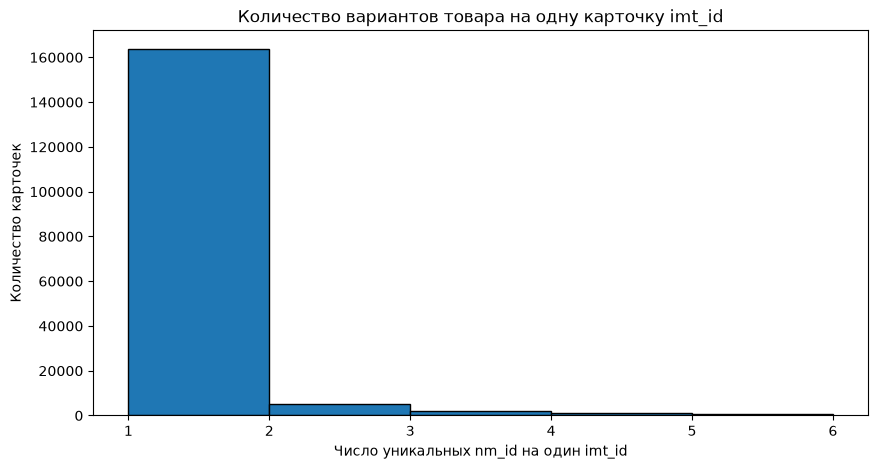

In [8]:
# Общая структура каталога
print(f"Количество строк в каталоге: {len(df_raw):,}")
print(f"Уникальных imt_id: {df_raw['imt_id'].nunique():,}")
print(f"Уникальных nm_id: {df_raw['nm_id'].nunique():,}")

# Полные дубликаты строк
full_duplicates = df_raw.duplicated().sum()
print(f"\nПолных дубликатов строк: {full_duplicates:,}")

# Повторы по imt_id
duplicated_imt_rows = df_raw.duplicated(subset="imt_id", keep=False).sum()
duplicated_imt_ids = (
    df_raw.loc[df_raw.duplicated(subset="imt_id", keep=False), "imt_id"]
    .nunique()
)

print(
    f"Строк, относящихся к повторяющимся imt_id: "
    f"{duplicated_imt_rows:,}"
)
print(
    f"Уникальных imt_id, представленных более чем одной строкой: "
    f"{duplicated_imt_ids:,}"
)

# Сколько nm_id приходится на одну карточку imt_id
variants_per_imt = (
    df_raw.groupby("imt_id")["nm_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("\nКоличество nm_id на один imt_id:")
display(
    variants_per_imt.describe(
        percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
    ).to_frame("nm_id_per_imt")
)

# Сколько карточек имеют 1, 2, 3 и более вариантов
variant_distribution = (
    variants_per_imt
    .value_counts()
    .sort_index()
    .rename_axis("nm_id_per_imt")
    .to_frame("n_imt_id")
)

display(variant_distribution.head(15))

# Примеры карточек с наибольшим числом вариантов
top_multi_imt = variants_per_imt.head(10).index

display(
    df_raw.loc[
        df_raw["imt_id"].isin(top_multi_imt),
        [
            "imt_id",
            "nm_id",
            "imt_name",
            "subj_name",
            "nm_colors_names",
            "vendor_code",
        ],
    ]
    .sort_values(["imt_id", "nm_id"])
)

# Для читаемости ограничим график 99-м перцентилем
upper_limit = variants_per_imt.quantile(0.99)

plt.figure(figsize=(10, 5))
plt.hist(
    variants_per_imt[variants_per_imt <= upper_limit],
    bins=range(
        1,
        int(upper_limit) + 2
    ),
    edgecolor="black"
)

plt.title("Количество вариантов товара на одну карточку imt_id")
plt.xlabel("Число уникальных nm_id на один imt_id")
plt.ylabel("Количество карточек")
plt.show()

Полных дубликатов строк нет, однако 10 661 `imt_id` встречается в каталоге более одного раза. Из них 10 632 карточки имеют несколько уникальных `nm_id`. У большинства карточек только один артикул, максимальное количество вариантов - 30.

Ручной просмотр примеров подтверждает, что несколько `nm_id` одного `imt_id` могут соответствовать различным цветовым вариантам одного и того же товара.

Если индексировать данные на уровне `nm_id`, один товар может несколько раз появляться в поисковой выдаче и конкурировать сам с собой. Поэтому для поискового индекса необходимо использовать более высокий уровень агрегации и исключить дублирование вариантов одного товара.

По результатам QA-сессии объект поиска должен формироваться на уровне штрихкода, объединяющего варианты товара. Следовательно, при подготовке каталога потребуется определить правило агрегации строк внутри одного объекта поиска, сохранив при этом полезные характеристики вариантов, например цвет.

**Полнота полей**

- Проверим долю пропусков в полях `description`, `nm_colors_names`, `subj_name` и `brand_name`. В текстовых признаках пропуски могут быть представлены не только как `NaN`, но и как пустые строки, поэтому учтем оба варианта. Это важно для формирования `product_text`: отсутствие описания или других атрибутов делает текстовое представление товара менее информативным и может повлиять на качество поиска:

In [9]:
# Поля, для которых проверяем полноту
fields_to_check = [
    "imt_name",
    "subj_name",
    "subj_root_name",
    "nm_colors_names",
    "vendor_code",
    "description",
    "brand_name",
]

missing_stats = []

for col in fields_to_check:
    # Пропуски NaN
    n_nan = df_raw[col].isna().sum()

    # Пустые строки с учетом пробелов
    n_empty = (
        df_raw[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )

    missing_stats.append({
        "field": col,
        "nan_count": n_nan,
        "empty_or_nan_count": n_empty,
        "empty_or_nan_share": n_empty / len(df_raw),
    })

missing_stats = pd.DataFrame(missing_stats)

display(
    missing_stats
    .sort_values("empty_or_nan_share", ascending=False)
    .assign(
        empty_or_nan_share=lambda x: (
            x["empty_or_nan_share"] * 100
        ).round(2)
    )
    .rename(columns={
        "field": "Поле",
        "nan_count": "NaN",
        "empty_or_nan_count": "Пустые или NaN",
        "empty_or_nan_share": "Доля пропусков, %",
    })
)

,Поле,NaN,Пустые или NaN,"Доля пропусков, %"
5,description,0,57509,28.75
3,nm_colors_names,0,34226,17.11
4,vendor_code,0,6646,3.32
0,imt_name,0,708,0.35
6,brand_name,0,201,0.10
2,subj_root_name,0,8,0.00
1,subj_name,0,8,0.00


In [10]:
no_description_mask = (
    df_raw["description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

print(
    f"Товаров без description: "
    f"{no_description_mask.sum():,}"
)

print(
    f"Доля товаров без description: "
    f"{no_description_mask.mean():.2%}"
)

Товаров без description: 57,509
Доля товаров без description: 28.75%


<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#d9f3f7">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> добавила в анализ пропусков <code>imt_name</code> и остальные текстовые поля каталога, чтобы проверка полноты данных охватывала все признаки.

</div>

**Проверка повторяющихся `nm_id`**

- Число уникальных `nm_id` немного меньше количества строк каталога, хотя полных дубликатов строк нет. Проверим, какие артикулы встречаются несколько раз и какими полями различаются соответствующие строки:

In [11]:
# Находим nm_id, которые встречаются более одного раза
duplicate_nm_mask = df_raw.duplicated(
    subset="nm_id",
    keep=False,
)

duplicate_nm_rows = (
    df_raw.loc[duplicate_nm_mask]
    .sort_values(["nm_id", "imt_id"])
    .copy()
)

print(
    "Строк с повторяющимися nm_id:",
    len(duplicate_nm_rows)
)

print(
    "Уникальных повторяющихся nm_id:",
    duplicate_nm_rows["nm_id"].nunique()
)

display(
    duplicate_nm_rows[
        [
            "imt_id",
            "nm_id",
            "imt_name",
            "subj_name",
            "subj_root_name",
            "nm_colors_names",
            "vendor_code",
            "description",
            "brand_name",
        ]
    ]
)

Строк с повторяющимися nm_id: 86
Уникальных повторяющихся nm_id: 43


,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
92826,10084538,11549279,"Гречка в варочных пакетах, 500г",Гречка,Продукты,,A37,Крупа гречневая ядрица. Первая в России гречне...,АРИВЕРА
92827,10084538,11549279,"Органическая гречка в варочных пакетах, 500 г",Гречка,Продукты,,A37,Гречка пропаренная АРИВЕРА БИО - это первая в ...,АРИВЕРА
133185,101226440,12009721,Серьги с бирюзой натуральной,Ювелирные серьги,Ювелирные украшения,"бирюзовый, золотистый, голубой",221684б0,"Комплектное кольцо арт. 12009720, комплектная ...",Елана
133186,101226440,12009721,Серьги с бирюзой натуральной,Ювелирные серьги,Ювелирные украшения,"золотистый, голубой, бирюзовый",221684б0,"Комплектное кольцо арт. 12009720, комплектная ...",Елана
11709,100108876,12465248,"Шпатель кондитерский ""Волны"", 13.5х10см",Шпатели кондитерские,Посуда и инвентарь,белый,1426890,Шпатель кондитерский Волны - Кулинарные принад...,Mellingward
...,...,...,...,...,...,...,...,...,...
194283,10179399,13593458,Круглая серебряная подвеска Дракон,Ювелирные подвески,Ювелирные украшения,"серый, серебристый, прозрачный",344440-0-1,Необычная подвеска с изображением дракона. Дра...,KU&KU
3311,10002899,13905038,Блузка нарядная натуральная хлопок офис,Блузки,Одежда,"бирюзовый, светло-бирюзовый",0726lu017/29,Стильная офисная блузка должна быть в гардероб...,Lu City
3312,10002899,13905038,Блузка нарядная натуральная хлопок офис,Блузки,Одежда,"светло-бирюзовый, бирюзовый",0726lu017/29,Стильная офисная блузка должна быть в гардероб...,Lu City
19943,100180483,14210892,Салфетка Гобеленовая Розы 35х45 см,Салфетки,Дом,"зеленый, голубой, красно-оранжевый, светло-беж...",TURIN2/32/45OV,Декоративная салфетка на стол Овальная из гобе...,GOBIHOME BASIC


In [12]:
# Проверяем число уникальных значений каждого поля
# внутри повторяющихся nm_id
duplicate_nm_differences = (
    duplicate_nm_rows
    .groupby("nm_id")
    .nunique(dropna=False)
)

difference_summary = (
    duplicate_nm_differences
    .gt(1)
    .sum()
    .sort_values(ascending=False)
    .rename("Количество nm_id с различиями")
    .to_frame()
)

display(difference_summary)

,Количество nm_id с различиями
description,19
nm_colors_names,19
imt_name,13
subj_name,5
subj_root_name,0
imt_id,0
vendor_code,0
brand_name,0


Проверка полноты текстовых полей показала, что стандартные `NaN` в рассматриваемых признаках отсутствуют, однако часть пропусков закодирована пустыми строками.

Наиболее существенная проблема наблюдается в `description`: описание отсутствует у 57 509 строк, что составляет 28.75% каталога. В `nm_colors_names` отсутствует 17.11% значений, в `vendor_code` - 3.32%.

Пустое `imt_name` встречается у 708 строк, или 0.35% каталога. Это важно учитывать при дальнейшей подготовке данных, поскольку название используется при формировании `product_text` и вместе с `description` определяет, можно ли сохранить карточку для поиска.

Пропуски в `brand_name` составляют 0.10%, а в `subj_name` и `subj_root_name` - менее 0.01%.

По результатам QA-сессии товары без описания нельзя исключать из каталога. Для них необходимо формировать текстовое представление из доступных информативных полей, прежде всего названия и категории. Поэтому на этапе подготовки будем удалять только карточки, у которых одновременно отсутствуют `imt_name` и `description`.

Отдельно сохраним признак наличия описания, чтобы в дальнейшем при необходимости сравнить качество поиска для товаров с полным и неполным текстовым представлением.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ключевая ловушка датасета поймана: <code>isna()</code> пропусков не видит, а они закодированы пустыми строками. Отдельно нравится, что пустые значения ищутся после <code>.str.strip()</code> - строки из одних пробелов тоже не проскочат. Распределение числа <code>nm_id</code> на карточку с перцентилями, гистограммой и примерами самых «многовариантных» карточек хорошо обосновывает выбор уровня индекса.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Две мелочи для полноты картины. Во-первых, в таблицу пропусков не попало <code>imt_name</code>, а именно оно дальше решает, удалять ли карточку (пустое название вместе с пустым описанием). Стоит добавить его, а заодно и остальные текстовые поля, чтобы таблица описывала каталог целиком. Во-вторых, строк в каталоге 200 000, а уникальных <code>nm_id</code> - 199 957, хотя полных дубликатов нет. Значит, 43 артикула встречаются дважды с разным содержимым. Посмотри, чем отличаются такие строки, - это подскажет, что за «лишние» строки лежат в каталоге и как правильнее выбирать одну из них.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> отдельно исследовала повторяющиеся <code>nm_id</code> и проверила, какими признаками различаются строки одного артикула.

</div>

In [13]:
df_raw["has_description"] = ~no_description_mask

print(
    df_raw["has_description"]
    .value_counts(normalize=True)
    .rename("share")
)

has_description
True     0.712455
False    0.287545
Name: share, dtype: float64


**Распределение по категориям**

- Проанализируем распределение товаров по корневым категориям `subj_root_name` и предметным категориям `subj_name`. Это поможет оценить однородность каталога, выделить наиболее представленные и редкие категории, а также выбрать 1-3 корневые категории для MVP:

Количество уникальных корневых категорий: 65


,Количество товаров
subj_root_name,
Одежда,43316
Аксессуары,16446
Дом,15024
Обувь,13187
Красота,9895
...,...
Игровые консоли и игры,67
Электротранспорт,47
Торговое оборудование,21


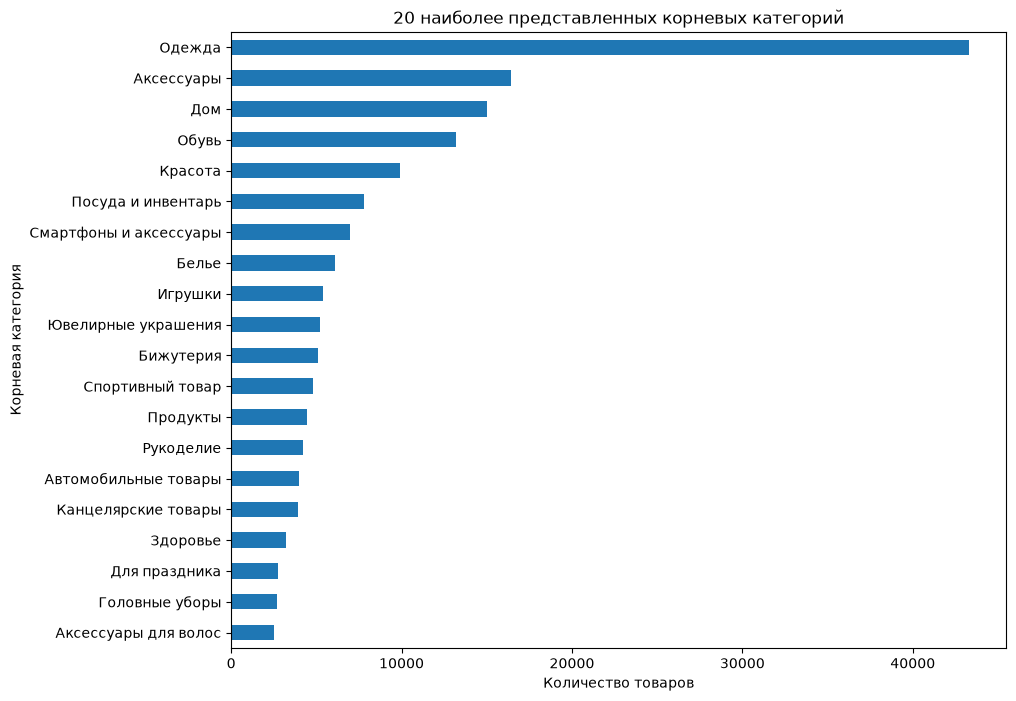

Количество уникальных предметных категорий: 3234

20 наиболее частых subj_name:


,Количество товаров
subj_name,
Платья,6998
Футболки,5465
Сумки,5215
Брюки,3427
Чехлы для телефонов,3169
Постельное белье,2457
Блузки,2342
Костюмы,2317
Автомобильные ароматизаторы,2165


Количество subj_name, представленных 1–2 товарами: 757


,Количество товаров
subj_name,
Координационные лестницы,2
Аспираторы детские,2
Видеоняни,2
Фильтры для лотков,2
Ортезы коленные,2
Багажные сетки,2
Бриджи для малышей,2
Ворота спортивные,2
Чернители шин,2


In [14]:
# Распределение по корневым категориям
root_category_counts = (
    df_raw["subj_root_name"]
    .value_counts(dropna=False)
)

print(
    "Количество уникальных корневых категорий:",
    df_raw["subj_root_name"].nunique()
)

display(
    root_category_counts
    .rename("Количество товаров")
    .to_frame()
)

# Визуализируем наиболее крупные корневые категории
plt.figure(figsize=(10, 8))

root_category_counts.head(20).sort_values().plot(
    kind="barh"
)

plt.title("20 наиболее представленных корневых категорий")
plt.xlabel("Количество товаров")
plt.ylabel("Корневая категория")
plt.show()

# Распределение по предметным категориям
subject_counts = (
    df_raw["subj_name"]
    .value_counts(dropna=False)
)

print(
    "Количество уникальных предметных категорий:",
    df_raw["subj_name"].nunique()
)

print("\n20 наиболее частых subj_name:")
display(
    subject_counts.head(20)
    .rename("Количество товаров")
    .to_frame()
)

# Посмотрим на редкие предметные категории
rare_subjects = subject_counts[subject_counts <= 2]

print(
    "Количество subj_name, представленных 1–2 товарами:",
    len(rare_subjects)
)

display(
    rare_subjects
    .rename("Количество товаров")
    .to_frame()
    .head(30)
)

Каталог содержит 65 корневых категорий и 3 234 предметные категории `subj_name`, поэтому домен данных достаточно широкий и неоднородный.

Наиболее крупной корневой категорией является `Одежда` — 43 316 товаров. Далее идут `Аксессуары`, `Дом`, `Обувь` и `Красота`. Уже на этом этапе видно, что распределение по категориям неравномерно: несколько крупных разделов содержат значительную часть каталога, тогда как некоторые корневые категории представлены лишь несколькими десятками товаров.

На уровне `subj_name` также наблюдается выраженный длинный хвост. Самые частые категории — `Платья`, `Футболки`, `Сумки`, `Брюки`, `Чехлы для телефонов`, тогда как 757 предметных категорий представлены всего одним или двумя товарами.

Редкие категории могут давать нестабильную оценку качества поиска, поэтому включать их в основной домен MVP без отдельного обоснования нецелесообразно.

Для выбора рабочего подмножества недостаточно учитывать только размер категории в каталоге. Необходимо дополнительно проверить, насколько корневые и предметные категории представлены в обучающей выборке.

- Теперь посмотрим, как категории представлены именно в обучающей разметке. Это важно для выбора рабочего домена: крупная категория в каталоге может оказаться слабо представленной в `queries_train`, и тогда оценка качества поиска по ней будет ненадежной:

In [15]:
# Связываем обучающую разметку с категориями товаров
train_with_categories = queries_train.merge(
    df_raw[
        [
            "imt_id",
            "subj_root_name",
            "subj_name",
        ]
    ].drop_duplicates("imt_id"),
    left_on="item_id",
    right_on="imt_id",
    how="left",
)

print("Корневые категории в train-разметке:")

train_root_counts = (
    train_with_categories["subj_root_name"]
    .value_counts(dropna=False)
)

display(
    train_root_counts
    .rename("Количество размеченных пар")
    .to_frame()
)

Корневые категории в train-разметке:


,Количество размеченных пар
subj_root_name,
Одежда,8150
Обувь,3303


- Дополнительно посчитаем количество уникальных запросов по каждой корневой категории. Это позволит оценить не только объем размеченных пар, но и фактическое разнообразие запросов внутри категории:

In [16]:
queries_per_root = (
    train_with_categories
    .groupby("subj_root_name")["query_id"]
    .nunique()
    .sort_values(ascending=False)
)

display(
    queries_per_root
    .rename("Уникальных query_id")
    .to_frame()
)

,Уникальных query_id
subj_root_name,
Одежда,489
Обувь,211


- Посмотрим, какие предметные категории `subj_name` чаще всего встречаются в обучающей разметке:

In [17]:
train_subject_counts = (
    train_with_categories["subj_name"]
    .value_counts(dropna=False)
)

display(
    train_subject_counts
    .head(20)
    .rename("Количество размеченных пар")
    .to_frame()
)

,Количество размеченных пар
subj_name,
Блузки,393
Джинсы,388
Футболки,378
Платья,341
Костюмы,304
Брюки,282
Туфли,280
Джемперы,274
Шубы натуральные,273


- Проверим, нет ли пустых значений в `subj_root_name`, которые могли быть закодированы пустыми строками и не попасть в стандартный подсчет `NaN`:

In [18]:
empty_root = (
    df_raw["subj_root_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

print("Пустых subj_root_name:", empty_root.sum())

Пустых subj_root_name: 8


Обучающая разметка покрывает только две корневые категории - `Одежда` и `Обувь`.

Категория `Одежда` представлена 489 уникальными запросами, а `Обувь` - 211. Таким образом, основной объем разметки приходится на одежду, однако обе категории имеют достаточное количество запросов для дальнейшего анализа и оценки качества поиска.

На уровне `subj_name` наиболее часто встречаются `Блузки`, `Джинсы`, `Футболки`, `Платья`, `Костюмы`, `Брюки`, а среди обуви - `Туфли`, `Ботинки`, `Шлепанцы`, `Полуботинки`, `Сапоги` и `Кеды`.

Поскольку обучающая разметка ограничена двумя корневыми категориями, для MVP целесообразно использовать именно `Одежду` и `Обувь`. Это позволит строить и оценивать поиск в тех доменах, для которых есть достаточное количество размеченных запросов.

Дополнительно обнаружено 8 пустых значений в `subj_root_name`, представленных пустыми строками, а не `NaN`. Эти строки необходимо учитывать при последующей очистке данных.

**Проверка категорий в обучающей и тестовой разметке**

- Дополнительно проверим корневые категории товаров из `queries_test`. Это позволит убедиться, что выбранный для MVP домен "Одежда" и "Обувь" покрывает не только обучающую, но и отложенную разметку:

In [19]:
# Объединяем уникальные товары из train и test
all_labeled_items = pd.concat(
    [
        queries_train[["item_id"]],
        queries_test[["item_id"]],
    ],
    ignore_index=True,
).drop_duplicates()

# Добавляем корневую категорию
all_labeled_categories = all_labeled_items.merge(
    df_raw[
        ["imt_id", "subj_root_name"]
    ].drop_duplicates("imt_id"),
    left_on="item_id",
    right_on="imt_id",
    how="left",
)

print("Корневые категории среди товаров train и test:")

display(
    all_labeled_categories["subj_root_name"]
    .value_counts(dropna=False)
    .rename("Количество уникальных товаров")
    .to_frame()
)

# Выбранные категории MVP
MVP_CATEGORIES = ["Одежда", "Обувь"]

# Проверяем наличие категорий вне выбранного MVP
unexpected_categories = set(
    all_labeled_categories["subj_root_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .unique()
) - set(MVP_CATEGORIES)

# Пустые значения рассматриваем отдельно
unexpected_categories.discard("")

print(
    "Категории вне MVP:",
    unexpected_categories
)

assert not unexpected_categories

Корневые категории среди товаров train и test:


,Количество уникальных товаров
subj_root_name,
Одежда,1928
Обувь,652


Категории вне MVP: set()


Проверка показала, что товары из обучающей и тестовой разметки относятся только к двум выбранным корневым категориям: "Одежда" и "Обувь". Среди уникальных размеченных товаров 1 928 относятся к одежде и 652 - к обуви.

Категорий вне выбранного домена MVP не обнаружено. Следовательно, выбранное подмножество категорий покрывает не только обучающую, но и тестовую разметку, поэтому на финальном прогоне третьей недели товары из тестовой выборки не окажутся вне поискового каталога.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Выбор категорий опирается на разметку, а не на соображение «одежда - самая большая категория»: ты проверила, где лежат размеченные товары, сколько <b>уникальных запросов</b> приходится на каждую корневую категорию и какие <code>subj_name</code> в них чаще всего встречаются. И отдельно нашла 8 пустых <code>subj_root_name</code>, которые не видны через <code>isna()</code>, - внимательно.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Покрытие категориями проверено только для train. Чтобы выбор категорий был обоснован полностью, стоит так же проверить и товары из test - иначе на финальном прогоне третьей недели часть разметки может неожиданно оказаться вне каталога. Достаточно объединить <code>item_id</code> из обеих выборок и посмотреть их корневые категории.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> дополнительно проверила категории товаров из train и test. Все размеченные товары относятся к категориям "Одежда" и "Обувь", категорий вне выбранного MVP нет.

</div>

**Длина текстовых полей**

- Изучим распределение длины `imt_name` и `description` в символах и словах. Это важно для дальнейшего выбора модели эмбеддингов и структуры `product_text`: слишком длинные описания могут обрезаться по лимиту токенов, а длинные SEO-тексты и рекламные вставки - размывать смысловое представление товара:

In [20]:
# Создаем признаки длины текста
for col in ["imt_name", "description"]:
    text = (
        df_raw[col]
        .fillna("")
        .astype(str)
    )

    df_raw[f"{col}_char_len"] = text.str.len()
    df_raw[f"{col}_word_len"] = text.str.split().str.len()

# Сводная статистика по длине названий и описаний
length_stats = df_raw[
    [
        "imt_name_char_len",
        "imt_name_word_len",
        "description_char_len",
        "description_word_len",
    ]
].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
)

display(length_stats.round(2))

,imt_name_char_len,imt_name_word_len,description_char_len,description_word_len
count,200000.00,200000.00,200000.00,200000.00
mean,32.87,4.80,372.37,50.39
std,23.96,3.64,474.56,64.59
min,0.00,0.00,0.00,0.00
50%,31.00,4.00,227.00,31.00
75%,48.00,7.00,563.00,75.00
90%,65.00,10.00,934.00,125.00
95%,80.00,12.00,1082.00,152.00
99%,97.00,15.00,2067.00,289.00
max,122.00,31.00,5000.00,754.00


- Визуализируем распределение длины названий:

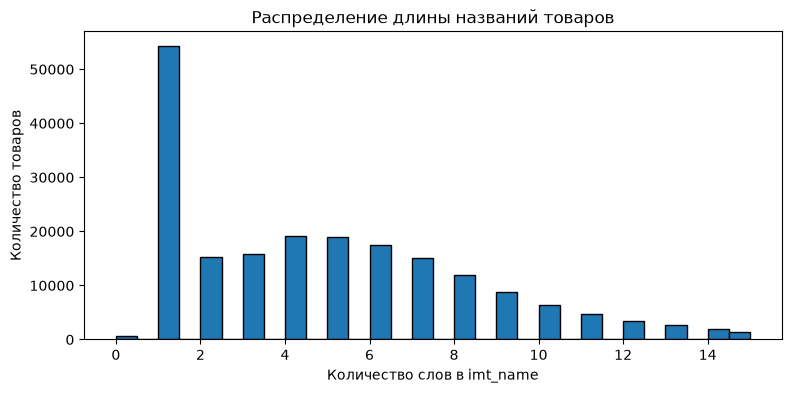

In [21]:
name_upper = df_raw["imt_name_word_len"].quantile(0.99)

plt.figure(figsize=(9, 4))
plt.hist(
    df_raw.loc[
        df_raw["imt_name_word_len"] <= name_upper,
        "imt_name_word_len"
    ],
    bins=30,
    edgecolor="black"
)

plt.title("Распределение длины названий товаров")
plt.xlabel("Количество слов в imt_name")
plt.ylabel("Количество товаров")
plt.show()

- Визуализируем распределение длины описаний:

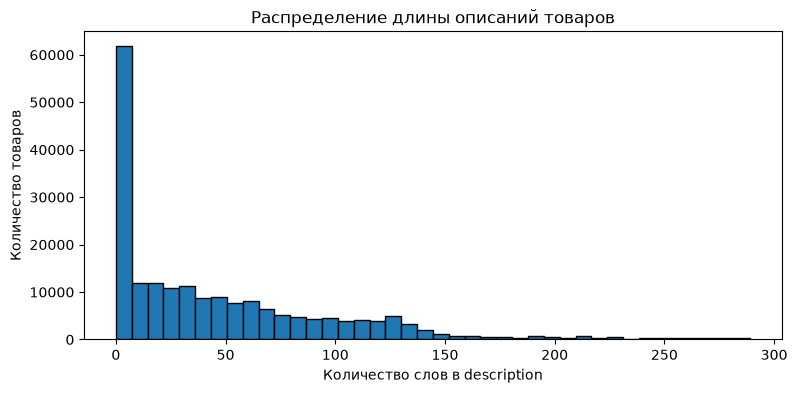

In [22]:
description_upper = df_raw["description_word_len"].quantile(0.99)

plt.figure(figsize=(9, 4))
plt.hist(
    df_raw.loc[
        df_raw["description_word_len"] <= description_upper,
        "description_word_len"
    ],
    bins=40,
    edgecolor="black"
)

plt.title("Распределение длины описаний товаров")
plt.xlabel("Количество слов в description")
plt.ylabel("Количество товаров")
plt.show()

- Отдельно рассмотрим самые длинные описания, так как они могут содержать SEO-тексты, рекламные шаблоны или другую информацию, которая не помогает семантическому поиску:

In [23]:
longest_descriptions = (
    df_raw.nlargest(
        20,
        "description_word_len"
    )[
        [
            "imt_id",
            "imt_name",
            "subj_name",
            "description_word_len",
            "description_char_len",
            "description",
        ]
    ]
)

display(longest_descriptions)

,imt_id,imt_name,subj_name,description_word_len,description_char_len,description
58042,10051447,Кружка детская Щенячий патруль,Кружки,754,4972,Представляем вашему вниманию детские лицензион...
78523,10070406,Искусственные цветы орхидея в кашпо в подарок ...,Искусственные растения,714,4874,Искусственные цветы в горшке - это прекрасное ...
78524,10070406,Искусственные цветы орхидея в кашпо в подарок ...,Искусственные растения,714,4874,Искусственные цветы в горшке - это прекрасное ...
127198,10115260,Панама детская для мальчиков,Панамы для малышей,713,5000,Летняя панамка для маленьких малышей. Отлично ...
127199,10115260,Панама детская для мальчиков,Панамы для малышей,713,5000,Летняя панамка для маленьких малышей. Отлично ...
127200,10115260,Панама детская для мальчиков,Панамы для малышей,713,5000,Летняя панамка для маленьких малышей. Отлично ...
127201,10115260,Панама детская для мальчиков,Панамы для малышей,713,5000,Летняя панамка для маленьких малышей. Отлично ...
94419,10085848,Щетка для посуды бутылок швабра с длинной ручкой,Щетки кухонные,711,4892,"Комплект для уборки: 1 щетка , 3 губки. Щетка ..."
132091,10119657,Туфли кожаные мужские туфли натуральная кожа к...,Туфли,704,4673,Классические кожаные мужские туфли Fortuna cla...
26830,10024190,Шляпа женская пляжная летняя канотье соломенная,Шляпы,701,4779,Женская шляпа пляжная – необходимый аксессуар ...


Названия товаров в целом короткие: медианная длина составляет 4 слова, а 95% названий содержат не более 12 слов. Максимальная длина названия достигает 31 слова. Это позволяет считать `imt_name` компактным и информативным текстовым признаком.

Описания заметно длиннее и имеют выраженный правый хвост. Медианная длина `description` составляет 31 слово, 95% описаний содержат не более 152 слов, а 99% — не более 289 слов. При этом максимальная длина достигает 754 слов и 5 000 символов.

Такие экстремально длинные описания могут содержать рекламные, SEO- и шаблонные фрагменты, которые не обязательно помогают семантическому поиску.

Для выбранной на неделе 2 модели `paraphrase-multilingual-MiniLM-L12-v2` максимальная длина входа составляет 128 токенов. Дополнительная проверка на подготовленном каталоге показала, что этот лимит превышают 1 210 из 4 256 `product_text`, или 28.43%. Поэтому для заметной доли карточек конец текста не участвует в формировании эмбеддинга.

Это подтверждает, что при формировании `product_text` важны не только состав, но и порядок полей: наиболее информативные признаки, прежде всего категорию и название товара, следует размещать до длинного описания.

По примерам самых длинных описаний также видно, что один и тот же `imt_id` может встречаться в нескольких строках с одинаковым текстом, что связано с вариантами товара и дополнительно подтверждает необходимость дедупликации перед построением индекса.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Длины посчитаны и в символах, и в словах, с перцентилями и гистограммами, а самые длинные описания просмотрены глазами. Хорошее наблюдение, что в топе длинных описаний повторяются одни и те же <code>imt_id</code>, - это ещё один аргумент за дедупликацию.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Вывод про ограничение длины входа модели пока звучит в общем виде. Его стоит конкретизировать: какой лимит у модели, которую ты используешь на неделе 2 (его можно посмотреть через <code>semantic_model.max_seq_length</code>), и какая доля текстов в него не помещается - токены удобно посчитать токенизатором самой модели. С такой цифрой станет понятно, теряется ли полезная часть описаний и насколько важен порядок полей в <code>product_text</code>.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> конкретизировала вывод о возможной обрезке длинных текстов: для выбранной семантической модели лимит входа составляет 128 токенов, и его превышают 28.43% подготовленных <code>product_text</code>. Дополнительно уточнила влияние этого ограничения на порядок полей в текстовом представлении товара.

</div>

**Качество текста**

- Проведем ручной анализ случайной выборки из 20-30 карточек товаров. Проверим, встречаются ли в названиях и описаниях HTML-теги, спецсимволы, служебные артикулы, рекламные и шаблонные фразы, повторяющиеся описания или текст, слабо связанный с самим товаром. Это поможет понять, какая очистка потребуется перед формированием `product_text`:

In [24]:
# Случайная выборка карточек для ручного анализа
sample_products = (
    df_raw[
        [
            "imt_id",
            "nm_id",
            "imt_name",
            "subj_name",
            "subj_root_name",
            "nm_colors_names",
            "vendor_code",
            "description",
            "brand_name",
        ]
    ]
    .sample(
        n=30,
        random_state=RANDOM_STATE
    )
)

display(sample_products)

,imt_id,nm_id,imt_name,subj_name,subj_root_name,nm_colors_names,vendor_code,description,brand_name
119737,10108023,6277206,Набор гель-блестки для тела с кисточкой,Глиттеры,Красота,"глубокий пурпурный, синий",Т11929,Lucky набор гель-блестки д тела/лица х3 шт + к...,LUKKY
72272,10064796,13439504,Пирсинг для пупка серебро 925 проба,Ювелирный пирсинг,Ювелирные украшения,серебристый,81035001239938103500123993,Изделие выполнено из серебра 925 пробы; покрыт...,RICH LINE
158154,10147294,13550892,Чехол на Samsung Galaxy M21 / M30s / M31,Чехлы для телефонов,Смартфоны и аксессуары,оранжевый,9331-orange,Противоударный чехол отлично защищает смартфон...,Kupicase
65426,10058577,13430914,Набор стикеров Аниме Naruto (Наруто),Стикеры,Канцелярские товары,белый,1111798Белый,В набор входит 63 стикера. Стикеры можно клеит...,FANDOM
30074,10027164,13388001,Контактные линзы Pure Vision 2 (6 линз) R 8.6 ...,Контактные линзы,Здоровье,,252121453100,В этих одномесячных линзах идеально сочетаются...,Bausch+Lomb
23677,10021271,13379371,"Головка 1/2"" DR со вставкой TORX T70 длиной 10...",Головки торцевые,Строительные инструменты,,AT-BS-31,Инструменты соответствуют высоким стандартам к...,Airline
134858,10126692,13522489,"Сумка для ноутбука 13.3"" с косметичкой",Сумки для ноутбуков,Аксессуары,черный,19090005,В комплекте: Сумка для ноутбука + косметичка.\...,skyka
176418,10163716,13572673,Чехол на XIAOMI 9T / Силиконовый Матовый Проти...,Чехлы для телефонов,Смартфоны и аксессуары,прозрачный,74000011/00,Легкий минималистичный кейс не только украсит ...,HaruCase
132467,10120372,13515423,Спортивные брюки,Брюки,Одежда,темно-синий,MR-2058Aтемно-синий,,SCORE BOARD
4082,10003470,13354698,Чехол для телефона,Чехлы для телефонов,Смартфоны и аксессуары,серый,B000032APP/col,,Bee's Knees


- Дополнительно проверим наиболее очевидные технические признаки загрязнения текста: наличие HTML-тегов и некоторых спецсимволов в `imt_name` и `description`:

In [25]:
# Простейшая проверка наличия HTML-тегов
html_pattern = r"<[^>]+>"

for col in ["imt_name", "description"]:
    html_count = (
        df_raw[col]
        .fillna("")
        .astype(str)
        .str.contains(html_pattern, regex=True)
        .sum()
    )

    print(
        f"{col}: строк с признаками HTML-разметки — "
        f"{html_count:,}"
    )

# Проверка наличия переводов строк и табуляции
for col in ["imt_name", "description"]:
    linebreak_count = (
        df_raw[col]
        .fillna("")
        .astype(str)
        .str.contains(r"[\n\r\t]", regex=True)
        .sum()
    )

    print(
        f"{col}: строк с переносами или табуляцией — "
        f"{linebreak_count:,}"
    )

imt_name: строк с признаками HTML-разметки — 0
description: строк с признаками HTML-разметки — 22
imt_name: строк с переносами или табуляцией — 80
description: строк с переносами или табуляцией — 22,314


- Посмотрим также, насколько часто одинаковые описания повторяются у разных строк каталога, так как повторяющийся шаблонный текст может добавлять шум и снижать информативность эмбеддингов:

In [26]:
# Повторяющиеся непустые описания
non_empty_descriptions = (
    df_raw.loc[
        df_raw["description"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne(""),
        "description"
    ]
)

description_counts = non_empty_descriptions.value_counts()

print(
    "Уникальных непустых description:",
    f"{non_empty_descriptions.nunique():,}"
)

print(
    "Описаний, встречающихся более одного раза:",
    f"{(description_counts > 1).sum():,}"
)

print(
    "Максимальное число повторов одного description:",
    f"{description_counts.max():,}"
)

# Посмотрим примеры наиболее часто повторяющихся описаний
display(
    description_counts
    .head(10)
    .rename("Количество повторов")
    .to_frame()
)

Уникальных непустых description: 88,796
Описаний, встречающихся более одного раза: 14,868
Максимальное число повторов одного description: 218


,Количество повторов
description,
"Коврики изготовлены именно для Вашего автомобиля , полностью повторяют форму пола, на 100% защищая его от грязи. Не промокают. Европейский материалы. Максимальный комфорт и уют. Не промокают. Гарантия 2 года. Текстильные коврики не скользят по полу за счет штатных оригинальных креплений. Есть коврики на все модели.",218
Проект Автоистория - это модели автомобилей в масштабе по демократичным ценам. Продукция проходит обязательную сертификацию и соответствует ГОСТ 25779-90. Товарные знаки используются с разрешения правообладателей.,181
Гарантийный срок товара 30 дней.,166
"Не спешите писать негативный отзыв при следующих ситуациях, независящих от нас: 1. Доставка задержалась или качество обслуживания в пункте выдачи не оправдало Ваших ожиданий. В данном случае напишите в техподдержку для оперативного решения. 2. Товар пришел поврежденным. Вы вправе отказаться от покупки и/или оформить возврат по браку. Товар спишут и утилизируют за наши средства, несмотря на вину доставщика/курьера, а Вам вернут денежные средства. 3. Пришел абсолютно другой товар. Пересортица товаров может происходить на складе. К сожалению, мы никак не можем повлиять на работу отдельных сотрудников марткеплейса, как бы этого не хотели. В данном случае необходимо оформить возврат, написать в техподдержку. С уважением, Ваш kari.",152
"Полотенцесушитель водяной от производителя Терминус представляет собой оригинальную модификацию устройства форм-фактора ""Лесенка"". Конструкция устройства позволит разместить на нём большое количество вещей для просушки и придаст помещению элегантности, дополнив его стильным аксессуаром.",150
"Защищает от воздействия окружающей среды и одновременно является аксессуаром. Маска многоразовая, можно стирать. Не является медицинским изделием, ее рекомендуется носить поверх медицинской маски. Материал: полиэстер, хлопок.",148
"Очки для зрения женские являются неотъемлемой частью образа современной женщины. Наш магазин предлагает Вам легкие и стильные очки, которые помогут не только корректировать зрение, но и стать настоящим аксессуаром модного образа. Особенности данного товара включают в себя дизайн, который отличается изящностью и элегантностью. Легкая пластиковая оправа изготовлена из прочного материала, что обеспечивает комфортное ношение на протяжении всего дня. Очки корригирующие обеспечивают ясное и четкое видение, благодаря чему Вы сможете наслаждаться чтением или любыми другими ежедневными задачами. Мы предлагаем широкий ассортимент моделей и цветов, чтобы Вы смогли подобрать очки, которые будут соответствовать Вашему индивидуальному стилю и предпочтениям. Заказав очки для зрения в нашем интернет-магазине, Вы получите высококачественный продукт, который поможет Вам исправить зрение и стать еще красивее.",145
"Матовый силиконовый чехол TELEPRO Matte Silicone отличное дополнение к Вашему смартфону. Приятная на ощупь, нескользящая поверхность практична в использовании, она более устойчива к царапинам и потертостям и на ней не видны отпечатки пальцев. Подходит для беспроводной зарядки.",140
"Водяной полотенцесушитель Grota много лет пользуется застуженной популярностью. Он характеризуется исключительной надёжностью, которая гарантирует многолетнюю эксплуатацию полотенцесушителя, в течении которой у Вас не возникнет с ним малейших проблем. Радиатор сочетает исключительно высокие эксплуатационные и эстетические характеристики, что превращает его в идеальное дизайнерское дополнение ванной или другой комнаты.",140


HTML-разметка встречается редко: 22 строки в `description`, в названиях таких случаев нет. Переносы строк и табуляция обнаружены в 22 314 описаниях.

Из 88 796 уникальных непустых описаний 14 868 повторяются более одного раза. Среди наиболее частых повторов встречаются гарантийные сообщения, инструкции по возврату и общие рекламные формулировки.

Перед индексацией потребуется убрать HTML и нормализовать пробелы. Размеры, номера моделей и другие технические характеристики автоматически удалять не будем, поскольку они могут быть полезны для поиска.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Ручной просмотр выборки дополнен проверками конкретных проблем: HTML, переносы строк, повторяющиеся описания. Особенно нравится решение не вычищать автоматически размеры, номера моделей и артикулы - грубая чистка «всего с цифрами» легко срезала бы токены, по которым пользователь как раз и ищет. А найденные шаблонные тексты («Гарантийный срок товара 30 дней», «Не спешите писать негативный отзыв...») - хороший кандидат для гипотезы на третьей неделе.
</div>

**Атрибуты: бренд и цвет**

- Проанализируем признаки `brand_name` и `nm_colors_names`. Для бренда оценим число уникальных значений и полноту заполнения, а для цвета дополнительно проверим, как часто информация из `nm_colors_names` уже встречается в названии товара. Это поможет понять, стоит ли включать эти атрибуты в `product_text` или оставить их вне семантического представления:

In [27]:
# Общая статистика по брендам
brand_series = (
    df_raw["brand_name"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print(
    "Количество уникальных непустых брендов:",
    brand_series[brand_series.ne("")].nunique()
)

print(
    "Доля пустых brand_name:",
    f"{brand_series.eq('').mean():.2%}"
)

display(
    brand_series[brand_series.ne("")]
    .value_counts()
    .head(20)
    .rename("Количество товаров")
    .to_frame()
)

Количество уникальных непустых брендов: 13318
Доля пустых brand_name: 0.10%


,Количество товаров
brand_name,
Airline,2691
Сималенд,1617
KOTON,1362
Pavone,1235
PUMA,1143
Сказка.,1080
Disney,1012
TDM ELECTRIC,922
TOM TAILOR,900


- Теперь посмотрим на заполненность и наиболее частые значения цвета:

In [28]:
# Общая статистика по цвету
color_series = (
    df_raw["nm_colors_names"]
    .fillna("")
    .astype(str)
    .str.strip()
)

print(
    "Количество уникальных непустых значений nm_colors_names:",
    color_series[color_series.ne("")].nunique()
)

print(
    "Доля пустых nm_colors_names:",
    f"{color_series.eq('').mean():.2%}"
)

display(
    color_series[color_series.ne("")]
    .value_counts()
    .head(20)
    .rename("Количество товаров")
    .to_frame()
)

Количество уникальных непустых значений nm_colors_names: 9646
Доля пустых nm_colors_names: 17.11%


,Количество товаров
nm_colors_names,
черный,22242
белый,15467
синий,7918
серебристый,6429
серый,6143
розовый,5787
красный,5663
бежевый,5582
голубой,4292


- Проверим, насколько часто цвет из `nm_colors_names` уже упомянут в `imt_name`. Если цвет систематически дублируется в названии, его отдельное добавление в `product_text` может быть избыточным:

In [29]:
def color_mentioned_in_name(row):
    """Проверяет, встречается ли хотя бы один цвет из nm_colors_names в названии."""

    name = str(row["imt_name"]).lower().strip()

    colors = str(row["nm_colors_names"]).lower().strip()

    if not colors:
        return False

    color_list = [
        color.strip()
        for color in colors.split(",")
        if color.strip()
    ]

    return any(
        color in name
        for color in color_list
    )


df_raw["color_in_name"] = df_raw.apply(
    color_mentioned_in_name,
    axis=1
)

has_color = color_series.ne("")

print(
    "Доля строк с указанным цветом, где цвет уже встречается в названии:",
    f"{df_raw.loc[has_color, 'color_in_name'].mean():.2%}"
)

Доля строк с указанным цветом, где цвет уже встречается в названии: 2.66%


- Дополнительно посмотрим примеры товаров, где цвет указан в атрибуте, но отсутствует в названии. Именно для таких карточек `nm_colors_names` потенциально может добавлять полезную информацию в `product_text`:

In [30]:
display(
    df_raw.loc[
        has_color & ~df_raw["color_in_name"],
        [
            "imt_id",
            "nm_id",
            "imt_name",
            "subj_name",
            "nm_colors_names",
        ]
    ].head(30)
)

,imt_id,nm_id,imt_name,subj_name,nm_colors_names
0,100000,118982,Сумка,Сумки,бежевый
1,1000000,1206857,Шапка,Шапки,белый
2,1000000,1206860,Шапка,Шапки,черный
3,10000000,13349975,Очки TRUESPIN Fold,Солнцезащитные очки,черный
4,10000001,13349981,Очки TRUESPIN Candor,Солнцезащитные очки,черный
5,10000002,13349976,Очки TRUESPIN Candor Art,Солнцезащитные очки,черный
6,10000002,13349977,Очки TRUESPIN Candor Art,Солнцезащитные очки,белый
7,10000003,13349978,Очки TRUESPIN Petrichor,Солнцезащитные очки,черный
8,10000003,13349979,Очки TRUESPIN Petrichor,Солнцезащитные очки,розовый
9,10000003,13349980,Очки TRUESPIN Petrichor,Солнцезащитные очки,прозрачный


Анализ атрибутов показал, что в каталоге представлено 13 318 уникальных непустых значений `brand_name`. Поле практически полностью заполнено: доля пустых значений составляет всего 0.1%.

При этом по результатам QA-сессии бренд не должен влиять на семантическую поисковую выдачу, поэтому `brand_name` не будет включаться в `product_text`.

Для `nm_colors_names` обнаружено 9 646 уникальных непустых значений. Наиболее распространены черный, белый, синий, серебристый и серый цвета. Доля пропусков составляет 17.1%.

Проверка дублирования цвета показала, что только в 2.7% строк с заполненным `nm_colors_names` хотя бы один указанный цвет встречается в названии товара. Таким образом, информация о цвете в большинстве случаев отсутствует в `imt_name` и потенциально может дополнять текстовое представление товара.

С учетом требований заказчика цвет имеет смысл рассмотреть как дополнительный компонент `product_text`, поскольку пользователь может указывать его непосредственно в поисковом запросе. При этом необходимо учитывать, что разные цветовые варианты одного товара не должны формировать отдельные объекты поисковой выдачи.

Предварительное решение - не включать `brand_name` в семантическое представление, а полезность `nm_colors_names` проверить экспериментально, сравнив качество поиска с учетом цвета и без него.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Бренд и цвет проанализированы с цифрами, а не «на глаз». Проверка того, как часто цвет уже есть в названии, - убедительный аргумент рассматривать его отдельным полем, а решение не включать цвет сразу, а проверить его экспериментально, - ровно тот подход, который нужен. Небольшое наблюдение на будущее: сравнение по точной строке не засчитает «черная» при цвете «черный», так что 2.66% - оценка снизу. Если сравнивать по основе слова, доля немного вырастет, но вывод от этого не изменится.
</div>

**Размер и структура обучающей разметки**

- Исследуем структуру `queries_train`: посчитаем количество пар «запрос — товар», число уникальных запросов и товаров, а также проверим, сколько оцененных товаров приходится на один запрос, чтобы понять полноту разметки и учесть ее ограничения при дальнейшем расчете поисковых метрик:

In [31]:
# Общая статистика обучающей разметки
print(f"Количество пар query-item: {len(queries_train):,}")
print(f"Уникальных query_id: {queries_train['query_id'].nunique():,}")
print(f"Уникальных query_text: {queries_train['query_text'].nunique():,}")
print(f"Уникальных item_id: {queries_train['item_id'].nunique():,}")

# Проверим повторяющиеся пары query-item
duplicate_pairs = queries_train.duplicated(
    subset=["query_id", "item_id"]
).sum()

print(f"\nПовторяющихся пар query-item: {duplicate_pairs:,}")

Количество пар query-item: 11,453
Уникальных query_id: 700
Уникальных query_text: 700
Уникальных item_id: 2,285

Повторяющихся пар query-item: 0


- Посмотрим распределение числа оцененных товаров на один запрос. Особое внимание уделим минимальному, медианному и максимальному количеству оценок, поскольку ограниченная разметка может влиять на интерпретацию `Precision@K` и `Recall@K`:

In [32]:
# Количество уникальных оцененных товаров на один запрос
items_per_query = (
    queries_train
    .groupby("query_id")["item_id"]
    .nunique()
)

display(
    items_per_query.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
    .to_frame("items_per_query")
)

,items_per_query
count,700.00
mean,16.36
std,5.42
min,1.00
25%,14.00
50%,16.00
75%,19.00
90%,23.00
95%,26.00
99%,30.00


- Визуализируем распределение количества оцененных товаров на один запрос, чтобы проверить, насколько равномерно представлена разметка и есть ли запросы с аномально большим или малым числом оценок:

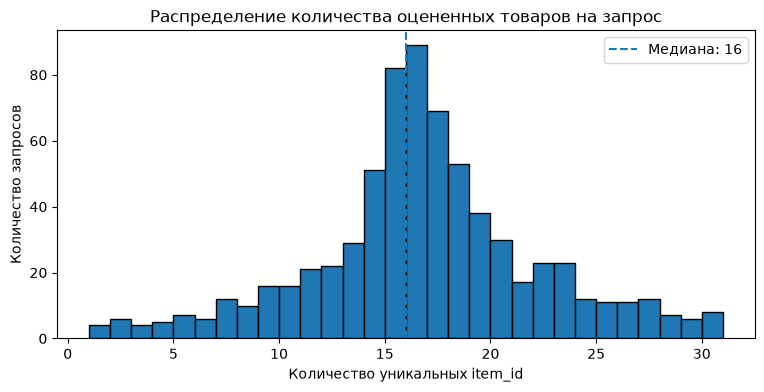

In [33]:
plt.figure(figsize=(9, 4))

plt.hist(
    items_per_query,
    bins=30,
    edgecolor="black"
)

plt.axvline(
    items_per_query.median(),
    linestyle="--",
    label=f"Медиана: {items_per_query.median():.0f}"
)

plt.title("Распределение количества оцененных товаров на запрос")
plt.xlabel("Количество уникальных item_id")
plt.ylabel("Количество запросов")
plt.legend()

plt.show()

- Дополнительно рассмотрим запросы с наименьшим и наибольшим количеством оцененных товаров, чтобы выявить возможные ограничения разметки, которые потребуется учитывать при оценке качества поиска:

In [34]:
# Добавляем тексты запросов для интерпретации
query_text_map = (
    queries_train
    .drop_duplicates("query_id")
    .set_index("query_id")["query_text"]
)

query_stats = (
    items_per_query
    .rename("n_items")
    .to_frame()
)

query_stats["query_text"] = query_text_map

print("Запросы с наименьшим количеством оцененных товаров:")
display(
    query_stats
    .sort_values("n_items")
    .head(10)
)

print("\nЗапросы с наибольшим количеством оцененных товаров:")
display(
    query_stats
    .sort_values("n_items", ascending=False)
    .head(10)
)

Запросы с наименьшим количеством оцененных товаров:


,n_items,query_text
query_id,,
SYN_000397,1,костюмы volleylife
SYN_000375,1,килты банные копмлет
SYN_000949,1,водолазки союзтрикотаж
SYN_000191,1,полуботинки gino rossi
SYN_000915,2,анораки train xtreme
SYN_000060,2,валенки на пуговицах
SYN_000537,2,ref mubb
SYN_000391,2,кроссовки nike
SYN_000303,2,классические кожаные топсайдеры



Запросы с наибольшим количеством оцененных товаров:


,n_items,query_text
query_id,,
SYN_000845,31,дышащий костюмы
SYN_000366,31,хлопковые футболки
SYN_000197,30,белые хлопковые футболки
SYN_000433,30,футболки с нашивкой
SYN_000329,30,хлопковые пижамы
SYN_000359,30,прямые хлопковые футболки
SYN_000519,30,синие джинсы
SYN_000373,30,женские платья
SYN_000908,29,трикотажные платья


Обучающая разметка содержит 11 453 пары "запрос - товар", соответствующие 700 уникальным запросам и 2 285 уникальным товарам (`item_id`). Повторяющихся пар `query_id`-`item_id` не обнаружено, что подтверждает отсутствие дублирования оценок внутри одного запроса.

В среднем на один запрос приходится 16.36 оцененного товара, медиана составляет 16. Для 50% запросов количество оцененных товаров находится в диапазоне от 14 до 19. При этом минимальное количество оценок на запрос равно 1, а максимальное - 31.

Распределение сосредоточено преимущественно вокруг 15-19 товаров, но имеет отдельные крайние случаи. Например, запросы "костюмы volleylife", "водолазки союзтрикотаж" и "полуботинки gino rossi" содержат только одну оцененную пару. Напротив, для запросов "дышащий костюмы" и "хлопковые футболки" размечено по 31 товару.

Это необходимо учитывать при последующей оценке качества поиска: разметка не является полной для всего каталога, а количество известных релевантных товаров различается между запросами. Отсутствие оценки у найденного товара само по себе не означает его нерелевантность. Способ учета неразмеченных товаров потребуется зафиксировать перед расчетом метрик.

**Распределение оценок релевантности**

- Изучим распределение значений `relevance` в обучающей разметке: проверим, какие уровни релевантности фактически присутствуют в данных, насколько равномерно они представлены и сколько запросов содержат оценки каждого уровня (это необходимо для дальнейшего выбора метрик и определения того, какие оценки будут считаться релевантными при расчете бинарных показателей качества):

,Количество пар,"Доля, %"
relevance,,
1,9652,84.27
2,1101,9.61
3,700,6.11


Фактические значения relevance: [np.int64(1), np.int64(2), np.int64(3)]


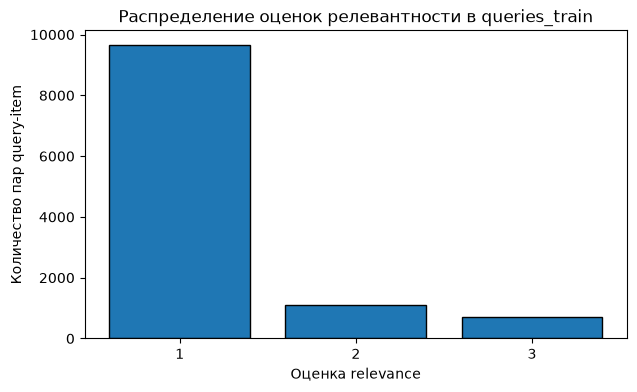

In [35]:
# Распределение оценок relevance
relevance_counts = (
    queries_train["relevance"]
    .value_counts()
    .sort_index()
)

relevance_distribution = pd.DataFrame({
    "Количество пар": relevance_counts,
    "Доля, %": (
        relevance_counts / len(queries_train) * 100
    ).round(2)
})

display(relevance_distribution)

print(
    "Фактические значения relevance:",
    sorted(queries_train["relevance"].unique())
)

plt.figure(figsize=(7, 4))

plt.bar(
    relevance_counts.index.astype(str),
    relevance_counts.values,
    edgecolor="black"
)

plt.title("Распределение оценок релевантности в queries_train")
plt.xlabel("Оценка relevance")
plt.ylabel("Количество пар query-item")

plt.show()

- Дополнительно проверим, для скольких уникальных запросов встречается каждый уровень `relevance`, чтобы понять, насколько разнообразно представлены оценки внутри обучающей выборки:

In [36]:
# Количество уникальных запросов для каждого уровня relevance
queries_by_relevance = (
    queries_train
    .groupby("relevance")["query_id"]
    .nunique()
    .sort_index()
)

display(
    queries_by_relevance
    .rename("Количество уникальных query_id")
    .to_frame()
)

,Количество уникальных query_id
relevance,
1,691
2,346
3,700


В обучающей разметке фактически присутствуют три уровня релевантности: `1`, `2` и `3`. Оценка `0`, предусмотренная исходной спецификацией, в данных не встречается.

Распределение оценок выраженно несбалансированное:
- `relevance = 1`: 9 652 пары (84.27%);
- `relevance = 2`: 1 101 пара (9.61%);
- `relevance = 3`: 700 пар (6.11%).

Оценка `1` преобладает в обучающей выборке. При этом максимальная оценка `3` встречается для всех 700 уникальных запросов, оценка `2` - для 346 запросов, а оценка `1` - для 691 запроса.

Количество пар с `relevance = 3` совпадает с количеством уникальных запросов. С учетом того, что оценка `3` встречается для всех 700 запросов, можно сделать вывод, что каждому запросу соответствует ровно один товар с максимальной оценкой релевантности.

Это необходимо учитывать при оценке качества поиска. Например, при строгом определении релевантности только через `relevance = 3` для каждого запроса будет существовать один известный максимально релевантный товар.

Для метрик с градуированной релевантностью, таких как `NDCG@K`, можно использовать исходные оценки. Для бинарных метрик порог релевантности необходимо зафиксировать до начала экспериментов. При этом отсутствие оценки у товара не следует автоматически считать доказательством его нерелевантности.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Анализ разметки выполнен отлично. Ты заметила, что оценки 0 в данных нет, что у каждого запроса ровно один товар с оценкой 3, нашла запросы всего с одной оценённой парой и сделала главный вывод: отсутствие оценки не означает нерелевантность. Это понимание дальше защищает от неверной интерпретации метрик.
</div>

**Анализ поисковых запросов**

- Проанализируем длину поисковых запросов в словах и символах, а также рассмотрим примеры из обучающей выборки, чтобы определить особенности пользовательских формулировок и учесть их при подготовке текстового представления товаров:

,query_char_len,query_word_len
count,700.00,700.0
mean,19.44,2.7
std,6.50,0.9
min,8.00,2.0
25%,15.00,2.0
50%,18.00,2.0
75%,23.00,3.0
90%,29.00,4.0
95%,32.00,4.0
99%,39.00,6.0


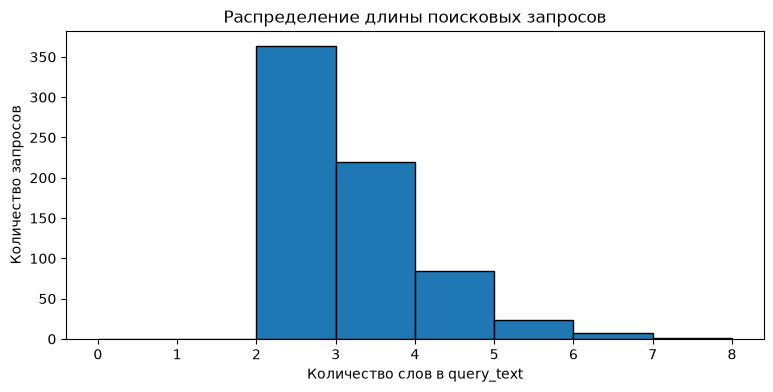

In [37]:
# Получаем уникальные поисковые запросы
unique_queries = (
    queries_train[
        ["query_id", "query_text"]
    ]
    .drop_duplicates("query_id")
    .copy()
)

# Рассчитываем длину запросов
query_text = (
    unique_queries["query_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

unique_queries["query_char_len"] = query_text.str.len()
unique_queries["query_word_len"] = query_text.str.split().str.len()

display(
    unique_queries[
        ["query_char_len", "query_word_len"]
    ].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    ).round(2)
)

plt.figure(figsize=(9, 4))

plt.hist(
    unique_queries["query_word_len"],
    bins=range(
        0,
        int(unique_queries["query_word_len"].max()) + 2
    ),
    edgecolor="black"
)

plt.title("Распределение длины поисковых запросов")
plt.xlabel("Количество слов в query_text")
plt.ylabel("Количество запросов")

plt.show()

- Рассмотрим случайные примеры запросов, а также наиболее длинные формулировки. Отдельно обратим внимание на наличие характеристик, цветов, брендов, моделей и возможных опечаток:

In [38]:
print("Случайные поисковые запросы:")

display(
    unique_queries[
        ["query_id", "query_text", "query_word_len"]
    ].sample(
        n=30,
        random_state=42
    )
)

print("\nСамые длинные поисковые запросы:")

display(
    unique_queries.nlargest(
        15,
        "query_word_len"
    )[
        ["query_id", "query_text", "query_word_len"]
    ]
)

Случайные поисковые запросы:


,query_id,query_text,query_word_len
2484,SYN_000210,топы cop copine,3
8139,SYN_000714,худи mego as,3
6376,SYN_000561,бриджи зуавы,2
2446,SYN_000206,кожаные мокасины,2
5214,SYN_000450,кожаные сабо с открытым мысом,5
3373,SYN_000286,классические джинсовые джинсы,3
3746,SYN_000318,шубы натуральные на пуговицах,4
4678,SYN_000401,тапочки asd,2
4852,SYN_000414,тапочки t taccardi,3
5737,SYN_000505,кигуруми londe,2



Самые длинные поисковые запросы:


,query_id,query_text,query_word_len
8468,SYN_000741,шубы натуральные с норковой отделкой метелица юга,7
1551,SYN_000137,крестильные комплекты с кружевом мастерская по...,6
3727,SYN_000317,шубы натуральные с капюшоном премиум furs,6
3764,SYN_000319,шубы натуральные из овчины feliz furs,6
3817,SYN_000322,шубы натуральные из овчины adam furs,6
3835,SYN_000323,шубы натуральные с капюшоном adam furs,6
5263,SYN_000454,халаты домашние в роддом для беременных,6
9142,SYN_000796,ботильоны с меховой подкладкой alla pugachova,6
1159,SYN_000102,джинсы для беременных скинни denigma,5
3629,SYN_000309,слипоны на шнурках valen ki,5


Поисковые запросы в обучающей выборке преимущественно короткие. Средняя длина составляет примерно 3 слова и 19 символов, медианная - 2 слова и 18 символов. При этом 95% запросов содержат не более 4 слов, а максимальная длина достигает 7 слов и 50 символов.

Анализ случайных примеров показал, что запросы чаще всего включают название предметной категории и одну или несколько дополнительных характеристик товара.

Встречаются следующие типы формулировок:
- предметные запросы с указанием характеристик: «кожаные мокасины», «джеггинсы утягивающие», «мужские резиновые сапоги»;
- запросы с цветом: «белые классические кеды», «бирюзовые шифоновые пуловеры»;
- запросы с материалом, фасоном или конструктивными особенностями: «шубы натуральные на пуговицах», «полусапожки на каблуке», «кожаные балетки с ремешком»;
- запросы с упоминанием брендов: «топы cop copine», «пальто crockid», «джемперы gant»;
- более подробные запросы с несколькими условиями: «халаты домашние в роддом для беременных», «шубы натуральные с норковой отделкой метелица юга».

Поскольку большинство запросов состоит из 2-4 слов, для качественного поиска важно, чтобы текстовое представление товара содержало не только `imt_name`, но и дополнительные смысловые характеристики из описания и категории.

Отдельно стоит учитывать, что часть запросов содержит названия брендов. Однако в соответствии с требованиями заказчика `brand_name` не будет добавляться в семантическое представление товара.

**Выбор структуры product_text**

- На основании результатов EDA рассмотрим несколько вариантов текстового представления товара для семантического поиска.

Анализ показал, что названия товаров преимущественно короткие, а поисковые запросы часто содержат дополнительные характеристики: материал, фасон, назначение и цвет. Поэтому использование только `imt_name` может ограничивать полноту смыслового представления товара.

Сравним три варианта:

- **A:** `imt_name` - минимальное представление на основе названия;
- **B:** `subj_name` + `imt_name` + `description` - название, предметная категория и описание;
- **C:** `subj_name` + `imt_name` + `description` + `nm_colors_names` - дополнительно учитывается цвет.

На данном этапе сравним структуру и содержимое полученных текстов. Окончательная полезность отдельных компонентов будет проверяться экспериментально при сравнении поисковых подходов.

- Для предварительного формирования `product_text` используем простую нормализацию: удалим HTML-разметку, заменим переносы строк и повторяющиеся пробелы. Содержательные характеристики, модели, размеры и артикулы автоматически удалять не будем, так как они могут быть полезны для поиска:

In [39]:
def normalize_product_field(value):
    """Базовая нормализация текстового поля."""

    if pd.isna(value):
        return ""

    text = str(value).strip()

    # Преобразование HTML-сущностей
    text = html.unescape(text)

    # Удаление HTML-тегов
    text = re.sub(r"<[^>]+>", " ", text)

    # Нормализация пробельных символов
    text = re.sub(r"\s+", " ", text)

    return text.strip()


def build_product_text(row, columns):
    """Объединяет выбранные непустые поля товара."""

    parts = [
        normalize_product_field(row[col])
        for col in columns
    ]

    return " ".join(
        part for part in parts if part
    )

- Сформируем три варианта `product_text` на случайной выборке карточек и сравним их содержимое. Это позволит визуально оценить вклад категории, описания и цвета в итоговое текстовое представление:

In [40]:
# Случайная выборка карточек для сравнения
product_text_sample = df_raw.sample(
    n=10,
    random_state=42
).copy()

# Вариант A: только название
product_text_sample["product_text_A"] = product_text_sample.apply(
    lambda row: build_product_text(
        row,
        ["imt_name"]
    ),
    axis=1
)

# Вариант B: категория + название + описание
product_text_sample["product_text_B"] = product_text_sample.apply(
    lambda row: build_product_text(
        row,
        ["subj_name", "imt_name", "description"]
    ),
    axis=1
)

# Вариант C: категория + название + описание + цвет
product_text_sample["product_text_C"] = product_text_sample.apply(
    lambda row: build_product_text(
        row,
        [
            "subj_name",
            "imt_name",
            "description",
            "nm_colors_names",
        ]
    ),
    axis=1
)

display(
    product_text_sample[
        [
            "imt_id",
            "imt_name",
            "product_text_A",
            "product_text_B",
            "product_text_C",
        ]
    ]
)

,imt_id,imt_name,product_text_A,product_text_B,product_text_C
119737,10108023,Набор гель-блестки для тела с кисточкой,Набор гель-блестки для тела с кисточкой,Глиттеры Набор гель-блестки для тела с кисточк...,Глиттеры Набор гель-блестки для тела с кисточк...
72272,10064796,Пирсинг для пупка серебро 925 проба,Пирсинг для пупка серебро 925 проба,Ювелирный пирсинг Пирсинг для пупка серебро 92...,Ювелирный пирсинг Пирсинг для пупка серебро 92...
158154,10147294,Чехол на Samsung Galaxy M21 / M30s / M31,Чехол на Samsung Galaxy M21 / M30s / M31,Чехлы для телефонов Чехол на Samsung Galaxy M2...,Чехлы для телефонов Чехол на Samsung Galaxy M2...
65426,10058577,Набор стикеров Аниме Naruto (Наруто),Набор стикеров Аниме Naruto (Наруто),Стикеры Набор стикеров Аниме Naruto (Наруто) В...,Стикеры Набор стикеров Аниме Naruto (Наруто) В...
30074,10027164,Контактные линзы Pure Vision 2 (6 линз) R 8.6 ...,Контактные линзы Pure Vision 2 (6 линз) R 8.6 ...,Контактные линзы Контактные линзы Pure Vision ...,Контактные линзы Контактные линзы Pure Vision ...
23677,10021271,"Головка 1/2"" DR со вставкой TORX T70 длиной 10...","Головка 1/2"" DR со вставкой TORX T70 длиной 10...","Головки торцевые Головка 1/2"" DR со вставкой T...","Головки торцевые Головка 1/2"" DR со вставкой T..."
134858,10126692,"Сумка для ноутбука 13.3"" с косметичкой","Сумка для ноутбука 13.3"" с косметичкой","Сумки для ноутбуков Сумка для ноутбука 13.3"" с...","Сумки для ноутбуков Сумка для ноутбука 13.3"" с..."
176418,10163716,Чехол на XIAOMI 9T / Силиконовый Матовый Проти...,Чехол на XIAOMI 9T / Силиконовый Матовый Проти...,Чехлы для телефонов Чехол на XIAOMI 9T / Силик...,Чехлы для телефонов Чехол на XIAOMI 9T / Силик...
132467,10120372,Спортивные брюки,Спортивные брюки,Брюки Спортивные брюки,Брюки Спортивные брюки темно-синий
4082,10003470,Чехол для телефона,Чехол для телефона,Чехлы для телефонов Чехол для телефона,Чехлы для телефонов Чехол для телефона серый


- Дополнительно сравним длину трех вариантов в словах. Это поможет оценить, насколько сильно дополнительные поля увеличивают объем текста, который в дальнейшем будет подаваться на вход модели эмбеддингов:

In [41]:
for variant in ["A", "B", "C"]:
    col = f"product_text_{variant}"

    product_text_sample[f"words_{variant}"] = (
        product_text_sample[col]
        .str.split()
        .str.len()
    )

display(
    product_text_sample[
        [
            "imt_id",
            "words_A",
            "words_B",
            "words_C",
        ]
    ]
)

print("Средняя длина product_text на выборке:")

display(
    product_text_sample[
        ["words_A", "words_B", "words_C"]
    ]
    .mean()
    .round(2)
    .rename("Среднее количество слов")
    .to_frame()
)

,imt_id,words_A,words_B,words_C
119737,10108023,6,22,25
72272,10064796,6,240,241
158154,10147294,9,38,39
65426,10058577,5,25,26
30074,10027164,11,115,115
23677,10021271,10,81,81
134858,10126692,6,74,75
176418,10163716,12,49,50
132467,10120372,2,3,4
4082,10003470,3,6,7


Средняя длина product_text на выборке:


,Среднее количество слов
words_A,7.0
words_B,65.3
words_C,66.3


- Отдельно проверим формирование `product_text` для товаров с пустым `description`. Такие карточки не должны исключаться из поискового каталога: при отсутствии описания текстовое представление может формироваться из названия и предметной категории:

In [42]:
# Выбираем товары с пустым описанием
products_without_description = (
    df_raw.loc[
        df_raw["description"]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
    ]
    .sample(n=5, random_state=42)
    .copy()
)

# Формируем текст с автоматическим пропуском пустых полей
products_without_description["product_text_B"] = (
    products_without_description.apply(
        lambda row: build_product_text(
            row,
            ["subj_name", "imt_name", "description"]
        ),
        axis=1
    )
)

display(
    products_without_description[
        [
            "imt_id",
            "subj_name",
            "imt_name",
            "description",
            "product_text_B",
        ]
    ]
)

,imt_id,subj_name,imt_name,description,product_text_B
114674,10103599,Футболки,Футболки,,Футболки Футболки
28889,10026048,Бейсболки,Бейсболка,,Бейсболки Бейсболка
54957,1004897,Ботинки,Ботинки,,Ботинки Ботинки
191367,1017695,Толстовки,Толстовка,,Толстовки Толстовка
107017,1009699,Куртки,Куртка,,Куртки Куртка


Для сравнения подготовлены три варианта `product_text`: A - только название, B - название, категория и описание, C - те же поля с добавлением цвета.

На выборке из 10 карточек средняя длина составила 7, 65 и 66 слов соответственно. Добавление описания заметно увеличивает объем текста, а цвет в рассмотренных примерах добавляет примерно одно слово.

Товары без описания сохраняем. При этом иногда название и категория дублируют друг друга, например "Футболки Футболки". Эту особенность учтем при окончательной подготовке текста.

Варианты B и C сравним по поисковым метрикам. `brand_name` не включаем в семантическое представление согласно требованиям заказчика.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Типы запросов разобраны на реальных примерах (характеристики, цвет, материал, бренды), и из этого логично выведена структура <code>product_text</code>. Три варианта шаблона сравнены по содержимому и длине, отдельно проверены карточки без описания, а дубли вида «Футболки Футболки» замечены сразу. Вариант C с цветом осознанно отложен на эксперимент - хорошо.
</div>

---

## Неделя 2 — базовый пайплайн и оценка качества

**Цель:** на основе решений EDA подготовить каталог для поиска, реализовать лексический и семантический подходы и получить первые метрики качества.

Сначала построим TF-IDF baseline, затем сравним его с поиском по эмбеддингам. Оба подхода должны работать с одинаковым набором товаров и оцениваться на одной разметке, чтобы результаты можно было сопоставить.

По итогам первой недели для MVP выбраны категории Одежда и Обувь. Поисковый индекс будем формировать на уровне `imt_id`, исключая повторное появление вариантов товара в выдаче.

Для первой итерации используем вариант B: `subj_name` + `imt_name` + `description`. Поле `brand_name` не включаем согласно требованиям заказчика. Влияние цвета и других вариантов текста проверим отдельно на этапе экспериментов.


### 1. Подготовка данных

На этом этапе сформируем каталог, в котором каждому `imt_id` соответствует одна строка с текстом для индексации.

Подготовка включает пять шагов:

1. Отбор категорий Одежда и Обувь.
2. Дедупликацию по `imt_id` с выбором наиболее информативной строки.
3. Удаление карточек, у которых одновременно отсутствуют название и описание.
4. Очистку текстовых полей.
5. Формирование `product_text`.

При дедупликации отдадим предпочтение варианту с самым длинным непустым описанием. Если описания одинаковы по длине или отсутствуют, выберем строку с более длинным названием. Такой подход позволяет сохранить больше исходной информации и не выбирать строку случайным образом.

Карточки без описания, но с заполненным названием сохраняем. Для них `product_text` будет формироваться из доступных полей.

In [43]:
train_item_ids = set(queries_train["item_id"].unique())
test_item_ids = set(queries_test["item_id"].unique())
all_labeled_item_ids = train_item_ids | test_item_ids

**Отбор категорий**

- Оставим одежду и обувь - единственные корневые категории, представленные в обучающей разметке. Исходный `df_raw` менять не будем, чтобы при необходимости можно было вернуться к полному каталогу:

In [44]:
MVP_CATEGORIES = ["Одежда", "Обувь"]

catalog_filtered = df_raw.loc[
    df_raw["subj_root_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .isin(MVP_CATEGORIES)
].copy()

print(f"Строк в исходном каталоге: {len(df_raw):,}")
print(f"Строк после фильтрации: {len(catalog_filtered):,}")
print(
    "Уникальных imt_id:",
    f"{catalog_filtered['imt_id'].nunique():,}"
)

print("\nРаспределение по выбранным категориям:")

display(
    catalog_filtered["subj_root_name"]
    .value_counts()
    .rename("Количество строк")
    .to_frame()
)

filtered_ids = set(catalog_filtered["imt_id"].unique())

missing_after_filter = all_labeled_item_ids - filtered_ids

print(
    "Размеченных товаров, потерянных после фильтрации категорий:",
    len(missing_after_filter)
)

assert not missing_after_filter

Строк в исходном каталоге: 200,000
Строк после фильтрации: 56,503
Уникальных imt_id: 48,489

Распределение по выбранным категориям:


,Количество строк
subj_root_name,
Одежда,43316
Обувь,13187


Размеченных товаров, потерянных после фильтрации категорий: 0


**Дедупликация по `imt_id`**

Один товар может быть представлен несколькими артикулами. Чтобы варианты не занимали отдельные позиции в поисковой выдаче, оставим одну строку для каждого `imt_id`.

Приоритет отдадим строке с самым длинным заполненным `description`. Если длина описаний совпадает, выберем более длинное `imt_name`. При полном совпадении критериев используем `nm_id` для однозначного выбора строки.

Пока сохраняем одну исходную строку целиком, без объединения характеристик разных вариантов товара. Влияние цвета будем изучать отдельно.

In [45]:
# Длина описания с учетом пустых строк
catalog_filtered["_description_len"] = (
    catalog_filtered["description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
)

# Длина названия для разрешения совпадений
catalog_filtered["_name_len"] = (
    catalog_filtered["imt_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.len()
)

# Сортируем строки по приоритету информативности
catalog_dedup = (
    catalog_filtered
    .sort_values(
        by=[
            "imt_id",
            "_description_len",
            "_name_len",
            "nm_id",
        ],
        ascending=[
            True,
            False,
            False,
            True,
        ],
        kind="mergesort",
    )
    .drop_duplicates(
        subset="imt_id",
        keep="first"
    )
    .drop(
        columns=["_description_len", "_name_len"]
    )
    .reset_index(drop=True)
)

print("Строк до дедупликации:", f"{len(catalog_filtered):,}")
print("Строк после дедупликации:", f"{len(catalog_dedup):,}")

print(
    "Удалено повторных строк:",
    f"{len(catalog_filtered) - len(catalog_dedup):,}"
)

print(
    "Уникальных imt_id:",
    f"{catalog_dedup['imt_id'].nunique():,}"
)

# Контроль отсутствия повторов
assert catalog_dedup["imt_id"].is_unique

dedup_ids = set(catalog_dedup["imt_id"].unique())

missing_after_dedup = all_labeled_item_ids - dedup_ids

print(
    "Размеченных товаров, потерянных после дедупликации:",
    len(missing_after_dedup)
)

assert not missing_after_dedup

Строк до дедупликации: 56,503
Строк после дедупликации: 48,489
Удалено повторных строк: 8,014
Уникальных imt_id: 48,489
Размеченных товаров, потерянных после дедупликации: 0


**Проверка карточек без текста**

- Удалим только те карточки, у которых одновременно пусты `imt_name` и `description`. Отсутствие одного описания не является причиной исключения товара. Посчитаем, сколько карточек пришлось удалить, и проверим, сколько товаров с пустым описанием сохранилось в каталоге:

In [46]:
# Проверяем пустые названия
empty_name = (
    catalog_dedup["imt_name"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

# Проверяем пустые описания
empty_description = (
    catalog_dedup["description"]
    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
)

# Удаляем карточки, у которых отсутствуют оба поля
empty_both = empty_name & empty_description

catalog_prepared = (
    catalog_dedup.loc[~empty_both]
    .copy()
    .reset_index(drop=True)
)

print(
    "Карточек без названия и описания:",
    f"{empty_both.sum():,}"
)

print(
    "Карточек после отбора:",
    f"{len(catalog_prepared):,}"
)

print(
    "Карточек с пустым description, но заполненным imt_name:",
    f"{(empty_description & ~empty_name).sum():,}"
)

assert catalog_prepared["imt_id"].is_unique

prepared_ids = set(catalog_prepared["imt_id"].unique())

missing_after_empty_filter = all_labeled_item_ids - prepared_ids

print(
    "Размеченных товаров, потерянных после удаления пустых карточек:",
    len(missing_after_empty_filter)
)

assert not missing_after_empty_filter

Карточек без названия и описания: 113
Карточек после отбора: 48,376
Карточек с пустым description, но заполненным imt_name: 30,289
Размеченных товаров, потерянных после удаления пустых карточек: 0


**Очистка текста**

- По результатам EDA основными техническими проблемами оказались переносы строк, повторяющиеся пробелы, HTML-разметка и шаблонные описания. Для подготовки поискового каталога переиспользуем функцию `normalize_product_field`, определенную на этапе EDA. Она обрабатывает HTML-сущности, удаляет HTML-теги и нормализует пробельные символы. Специальные обозначения, размеры, номера моделей и другие содержательные характеристики сохраним, поскольку они могут встречаться в поисковых запросах:

In [47]:
# Переиспользуем единую функцию нормализации, определенную на этапе EDA
text_columns = [
    "imt_name",
    "subj_name",
    "description",
]

for col in text_columns:
    catalog_prepared[col] = (
        catalog_prepared[col]
        .apply(normalize_product_field)
    )

print("Примеры очищенных полей:")

display(
    catalog_prepared[
        ["imt_id", "imt_name", "subj_name", "description"]
    ].head(5)
)

Примеры очищенных полей:


,imt_id,imt_name,subj_name,description
0,100032,Платье,Платья,
1,100033,Куртка,Куртки,
2,100035,Сандалии,Сандалии,
3,100037,Ботинки,Ботинки,
4,100083,Сандалии,Сандалии,


<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> убрала дублирующую функцию очистки текста и переиспользовала <code>normalize_product_field</code>, определенную на этапе EDA

</div>

**Формирование `product_text`**

Соберем текстовое представление по выбранному в EDA варианту B: `subj_name` + `imt_name` + `description`.

Пустые поля будем пропускать, а остальные объединять через разделитель `" . "`. Это позволит отделить название от категории и описания.

`brand_name` и `nm_colors_names` в базовый вариант не включаем. По полученной колонке далее будут строиться TF-IDF-индекс и эмбеддинги товаров.

In [48]:
# Поля и порядок объединения
PRODUCT_TEXT_COLUMNS = [
    "subj_name",
    "imt_name",
    "description",
]


def build_index_text(row, columns=PRODUCT_TEXT_COLUMNS):
    """Собирает product_text из непустых полей."""

    parts = [
        row[col]
        for col in columns
        if row[col]
    ]

    return " . ".join(parts)


# Формируем итоговое текстовое представление
catalog_prepared["product_text"] = (
    catalog_prepared.apply(
        build_index_text,
        axis=1
    )
)

print("Подготовленный каталог:")
print("Размер:", catalog_prepared.shape)

print(
    "Пустых product_text:",
    catalog_prepared["product_text"].eq("").sum()
)

print(
    "Уникальных imt_id:",
    catalog_prepared["imt_id"].nunique()
)

# Проверяем результат
assert catalog_prepared["imt_id"].is_unique
assert catalog_prepared["product_text"].ne("").all()

Подготовленный каталог:
Размер: (48376, 16)
Пустых product_text: 0
Уникальных imt_id: 48376


**Проверка результата подготовки**

- Проверим размер итогового каталога, заполненность `product_text` и распределение его длины, затем посмотрим десять случайных карточек, включая случаи с отсутствующим описанием (эту же подготовленную таблицу будем использовать для построения двух поисковых движков):

In [49]:
# Длина итогового текста
catalog_prepared["product_text_word_len"] = (
    catalog_prepared["product_text"]
    .str.split()
    .str.len()
)

print("Итоговая статистика каталога:")

summary = pd.DataFrame({
    "Показатель": [
        "Строк в исходном каталоге",
        "Строк после фильтрации категорий",
        "Карточек после дедупликации",
        "Итоговое количество карточек",
        "Уникальных imt_id",
        "Пустых product_text",
    ],
    "Значение": [
        len(df_raw),
        len(catalog_filtered),
        len(catalog_dedup),
        len(catalog_prepared),
        catalog_prepared["imt_id"].nunique(),
        catalog_prepared["product_text"].eq("").sum(),
    ],
})

display(summary)

print("\nДлина product_text в словах:")

display(
    catalog_prepared["product_text_word_len"]
    .describe(
        percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
    )
    .round(2)
    .to_frame("Количество слов")
)

print("\nПримеры готовых карточек:")

with pd.option_context("display.max_colwidth", 180):
    display(
        catalog_prepared[
            [
                "imt_id",
                "subj_name",
                "imt_name",
                "product_text",
            ]
        ].sample(
            n=min(10, len(catalog_prepared)),
            random_state=RANDOM_STATE,
        )
    )

Итоговая статистика каталога:


,Показатель,Значение
0,Строк в исходном каталоге,200000
1,Строк после фильтрации категорий,56503
2,Карточек после дедупликации,48489
3,Итоговое количество карточек,48376
4,Уникальных imt_id,48376
5,Пустых product_text,0



Длина product_text в словах:


,Количество слов
count,48376.00
mean,25.56
std,46.37
min,3.00
50%,3.00
75%,32.00
90%,73.00
95%,114.00
99%,227.00
max,714.00



Примеры готовых карточек:


,imt_id,subj_name,imt_name,product_text
47215,10178223,Рубашки,Атласная женская блузка,"Рубашки . Атласная женская блузка . Атласная блузка красивого табачного цвета с длинными широкими рукавами. Элегантная модель, которая соберет на себе все взгляды."
6467,1008592,Толстовки,Толстовка,Толстовки . Толстовка
43348,10154123,Босоножки,Босоножки,Босоножки . Босоножки
48236,10183931,Сандалии,Сандалии,Сандалии . Сандалии
15302,10012374,Сабо,Сабо открытые пантолеты натуральная кожа на низкой подошве,"Сабо . Сабо открытые пантолеты натуральная кожа на низкой подошве . ПОЖАЛУЙСТА, пишите Ваши отзывы и замечания, нам это Важно и Вашу помощь оценят другие покупатели (+ к карме)..."
33752,10099166,Кардиганы,Кардиган женский,"Кардиганы . Кардиган женский . Практичный и стильный кардиган - один из самых универсальных предметов дамского гардероба. Кардиган может в одно мгновение изменить образ, он соч..."
46722,10173743,Юбки,Юбки,Юбки . Юбки
38335,10130535,Брюки,Брюки PLASKEMAN,"Брюки . Брюки PLASKEMAN . Детские брюки из абсолютно водронепроницаемого мягкого полиуретана Galon, внутри - бондированный трикотаж из полиэстера. Все швы пропаяны, что обеспеч..."
27550,10067821,Кардиганы,Кардиган,Кардиганы . Кардиган
21163,10038100,Туники,Туника,Туники . Туника


После отбора категорий "Одежда" и "Обувь" в каталоге осталось 56 503 строки, соответствующие 48 489 уникальным `imt_id`. Дедупликация удалила 8 014 повторных строк. Еще 113 карточек исключены из-за одновременного отсутствия названия и описания.

Итоговый каталог содержит 48 376 карточек с уникальными `imt_id` и заполненным `product_text`. При этом сохранилось 30 289 товаров без описания, но с названием.

Средняя длина `product_text` составляет 25 слов, медиана - всего 3 слова. В примерах встречаются короткие тексты с повторяющимися названием и категорией, а также длинные описания с рекламными фрагментами. Пока оставляем базовую очистку без дополнительных преобразований, чтобы получить исходные метрики поиска и оценить необходимость дальнейших улучшений.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Подготовка данных сделана очень аккуратно. Правило дедупликации явное и полностью однозначное: длина описания, затем длина названия, затем <code>nm_id</code>, да ещё и стабильная сортировка - при любом порядке строк на входе останется один и тот же артикул. Удаляются только карточки без названия <b>и</b> описания, исходный <code>df_raw</code> не меняется, после каждого шага стоит <code>assert</code> на уникальность, а итоговая таблица «сколько было - сколько осталось» очень удобна для чтения.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Пара рекомендаций. Функция <code>clean_product_text</code> полностью повторяет <code>normalize_product_field</code> из первой недели. Лучше оставить одну и переиспользовать её: если позже поменяется очистка, легко поправить только одну копию, и тексты на разных этапах начнут обрабатываться по-разному. И ещё: после каждого шага подготовки (фильтрация категорий, дедупликация, отсев пустых) полезно сразу проверять через <code>assert</code>, что размеченные товары train и test не потерялись. Сейчас такая проверка есть только в следующем разделе и только для train.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> убрала дублирующую функцию <code>clean_product_text</code> и переиспользовала единую функцию <code>normalize_product_field</code> для нормализации текстовых полей. Также добавила проверки через <code>assert</code> после фильтрации категорий, дедупликации и удаления пустых карточек, чтобы на каждом этапе контролировать сохранность размеченных товаров из train и test.

</div>

### Каталог для поиска и оценки

Сначала проверим, все ли товары из обучающей разметки присутствуют в подготовленном каталоге. Затем сформируем два набора кандидатов: полный каталог одежды и обуви и сокращенный каталог на основе `wb_products_dedup.parquet` - пула асессоров (набора товаров, отобранных для оценки релевантности).

Сравним качество поиска в двух условиях. При поиске по полному каталогу в выдачу могут попадать подходящие, но неразмеченные товары. При расчете метрик они будут получать оценку `0`, из-за чего метрики могут оказаться заниженными. Ограничение каталога товарами, участвовавшими в разметке, позволит проверить влияние этой проблемы на оценку качества поиска.

Для диагностики и дальнейшей настройки используем только `queries_train`. Тестовую выборку оставляем для финальной оценки третьей недели.

In [50]:
# Полный подготовленный каталог
catalog_full = catalog_prepared.copy()

# Из пула асессоров берем только идентификаторы
assessed_ids = set(assessed_pool["imt_id"].unique())

# Ограниченный каталог для оценки
catalog_eval = (
    catalog_full.loc[
        catalog_full["imt_id"].isin(assessed_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

# Проверяем покрытие обучающей разметки
train_item_ids = set(queries_train["item_id"].unique())

full_ids = set(catalog_full["imt_id"].unique())
eval_ids = set(catalog_eval["imt_id"].unique())

print("Карточек в полном каталоге:", f"{len(catalog_full):,}")
print("Карточек в пуле оценки:", f"{len(catalog_eval):,}")

print("\nПокрытие обучающей разметки:")
print(
    "Уникальных item_id в train:",
    f"{len(train_item_ids):,}"
)
print(
    "Отсутствуют в полном каталоге:",
    len(train_item_ids - full_ids)
)
print(
    "Отсутствуют в пуле оценки:",
    len(train_item_ids - eval_ids)
)

# Проверки идентификаторов
assert catalog_full["imt_id"].is_unique
assert catalog_eval["imt_id"].is_unique
assert eval_ids.issubset(full_ids)

display(
    catalog_eval[
        ["imt_id", "imt_name", "subj_name", "product_text"]
    ].head()
)

Карточек в полном каталоге: 48,376
Карточек в пуле оценки: 4,256

Покрытие обучающей разметки:
Уникальных item_id в train: 2,285
Отсутствуют в полном каталоге: 0
Отсутствуют в пуле оценки: 0


,imt_id,imt_name,subj_name,product_text
0,100037,Ботинки,Ботинки,Ботинки . Ботинки
1,100089,Ветровка,Ветровки,Ветровки . Ветровка
2,100098,Куртка,Куртки,Куртки . Куртка
3,100146,Пальто,Пальто,Пальто . Пальто
4,100165,Куртка горнолыжная,Куртки,Куртки . Куртка горнолыжная


Полный подготовленный каталог содержит 48 376 карточек. После отбора товаров, участвовавших в разметке, осталось 4 256 карточек.

Все 2 285 уникальных товаров из обучающей разметки присутствуют в обоих каталогах, поэтому при сокращении каталога размеченные товары не теряются.

Далее сравним качество TF-IDF на одних и тех же запросах: сначала по полному каталогу, затем по набору товаров из `wb_products_dedup.parquet`.

**Поиск по полному каталогу**

- Построим TF-IDF-индекс по `product_text` для всех подготовленных карточек. Для предварительной оценки выберем 100 случайных запросов из обучающей разметки и зафиксируем их с помощью `RANDOM_STATE`. Качество оценим по NDCG@10 с использованием исходной шкалы релевантности. Товарам, которые отсутствуют в разметке конкретного запроса, при расчете метрики присвоим оценку `0`:

In [51]:
# Фиксируем 100 запросов для сравнения каталогов
eval_queries_100 = (
    queries_train[["query_id", "query_text"]]
    .drop_duplicates("query_id")
    .sample(n=100, random_state=RANDOM_STATE)
    .reset_index(drop=True)
)

# Обучаем TF-IDF на полном подготовленном каталоге
tfidf_full = TfidfVectorizer(
    ngram_range=(1, 2),
    max_features=100_000,
    lowercase=True,
    dtype=np.float32,
)

tfidf_matrix_full = tfidf_full.fit_transform(
    catalog_full["product_text"]
)

print("Размер TF-IDF-матрицы:", tfidf_matrix_full.shape)
print("Количество запросов для оценки:", len(eval_queries_100))

Размер TF-IDF-матрицы: (48376, 100000)
Количество запросов для оценки: 100


In [52]:
def search_tfidf_temp(
    query,
    catalog,
    vectorizer,
    matrix,
    top_k=10,
):
    """Возвращает top_k товаров по косинусному сходству TF-IDF."""

    # Очищаем запрос тем же способом, что и текст товара
    query = normalize_product_field(query)

    # Преобразуем запрос в TF-IDF-вектор
    query_vector = vectorizer.transform([query])

    # При L2-нормализации скалярное произведение
    # эквивалентно косинусному сходству
    scores = (matrix @ query_vector.T).toarray().ravel()

    top_k = min(top_k, len(catalog))

    # Индексы товаров с наибольшим сходством
    top_indices = np.argsort(
        -scores,
        kind="stable"
    )[:top_k]

    result = catalog.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

**Предварительная оценка NDCG@10**

- Для каждого запроса сформируем выдачу из десяти товаров и сопоставим ее с обучающей разметкой. Метрику NDCG рассчитаем по полной шкале с функцией полезности `2^rel - 1`. В качестве идеального ранжирования используем известные оценки товаров для соответствующего запроса. Этот расчет поможет получить первую точку отсчета перед ограничением каталога товарами из `wb_products_dedup.parquet`:

In [53]:
# Словарь оценок релевантности для каждого запроса
relevance_by_query = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in queries_train.groupby("query_id")
}


def ndcg_at_k(item_ids, relevance_map, k=10):
    """Рассчитывает NDCG@K по градуированной релевантности."""

    # Релевантность товаров в полученной выдаче
    relevances = [
        relevance_map.get(item_id, 0)
        for item_id in list(item_ids)[:k]
    ]

    # Идеальный порядок товаров по известным оценкам
    ideal_relevances = sorted(
        relevance_map.values(),
        reverse=True
    )[:k]

    def dcg(values):
        return sum(
            (2 ** int(rel) - 1) / np.log2(rank + 2)
            for rank, rel in enumerate(values)
        )

    ideal_dcg = dcg(ideal_relevances)

    if ideal_dcg == 0:
        return 0.0

    return dcg(relevances) / ideal_dcg


# Оцениваем TF-IDF по полному каталогу
full_ndcg_scores = []

for row in eval_queries_100.itertuples(index=False):

    result = search_tfidf_temp(
        query=row.query_text,
        catalog=catalog_full,
        vectorizer=tfidf_full,
        matrix=tfidf_matrix_full,
        top_k=10,
    )

    score = ndcg_at_k(
        item_ids=result["imt_id"],
        relevance_map=relevance_by_query[row.query_id],
        k=10,
    )

    full_ndcg_scores.append(score)


ndcg_full_100 = np.mean(full_ndcg_scores)

print(
    "NDCG@10 по полному каталогу:",
    f"{ndcg_full_100:.4f}"
)

NDCG@10 по полному каталогу: 0.0710


**Проверка топ-10**

- Рассмотрим выдачу для одного из выбранных запросов, отметим, какие товары присутствуют в обучающей разметке, а какие не оценивались, чтобы понять, как неполнота разметки влияет на метрику при поиске по полному каталогу:

In [54]:
# Выбираем первый запрос из зафиксированной выборки
example_query = eval_queries_100.iloc[0]

query_id = example_query["query_id"]
query_text = example_query["query_text"]

# Получаем топ-10 по полному каталогу
example_result = search_tfidf_temp(
    query=query_text,
    catalog=catalog_full,
    vectorizer=tfidf_full,
    matrix=tfidf_matrix_full,
    top_k=10,
)

# Оценки товаров для выбранного запроса
relevance_map = relevance_by_query[query_id]

# Отмечаем, присутствует ли товар в разметке
example_result["is_judged"] = (
    example_result["imt_id"].isin(relevance_map)
)

# Неразмеченные товары получают 0 только для расчета метрики
example_result["relevance"] = (
    example_result["imt_id"]
    .map(relevance_map)
    .fillna(0)
    .astype(int)
)

print("Запрос:", query_text)
print("query_id:", query_id)

print(
    "Размеченных товаров в топ-10:",
    example_result["is_judged"].sum()
)

print(
    "Неразмеченных товаров в топ-10:",
    (~example_result["is_judged"]).sum()
)

display(example_result)

Запрос: топы cop copine
query_id: SYN_000210
Размеченных товаров в топ-10: 1
Неразмеченных товаров в топ-10: 9


,imt_id,imt_name,subj_name,score,is_judged,relevance
0,10097046,Платье,Топы,0.864596,False,0
1,10016976,Топы,Топы,0.765171,False,0
2,10016977,Топы,Топы,0.765171,True,1
3,10016978,Топы,Топы,0.765171,False,0
4,10016979,Топы,Топы,0.765171,False,0
5,10067786,Топы,Топы,0.765171,False,0
6,10074564,Топы,Топы,0.765171,False,0
7,10074565,Топы,Топы,0.765171,False,0
8,10124446,Топы,Топы,0.765171,False,0
9,10133185,Топы,Топы,0.765171,False,0


При поиске по полному каталогу из 48 376 карточек получено `NDCG@10 = 0.0710` на 100 запросах обучающей выборки.

Для примера рассмотрен запрос "топы cop copine". Из десяти найденных товаров только один присутствует в разметке, остальные девять при расчете метрики получают оценку `0`. Это не позволяет однозначно считать их нерелевантными и указывает на возможное влияние неполноты разметки на результат.

В выдаче также встречаются карточки с одинаковым текстовым представлением и одинаковыми оценками сходства. Далее ограничим поиск товарами из набора, отобранного для оценки релевантности, и повторим расчет на тех же 100 запросах.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Метрика на полном каталоге посчитана, и ты не остановилась на цифре, а разобрала топ-10 конкретного запроса. Пример «топы cop copine», где девять из десяти найденных топов не размечены и получают 0, - отличная иллюстрация проблемы пулированной разметки. NDCG сразу считается по полной шкале с <code>gain = 2^rel - 1</code>.
</div>

**Поиск по сокращенному каталогу**

- Ограничим поиск набором из 4 256 карточек, отобранных для оценки релевантности. Для этого выберем соответствующие строки ранее построенной TF-IDF-матрицы, сохранив исходный словарь и веса IDF. Таким образом, при сравнении изменится только набор доступных для поиска товаров. Повторим расчет NDCG@10 на тех же 100 запросах и сравним результаты с поиском по полному каталогу. Дополнительно проверим среднее количество размеченных товаров в топ-10, поскольку наличие карточки в сокращенном каталоге не гарантирует, что она оценивалась для каждого отдельного запроса:

In [55]:
# Выбираем товары из сокращенного каталога
eval_mask = catalog_full["imt_id"].isin(assessed_ids).to_numpy()

# Сохраняем порядок строк исходной TF-IDF-матрицы
tfidf_matrix_eval = tfidf_matrix_full[eval_mask]

print("Карточек для оценки:", len(catalog_eval))
print("Размер TF-IDF-матрицы:", tfidf_matrix_eval.shape)

# Проверяем совпадение порядка карточек и строк матрицы
assert len(catalog_eval) == tfidf_matrix_eval.shape[0]

assert (
    catalog_full.loc[eval_mask, "imt_id"]
    .reset_index(drop=True)
    .equals(catalog_eval["imt_id"])
)

Карточек для оценки: 4256
Размер TF-IDF-матрицы: (4256, 100000)


In [56]:
eval_ndcg_scores = []

full_judged_counts = []
eval_judged_counts = []

for row in eval_queries_100.itertuples(index=False):

    relevance_map = relevance_by_query[row.query_id]

    # Поиск по сокращенному каталогу
    result_eval = search_tfidf_temp(
        query=row.query_text,
        catalog=catalog_eval,
        vectorizer=tfidf_full,
        matrix=tfidf_matrix_eval,
        top_k=10,
    )

    eval_ndcg_scores.append(
        ndcg_at_k(
            item_ids=result_eval["imt_id"],
            relevance_map=relevance_map,
            k=10,
        )
    )

    eval_judged_counts.append(
        result_eval["imt_id"].isin(relevance_map).sum()
    )

    # Повторяем поиск по полному каталогу
    # для сравнения покрытия разметкой
    result_full = search_tfidf_temp(
        query=row.query_text,
        catalog=catalog_full,
        vectorizer=tfidf_full,
        matrix=tfidf_matrix_full,
        top_k=10,
    )

    full_judged_counts.append(
        result_full["imt_id"].isin(relevance_map).sum()
    )


ndcg_eval_100 = np.mean(eval_ndcg_scores)

comparison = pd.DataFrame({
    "Каталог": [
        "Полный каталог",
        "Сокращенный каталог",
    ],
    "Количество карточек": [
        len(catalog_full),
        len(catalog_eval),
    ],
    "NDCG@10": [
        ndcg_full_100,
        ndcg_eval_100,
    ],
    "Среднее число размеченных товаров в топ-10": [
        np.mean(full_judged_counts),
        np.mean(eval_judged_counts),
    ],
})

display(comparison.round(4))

,Каталог,Количество карточек,NDCG@10,Среднее число размеченных товаров в топ-10
0,Полный каталог,48376,0.0710,1.16
1,Сокращенный каталог,4256,0.4561,8.41


In [57]:
# Восстанавливаем разметку для выбранного ранее запроса
relevance_map = relevance_by_query[query_id]

# Повторяем поиск для того же запроса по сокращенному каталогу
example_result_eval = search_tfidf_temp(
    query=query_text,
    catalog=catalog_eval,
    vectorizer=tfidf_full,
    matrix=tfidf_matrix_eval,
    top_k=10,
)

# Проверяем наличие оценки асессора
example_result_eval["is_judged"] = (
    example_result_eval["imt_id"].isin(relevance_map)
)

# Добавляем релевантность товаров
example_result_eval["relevance"] = (
    example_result_eval["imt_id"]
    .map(relevance_map)
    .fillna(0)
    .astype(int)
)

print("Запрос:", query_text)
print("query_id:", query_id)

print(
    "Размеченных товаров в топ-10:",
    example_result_eval["is_judged"].sum()
)

print(
    "Неразмеченных товаров в топ-10:",
    (~example_result_eval["is_judged"]).sum()
)

display(example_result_eval)

Запрос: топы cop copine
query_id: SYN_000210
Размеченных товаров в топ-10: 9
Неразмеченных товаров в топ-10: 1


,imt_id,imt_name,subj_name,score,is_judged,relevance
0,10016977,Топы,Топы,0.765171,True,1
1,101146,Топ,Топы,0.573849,True,1
2,10047446,Топ - TROPICO,Топы,0.573849,True,1
3,10150664,Топ - CINTIA,Топы,0.573849,True,1
4,10042858,Майка,Топы,0.465328,True,1
5,10022566,Топ женский,Топы,0.409419,True,1
6,10113959,Топ вязанный,Топы,0.400656,True,1
7,10026254,Трусы для девочек,Топы,0.398165,False,0
8,10095356,"Топ ""Juliet""",Топы,0.379196,True,1
9,10095357,"Топ ""Jessica""",Топы,0.379196,True,1


При поиске по полному каталогу TF-IDF получил `NDCG@10 = 0.0710`. После ограничения набора кандидатов товарами, отобранными для оценки релевантности, значение метрики выросло до `0.4561`.

Одновременно среднее число размеченных товаров в топ-10 увеличилось с 1.16 до 8.41. На примере запроса "топы cop copine" количество размеченных результатов выросло с одного до девяти.

Поскольку запросы, текстовое представление и TF-IDF-векторизатор оставались неизменными, различие результатов связано с сокращением набора кандидатов. Эксперимент показывает, что при поиске по полному каталогу неполнота разметки существенно влияет на расчет метрики: неоцененные товары получают `0`, хотя могут соответствовать запросу.

Для дальнейшего сравнения лексического и семантического поиска будем использовать сокращенный каталог из 4 256 карточек. При этом разметка остается неполной даже внутри него: в среднем 8.41 из десяти найденных товаров имеют оценку для соответствующего запроса.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Сильное методическое решение: для сокращённого каталога ты не переобучала TF-IDF, а взяла строки уже построенной матрицы с теми же словарём и IDF. Так между двумя прогонами меняется ровно одна вещь - набор кандидатов, и рост NDCG@10 с 0.071 до 0.456 честно объясняется именно им. Дополнительная метрика «среднее число размеченных товаров в топ-10» (1.16 против 8.41) - отличный аргумент, которого в задании не было. Часто векторизатор обучают прямо на пуле асессоров, а твой вариант со статистикой слов по всему каталогу одежды и обуви - вполне законная альтернатива и даже ближе к реальной эксплуатации.
</div>

**Проверка наличия релевантных товаров**

- Перед дальнейшей оценкой проверим, что для каждого запроса обучающей выборки существует хотя бы один товар с релевантностью не ниже `2`, этот порог будем использовать позднее при расчете бинарных поисковых метрик:

In [58]:
RELEVANCE_THRESHOLD = 2

# Максимальная оценка релевантности для каждого запроса
max_relevance = (
    queries_train
    .groupby("query_id")["relevance"]
    .max()
)

queries_without_relevant = (
    max_relevance < RELEVANCE_THRESHOLD
).sum()

print("Всего запросов:", len(max_relevance))
print(
    "Запросов без товаров с relevance >= 2:",
    queries_without_relevant
)

assert queries_without_relevant == 0

Всего запросов: 700
Запросов без товаров с relevance >= 2: 0


Проверка обучающей разметки показала, что для каждого из 700 запросов существует хотя бы один товар с релевантностью не ниже `2`.

Таким образом, для дальнейшей оценки зафиксирован порог `RELEVANCE_THRESHOLD = 2`. В качестве основного набора кандидатов для сравнения моделей выбран сокращенный каталог из 4 256 карточек. Обе поисковые модели будут оцениваться на одинаковом наборе товаров и одной обучающей разметке.

### 2. Модели поиска

На подготовленном каталоге реализуем два подхода к поиску товаров: лексический на основе TF-IDF и семантический на основе текстовых эмбеддингов.

Обе модели будут искать среди одних и тех же 4 256 карточек и возвращать результаты в едином формате: `imt_id`, `imt_name`, `subj_name`, `score`. Это позволит использовать общие функции расчета метрик при дальнейшем сравнении.

**Лексический поиск (TF-IDF baseline)**

В качестве базового решения используем TF-IDF с униграммами и биграммами. Товары ранжируются по косинусному сходству между текстом запроса и `product_text`.

Для поиска применим ранее построенный векторизатор `tfidf_full` и матрицу `tfidf_matrix_eval`, сохранив результаты предыдущего эксперимента.

In [59]:
def search_lexical(query, top_k=10):
    """
    Возвращает top_k товаров по TF-IDF.
    Поиск выполняется по сокращенному каталогу catalog_eval.
    """

    # Используем ту же нормализацию, что и для текстов товаров
    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    # Преобразуем запрос с помощью готового векторизатора
    query_vector = tfidf_full.transform([query])

    # Косинусное сходство для L2-нормализованных векторов
    scores = (
        tfidf_matrix_eval @ query_vector.T
    ).toarray().ravel()

    # Не запрашиваем больше товаров, чем есть в каталоге
    top_k = min(max(int(top_k), 0), len(catalog_eval))

    # Явное детерминированное ранжирование:
    # сначала по убыванию score, при равенстве - по возрастанию imt_id
    imt_ids = catalog_eval["imt_id"].to_numpy()

    top_indices = np.lexsort(
        (
            imt_ids,
            -scores,
        )
    )[:top_k]

    # Единый формат результата поиска
    result = catalog_eval.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [60]:
# Проверяем совпадение с результатом временной функции
check_query = query_text

temp_result = search_tfidf_temp(
    query=check_query,
    catalog=catalog_eval,
    vectorizer=tfidf_full,
    matrix=tfidf_matrix_eval,
    top_k=10,
)

lexical_result = search_lexical(
    query=check_query,
    top_k=10,
)

assert temp_result["imt_id"].equals(
    lexical_result["imt_id"]
)

assert np.allclose(
    temp_result["score"],
    lexical_result["score"],
)

print("Результаты функций совпадают.")

Результаты функций совпадают.


**Примеры работы лексического поиска**

Проверим функцию `search_lexical()` на пяти запросах из обучающей выборки. Для каждого запроса выведем первые пять найденных карточек с оценками сходства.

Это позволит визуально оценить характер выдачи: насколько модель учитывает ключевые слова, как обрабатывает короткие запросы и какие ограничения возникают при совпадении текстовых представлений разных товаров.

In [61]:
# Пять запросов из ранее зафиксированной выборки
example_queries = eval_queries_100.head(5)

for row in example_queries.itertuples(index=False):

    print(f"\nЗапрос: {row.query_text}")
    print(f"query_id: {row.query_id}")

    display(
        search_lexical(
            query=row.query_text,
            top_k=5,
        )
    )


Запрос: топы cop copine
query_id: SYN_000210


,imt_id,imt_name,subj_name,score
0,10016977,Топы,Топы,0.765171
1,101146,Топ,Топы,0.573849
2,10047446,Топ - TROPICO,Топы,0.573849
3,10150664,Топ - CINTIA,Топы,0.573849
4,10042858,Майка,Топы,0.465328



Запрос: худи mego as
query_id: SYN_000714


,imt_id,imt_name,subj_name,score
0,1004435,Худи,Худи,0.877687
1,10142636,Худи Raava,Худи,0.678929
2,10089828,Худи UFC,Худи,0.667917
3,10080294,Худи Oversize,Худи,0.650157
4,10088093,Худи укороченое без рукавов,Худи,0.504394



Запрос: бриджи зуавы
query_id: SYN_000561


,imt_id,imt_name,subj_name,score
0,1003861,Бриджи,Бриджи,0.473572
1,10124357,Бриджи Тропики,Бриджи,0.386942
2,10000043,Бриджи/большие размеры/стрейч/ажур,Бриджи,0.323976
3,10005760,Бриджи женские/большого размера/Облегающие брю...,Бриджи,0.235445
4,10096870,Зуавы,Бриджи,0.209245



Запрос: кожаные мокасины
query_id: SYN_000206


,imt_id,imt_name,subj_name,score
0,1000618,Мокасины,Мокасины,0.451981
1,10029048,Мокасины детские,Мокасины,0.363090
2,10135083,Мокасины 236/36-40,Мокасины,0.298198
3,10178911,Мокасины школьные / сменная обувь,Мокасины,0.287345
4,10112401,Мокасины Francesco Valeri 823,Мокасины,0.285188



Запрос: кожаные сабо с открытым мысом
query_id: SYN_000450


,imt_id,imt_name,subj_name,score
0,101032,Сабо,Сабо,0.245082
1,10072453,Сабо,Сабо,0.195815
2,10072475,Сабо,Сабо,0.181585
3,10091865,Сабо 0500,Сабо,0.168701
4,10049777,Тапочки махровые Комфорт с открытым мысом,Тапочки,0.160947


Функция `search_lexical()` успешно возвращает товары в едином формате без повторяющихся `imt_id`.

На рассмотренных примерах TF-IDF преимущественно опирается на совпадения слов из запроса с категорией, названием и описанием товара. При этом отдельные характеристики могут учитываться не полностью: например, по запросу "кожаные сабо с открытым мысом" в топ-5 присутствуют тапочки с открытым мысом.

Запросы с названиями брендов также представляют сложность, поскольку поле `brand_name` не включено в базовый поисковый текст согласно требованиям проекта.

Эти наблюдения предварительные и основаны на пяти примерах. Далее построим семантический поиск и сравним оба подхода на единой разметке.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Функция <code>search_lexical</code> реализована хорошо: единый формат результата, запрос проходит ту же очистку, что и товары, обработаны пустой запрос и <code>top_k</code> больше каталога, а совпадение с временной функцией проверено через <code>assert</code>. Ещё один плюс: стабильная сортировка по каталогу, упорядоченному по <code>imt_id</code>, даёт детерминированный порядок при равных score - а их в выдаче много, видно по одинаковым 0.765171.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Сейчас этот порядок держится на неявном факте, что каталог отсортирован по <code>imt_id</code>. Если когда-нибудь строки окажутся в другом порядке (например, после перемешивания), детерминизм тихо пропадёт. Правило можно сделать явным, например через <code>np.lexsort((imt_ids, -scores))</code>, - тогда его будет видно прямо в коде поиска.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> сделала правило сортировки в лексическом поиске явным: товары ранжируются по убыванию <code>score</code>, а при равных значениях - по возрастанию <code>imt_id</code>. Также запрос теперь проходит через ту же функцию нормализации, что и тексты товаров.

</div>

**Семантический поиск**

В отличие от TF-IDF, семантический поиск использует векторные представления текста, полученные с помощью предобученной языковой модели.

Для первой итерации используем `paraphrase-multilingual-MiniLM-L12-v2`. Это мультиязычная модель семейства Sentence Transformers, поэтому она подходит для обработки русскоязычных запросов и карточек товаров без отдельного перевода текста.

Модель формирует эмбеддинги размерности 384. Максимальная длина входной последовательности составляет 128 токенов. Дополнительная проверка показала, что этот лимит превышают 1 210 из 4 256 `product_text`, или 28.43%. Поэтому для части длинных карточек конец текста не участвует в формировании эмбеддинга, что необходимо учитывать при интерпретации результатов и дальнейших экспериментах со структурой `product_text`.

Модель не дообучалась специально для задачи товарного поиска и пар вида "короткий поисковый запрос - карточка товара". Поэтому текущий вариант рассматриваем как базовый семантический подход, а качество его переноса на домен маркетплейса оцениваем экспериментально.

Рассчитаем эмбеддинги товаров из сокращенного каталога и нормализуем их. Для запроса используем ту же модель, а ранжирование выполним по косинусному сходству. Для семантического и лексического поиска сохраняем одинаковый набор кандидатов и формат результата.

In [62]:
SEMANTIC_MODEL_NAME = (
    "sentence-transformers/"
    "paraphrase-multilingual-MiniLM-L12-v2"
)

semantic_model = SentenceTransformer(
    SEMANTIC_MODEL_NAME
)

print("Модель загружена:", SEMANTIC_MODEL_NAME)
print(
    "Размерность эмбеддингов:",
    semantic_model.get_embedding_dimension()
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 2447.90it/s]


Модель загружена: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Размерность эмбеддингов: 384


**Проверка ограничения длины входа модели**

- Проверим максимальную длину входной последовательности выбранной модели и оценим, какая доля `product_text` превышает этот лимит. Для подсчета используем токенизатор самой модели, поскольку длина текста в словах и длина в токенах могут различаться:

In [63]:
max_seq_length = semantic_model.max_seq_length

print(
    "Максимальная длина входа модели:",
    max_seq_length,
    "токенов"
)

# Используем тот же каталог, который далее участвует в построении семантического индекса
product_texts = catalog_eval["product_text"].tolist()

token_lengths = np.array([
    len(
        semantic_model.tokenizer(
            text,
            truncation=False,
            add_special_tokens=True,
        )["input_ids"]
    )
    for text in product_texts
])

print(
    "Медианная длина product_text:",
    int(np.median(token_lengths)),
    "токенов"
)

print(
    "95-й перцентиль:",
    int(np.percentile(token_lengths, 95)),
    "токенов"
)

print(
    "99-й перцентиль:",
    int(np.percentile(token_lengths, 99)),
    "токенов"
)

print(
    "Максимальная длина:",
    int(token_lengths.max()),
    "токенов"
)

too_long_mask = token_lengths > max_seq_length

print(
    "Текстов длиннее лимита:",
    int(too_long_mask.sum())
)

print(
    "Доля текстов длиннее лимита:",
    f"{too_long_mask.mean():.2%}"
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (176 > 128). Running this sequence through the model will result in indexing errors


Максимальная длина входа модели: 128 токенов
Медианная длина product_text: 79 токенов
95-й перцентиль: 305 токенов
99-й перцентиль: 534 токенов
Максимальная длина: 1136 токенов
Текстов длиннее лимита: 1210
Доля текстов длиннее лимита: 28.43%


Максимальная длина входной последовательности выбранной модели составляет 128 токенов. Медианная длина `product_text` равна 79 токенам, то есть для большинства коротких карточек текст помещается во вход модели полностью.

При этом распределение имеет выраженный правый хвост: 95-й перцентиль составляет 305 токенов, 99-й - 534 токена, а максимальная длина достигает 1 136 токенов.

Лимит модели превышают 1 210 из 4 256 текстов, или 28.43% каталога для оценки. Следовательно, для заметной доли карточек полное текстовое представление не помещается во вход модели и при построении эмбеддингов его конец не участвует в представлении товара.

Это делает порядок полей в `product_text` особенно важным: наиболее информативные признаки, прежде всего категория и название товара, целесообразно размещать в начале текста. Ограничение длины также дает основание проверить на третьей неделе гипотезу о сокращении или очистке длинных описаний.

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> уточнила ограничение длины входа семантической модели и рассчитала длину <code>product_text</code> токенизатором модели. Лимит составляет 128 токенов, его превышают 28.43% текстов. Дополнительно учла это ограничение при интерпретации порядка полей в <code>product_text</code>.

</div>

In [64]:
# Рассчитываем и нормализуем эмбеддинги
start_time = perf_counter()

product_embeddings = semantic_model.encode(
    product_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

encoding_time = perf_counter() - start_time

print(
    "Размер матрицы эмбеддингов:",
    product_embeddings.shape
)

print(
    "Время кодирования каталога:",
    f"{encoding_time:.1f} сек."
)

print(
    "Среднее время на одну карточку:",
    f"{encoding_time / len(product_texts) * 1000:.2f} мс"
)

# Каждому товару должен соответствовать один эмбеддинг
assert product_embeddings.shape[0] == len(catalog_eval)

Batches: 100%|██████████| 133/133 [01:20<00:00,  1.66it/s]

Размер матрицы эмбеддингов: (4256, 384)
Время кодирования каталога: 80.3 сек.
Среднее время на одну карточку: 18.88 мс


Получена матрица эмбеддингов для 4 256 товаров размерности 384.

Кодирование сокращенного каталога заняло 85 секунд, в среднем 20 мс на одну карточку. Для текущего оценочного каталога такая вычислительная стоимость приемлема, однако при масштабировании на существенно больший каталог время построения эмбеддингов необходимо учитывать отдельно.

Модель используется без дополнительного дообучения под задачу товарного поиска. Кроме того, максимальная длина входа составляет 128 токенов, а 28.43% подготовленных `product_text` превышают этот лимит. Поэтому результаты далее рассматриваем как качество конкретного готового semantic baseline, а не как предельное качество семантического подхода.

**Функция семантического поиска**

- Реализуем `search_semantic(query, top_k=10)`. Функция преобразует запрос в эмбеддинг и возвращает товары с наибольшим косинусным сходством. Поскольку все эмбеддинги нормализованы, для расчета сходства используем скалярное произведение. Формат результата будет совпадать с `search_lexical()`:

In [65]:
def search_semantic(query, top_k=10):
    """Возвращает top_k товаров по сходству эмбеддингов."""

    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    # Создаем нормализованный эмбеддинг запроса
    query_embedding = semantic_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    # Для нормализованных векторов произведение равно cosine similarity
    scores = product_embeddings @ query_embedding

    top_k = min(max(int(top_k), 0), len(catalog_eval))

    top_indices = np.argsort(
        -scores,
        kind="stable"
    )[:top_k]

    result = catalog_eval.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [66]:
# Используем те же пять запросов, что и для TF-IDF
for row in example_queries.itertuples(index=False):

    print(f"\nЗапрос: {row.query_text}")
    print(f"query_id: {row.query_id}")

    display(
        search_semantic(
            query=row.query_text,
            top_k=5,
        )
    )


Запрос: топы cop copine
query_id: SYN_000210


,imt_id,imt_name,subj_name,score
0,100513,Пуловер,Пуловеры,0.621646
1,100221,Пуловер-поло,Пуловеры,0.617327
2,1013727,Бомбер,Бомберы,0.577883
3,1012098,Джемпер,Кофты,0.577036
4,101218,Кофта,Кофты,0.559084



Запрос: худи mego as
query_id: SYN_000714


,imt_id,imt_name,subj_name,score
0,10141414,Рубашка,Блузки,0.706878
1,10165377,Кеды,Кеды,0.701965
2,10163985,Пальто кашемировое,Пальто,0.699463
3,100754,Кофточка,Лонгсливы,0.692825
4,10128768,Блузка,Рубашки,0.681385



Запрос: бриджи зуавы
query_id: SYN_000561


,imt_id,imt_name,subj_name,score
0,10142636,Худи Raava,Худи,0.759284
1,10031232,"Унты ""Пушнина""",Унты,0.744492
2,10027292,Босоножки Menghi 914 rosa,Босоножки,0.729400
3,10101451,"Бомбер ""Майя""",Бомберы,0.720514
4,10079392,Байкал,Куртки,0.719082



Запрос: кожаные мокасины
query_id: SYN_000206


,imt_id,imt_name,subj_name,score
0,10049255,Куртка кожаная демисезонная,Бомберы,0.902143
1,10089787,Босоножки летние кожаные,Босоножки,0.855808
2,10165267,Юбка кожаная,Юбки,0.855131
3,10145613,Сарафан кожаный,Сарафаны,0.814977
4,10147337,Туфли,Туфли,0.752674



Запрос: кожаные сабо с открытым мысом
query_id: SYN_000450


,imt_id,imt_name,subj_name,score
0,10049255,Куртка кожаная демисезонная,Бомберы,0.884069
1,10147463,Демисезонные ботильоны,Ботильоны,0.801391
2,10165267,Юбка кожаная,Юбки,0.770051
3,10039338,Куртка кожаная/пуховик,Куртки,0.763835
4,10084312,Косуха,Куртки,0.758524


**Проверка семантического индекса**

- В первых примерах семантический поиск возвращает товары, категория которых не всегда соответствует запросу. Прежде чем интерпретировать этот результат как ограничение модели, проверим корректность матрицы эмбеддингов и соответствие ее строк подготовленному каталогу. Для нескольких карточек повторно рассчитаем эмбеддинги исходного `product_text` и сравним их с сохраненными в матрице. Для совпадающего текста ожидается косинусное сходство, близкое к `1`:

In [67]:
# Проверяем начало, середину и конец каталога
check_indices = [
    0,
    len(catalog_eval) // 2,
    len(catalog_eval) - 1,
]

# Повторно кодируем тексты выбранных карточек
check_texts = catalog_eval.iloc[check_indices]["product_text"].tolist()

check_embeddings = semantic_model.encode(
    check_texts,
    convert_to_numpy=True,
    normalize_embeddings=True,
    show_progress_bar=False,
)

# Сравниваем новые эмбеддинги с сохраненными
for idx, new_embedding in zip(check_indices, check_embeddings):

    saved_embedding = product_embeddings[idx]

    similarity = np.dot(
        saved_embedding,
        new_embedding,
    )

    print(
        f"Строка {idx}, "
        f"imt_id={catalog_eval.iloc[idx]['imt_id']}, "
        f"сходство={similarity:.6f}"
    )

# Проверяем форму матрицы и корректность значений
assert product_embeddings.shape == (len(catalog_eval), 384)
assert np.isfinite(product_embeddings).all()

Строка 0, imt_id=100037, сходство=1.000000
Строка 2128, imt_id=10082787, сходство=1.000000
Строка 4255, imt_id=101663691, сходство=1.000000


In [68]:
diagnostic_queries = [
    "бриджи зуавы",
    "кожаные сабо с открытым мысом",
]

for query in diagnostic_queries:

    result = search_semantic(query, top_k=5)

    result = result.merge(
        catalog_eval[["imt_id", "product_text"]],
        on="imt_id",
        how="left",
        validate="one_to_one",
    )

    print(f"\nЗапрос: {query}")

    with pd.option_context("display.max_colwidth", 180):
        display(
            result[
                ["imt_id", "imt_name", "score", "product_text"]
            ]
        )


Запрос: бриджи зуавы


,imt_id,imt_name,score,product_text
0,10142636,Худи Raava,0.759284,Худи . Худи Raava
1,10031232,"Унты ""Пушнина""",0.744492,"Унты . Унты ""Пушнина"""
2,10027292,Босоножки Menghi 914 rosa,0.729400,Босоножки . Босоножки Menghi 914 rosa
3,10101451,"Бомбер ""Майя""",0.720514,"Бомберы . Бомбер ""Майя"""
4,10079392,Байкал,0.719082,Куртки . Байкал



Запрос: кожаные сабо с открытым мысом


,imt_id,imt_name,score,product_text
0,10049255,Куртка кожаная демисезонная,0.884069,Бомберы . Куртка кожаная демисезонная
1,10147463,Демисезонные ботильоны,0.801391,"Ботильоны . Демисезонные ботильоны . Сдержанные демисезонные ботильоны, вдохновленные казаками. Для изготовления пары с вытянутым мысом и скошенным каблуком использовалась нату..."
2,10165267,Юбка кожаная,0.770051,Юбки . Юбка кожаная
3,10039338,Куртка кожаная/пуховик,0.763835,"Куртки . Куртка кожаная/пуховик . Мужская утепленная кожаная куртка с капюшоном. Внутренняя часть капюшона утеплена натуральным мехом енота-полоскуна. Прямой крой, накладные ка..."
4,10084312,Косуха,0.758524,Куртки . Косуха . Модная кожаная куртка с фактурой рептилии (кожа питона). Экокожа наивысшего качества.


Проверка трех карточек подтвердила корректность сопоставления текстов и эмбеддингов: при повторном кодировании косинусное сходство с сохраненными векторами составило `1.0`.

При этом в рассмотренных примерах семантическая модель не всегда учитывает основной тип товара. По запросу "бриджи зуавы" в выдаче присутствуют товары других категорий, а для запроса "кожаные сабо с открытым мысом" модель преимущественно находит товары с отдельными совпадающими характеристиками, например кожаные куртки.

Таким образом, выявленные особенности выдачи не связаны с нарушением порядка строк в матрице эмбеддингов.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Семантический поиск реализован правильно: одна модель для запроса и товаров, эмбеддинги нормализованы и посчитаны батчами, скалярное произведение равно косинусу, каталог и формат выдачи те же, что у TF-IDF. Отдельно отмечу проверку повторным кодированием: прежде чем делать выводы о модели, ты убедилась, что строки матрицы эмбеддингов действительно соответствуют карточкам. Это очень зрелый подход к диагностике.
</div>

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> Выбор модели пока обоснован только тем, что она мультиязычная. Стоит добавить практическую сторону: как модель работает с русским, какой у неё лимит длины входа и как он соотносится с длинами <code>product_text</code> из EDA, сколько времени занимает кодирование каталога (у тебя около полутора минут на 4 256 карточек - полезная цифра для оценки масштабирования). И подумай, на каких данных обучалась эта модель и подходит ли это для пар «короткий запрос - карточка товара». Это может объяснить то, что ты увидела в выдаче, и подсказать гипотезу для третьей недели.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> расширила обоснование выбора семантической модели: добавила размерность эмбеддингов, ограничение входа в 128 токенов и его сопоставление с длиной <code>product_text</code>, а также уточнила, что модель используется без специального дообучения под задачу товарного поиска. Дополнительно добавила измерение времени кодирования каталога для оценки вычислительной стоимости решения.

</div>

### 3. Оценка качества решений

Сравним лексический и семантический поиск на обучающей разметке `queries_train`. Для обеих моделей используем одинаковый каталог из 4 256 товаров и одинаковый набор запросов.

Качество оценим по метрикам `Precision@10`, `Recall@10`, `MRR@10`, `NDCG@10` и `HitRate@10`. При расчете бинарных метрик будем считать релевантными товары с оценкой не ниже `2`. Для NDCG сохраним исходную шкалу релевантности и функцию полезности `2^rel - 1`.

Неразмеченным для конкретного запроса товарам при расчете метрик присваиваем `0`. Учитываем, что это техническое допущение, а не подтверждение нерелевантности товара.

In [69]:
K = 10
RELEVANCE_THRESHOLD = 2


def calculate_search_metrics(
    item_ids,
    relevance_map,
    k=K,
    threshold=RELEVANCE_THRESHOLD,
):
    """Рассчитывает поисковые метрики для одного запроса."""

    # Оставляем первые k найденных товаров
    item_ids = list(item_ids)[:k]

    # Оценки релевантности в порядке выдачи
    relevances = [
        relevance_map.get(item_id, 0)
        for item_id in item_ids
    ]

    # Бинарная релевантность с заданным порогом
    relevant_flags = [
        int(rel >= threshold)
        for rel in relevances
    ]

    # Общее число релевантных товаров в разметке запроса
    total_relevant = sum(
        rel >= threshold
        for rel in relevance_map.values()
    )

    # Число релевантных товаров в топ-k
    retrieved_relevant = sum(relevant_flags)

    precision = retrieved_relevant / k

    recall = (
        retrieved_relevant / total_relevant
        if total_relevant > 0
        else 0.0
    )

    # Reciprocal Rank первого релевантного товара
    mrr = next(
        (
            1.0 / rank
            for rank, is_relevant in enumerate(
                relevant_flags,
                start=1,
            )
            if is_relevant
        ),
        0.0,
    )

    hit_rate = float(retrieved_relevant > 0)

    ndcg = ndcg_at_k(
        item_ids=item_ids,
        relevance_map=relevance_map,
        k=k,
    )

    return {
        f"Precision@{k}": precision,
        f"Recall@{k}": recall,
        f"MRR@{k}": mrr,
        f"NDCG@{k}": ndcg,
        f"HitRate@{k}": hit_rate,
    }

- Перед запуском оценки моделей проверим функцию на небольшом искусственном примере, где ожидаемый результат легко проверить вручную:

In [70]:
# Для примера:
# товар 101 имеет relevance=3,
# товар 102 имеет relevance=2,
# товар 103 имеет relevance=1
test_relevance = {
    101: 3,
    102: 2,
    103: 1,
}

# Из двух релевантных товаров найден только один — на втором месте
test_ranking = [103, 101, 999]

test_metrics = calculate_search_metrics(
    item_ids=test_ranking,
    relevance_map=test_relevance,
    k=3,
    threshold=2,
)

display(
    pd.Series(
        test_metrics,
        name="Значение",
    ).to_frame()
)

# Проверяем бинарные метрики
assert np.isclose(test_metrics["Precision@3"], 1 / 3)
assert np.isclose(test_metrics["Recall@3"], 1 / 2)
assert np.isclose(test_metrics["MRR@3"], 1 / 2)
assert np.isclose(test_metrics["HitRate@3"], 1.0)

# NDCG должна находиться в интервале от 0 до 1
assert 0 <= test_metrics["NDCG@3"] <= 1

print("Проверка функций метрик пройдена.")

,Значение
Precision@3,0.333333
Recall@3,0.500000
MRR@3,0.500000
NDCG@3,0.576667
HitRate@3,1.000000


Проверка функций метрик пройдена.


<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Метрики реализованы верно: NDCG по полной шкале, явный порог для бинарных метрик, неразмеченные товары получают 0, случай нулевого IDCG обработан, а порог и K вынесены в параметры. И очень здорово, что функция проверена на игрушечном примере с ожидаемыми значениями. Небольшой совет: значение NDCG на этом примере легко посчитать вручную, и <code>assert</code> на конкретное число будет надёжнее проверки диапазона от 0 до 1.
</div>

**Сравнение TF-IDF и семантического поиска**

Рассчитаем поисковые метрики на всех 700 запросах обучающей выборки. Для каждого запроса получим топ-10 товаров с помощью `search_lexical()` и `search_semantic()`, затем сопоставим найденные `imt_id` с оценками релевантности.

Обе модели используют одинаковый каталог из 4 256 карточек. Для бинарных метрик зафиксирован порог `relevance >= 2`, а NDCG рассчитывается по исходной шкале релевантности.

Итоговые показатели получим усреднением значений метрик по запросам. Тестовую выборку на данном этапе не используем.

In [71]:
# Все уникальные запросы обучающей выборки
train_queries = (
    queries_train[["query_id", "query_text"]]
    .drop_duplicates(subset="query_id")
    .reset_index(drop=True)
)

print("Количество запросов для оценки:", len(train_queries))

# Проверяем, что каждому query_id соответствует один текст запроса
assert (
    queries_train.groupby("query_id")["query_text"]
    .nunique()
    .max() == 1
)

assert len(train_queries) == len(relevance_by_query)

# Сохраняем результаты отдельно по каждому запросу и модели
evaluation_records = []

search_models = {
    "TF-IDF": search_lexical,
    "Semantic": search_semantic,
}

for query in train_queries.itertuples(index=False):

    relevance_map = relevance_by_query[query.query_id]

    for model_name, search_fn in search_models.items():

        # Получаем топ-10 товаров
        result = search_fn(
            query=query.query_text,
            top_k=K,
        )

        # Рассчитываем все поисковые метрики
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=K,
            threshold=RELEVANCE_THRESHOLD,
        )

        evaluation_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": model_name,
            **metrics,
        })

# Таблица результатов по отдельным запросам
evaluation_df = pd.DataFrame(evaluation_records)

print("Всего строк с результатами:", len(evaluation_df))

assert len(evaluation_df) == len(train_queries) * len(search_models)

display(evaluation_df.head())

Количество запросов для оценки: 700
Всего строк с результатами: 1400


,query_id,query_text,model,Precision@10,Recall@10,MRR@10,NDCG@10,HitRate@10
0,SYN_000001,жилеты на пуговицах,TF-IDF,0.0,0.000000,0.00,0.229585,0.0
1,SYN_000001,жилеты на пуговицах,Semantic,0.1,0.333333,0.25,0.100897,1.0
2,SYN_000002,ботинки на каблуке,TF-IDF,0.3,0.600000,0.20,0.420123,1.0
3,SYN_000002,ботинки на каблуке,Semantic,0.0,0.000000,0.00,0.205173,0.0
4,SYN_000006,лонгсливы love2wait,TF-IDF,0.0,0.000000,0.00,0.430932,0.0


**Результаты базового сравнения**

- Усредним метрики по всем запросам отдельно для TF-IDF и семантического поиска, сформируем таблицу, которая станет отправной точкой для дальнейших экспериментов с текстовым представлением товаров и поисковыми моделями:

In [72]:
# Названия метрик для итоговой таблицы
metric_columns = [
    f"Precision@{K}",
    f"Recall@{K}",
    f"MRR@{K}",
    f"NDCG@{K}",
    f"HitRate@{K}",
]

# Среднее значение каждой метрики по запросам
metrics_comparison = (
    evaluation_df
    .groupby("model")[metric_columns]
    .mean()
    .reindex(["TF-IDF", "Semantic"])
)

metrics_comparison.index.name = "Модель"

print("Средние метрики на обучающей выборке:")
display(metrics_comparison.round(4))

# Проверяем, что обе модели оценены на одинаковом числе запросов
print("\nКоличество оцененных запросов:")
display(evaluation_df.groupby("model")["query_id"].nunique())

assert evaluation_df.groupby("model")["query_id"].nunique().eq(
    len(train_queries)
).all()

assert metrics_comparison.notna().all().all()

Средние метрики на обучающей выборке:


,Precision@10,Recall@10,MRR@10,NDCG@10,HitRate@10
Модель,,,,,
TF-IDF,0.0741,0.2993,0.1622,0.4328,0.4271
Semantic,0.0413,0.1325,0.1093,0.1524,0.2514



Количество оцененных запросов:


model
Semantic    700
TF-IDF      700
Name: query_id, dtype: int64

Оценка проведена на всех 700 запросах обучающей выборки. Для обеих моделей использовался одинаковый каталог из 4 256 карточек, а также единые функции расчета метрик.

В базовом сравнении TF-IDF показал более высокие значения по всем пяти метрикам. Значение `NDCG@10` составило `0.4328` против `0.1524` у семантического поиска. По `HitRate@10` получены значения `0.4271` и `0.2514` соответственно.

Результаты согласуются с визуальной проверкой выдачи: TF-IDF чаще находит товары с совпадающим типом или категорией, тогда как выбранная семантическая модель в отдельных примерах уделяет больше внимания отдельным характеристикам и возвращает товары других категорий.

Таким образом, на текущем текстовом представлении вариант TF-IDF служит более сильным baseline для дальнейших экспериментов. При этом полученные значения характеризуют конкретную предобученную семантическую модель без дополнительной настройки, а не семантический поиск в целом.

### Проверка устойчивости результатов при разных K

- Дополнительно оценим обе модели при нескольких значениях глубины выдачи: `K = 1, 3, 5, 10`. Это позволит проверить, сохраняется ли преимущество одного подхода при изменении числа рассматриваемых результатов:

In [73]:
K_VALUES = [1, 3, 5, 10]

evaluation_by_k_records = []

for k in K_VALUES:
    for query in train_queries.itertuples(index=False):

        relevance_map = relevance_by_query[query.query_id]

        for model_name, search_fn in search_models.items():

            result = search_fn(
                query=query.query_text,
                top_k=k,
            )

            metrics = calculate_search_metrics(
                item_ids=result["imt_id"],
                relevance_map=relevance_map,
                k=k,
                threshold=RELEVANCE_THRESHOLD,
            )

            evaluation_by_k_records.append({
                "query_id": query.query_id,
                "query_text": query.query_text,
                "model": model_name,
                "k": k,
                **metrics,
            })

evaluation_by_k_df = pd.DataFrame(
    evaluation_by_k_records
)

print(
    "Всего строк:",
    len(evaluation_by_k_df)
)

assert len(evaluation_by_k_df) == (
    len(train_queries)
    * len(search_models)
    * len(K_VALUES)
)

Всего строк: 5600


In [74]:
comparison_by_k = []

for k in K_VALUES:
    metric_columns_k = [
        f"Precision@{k}",
        f"Recall@{k}",
        f"MRR@{k}",
        f"NDCG@{k}",
        f"HitRate@{k}",
    ]

    summary_k = (
        evaluation_by_k_df
        .loc[evaluation_by_k_df["k"] == k]
        .groupby("model")[metric_columns_k]
        .mean()
        .reindex(["TF-IDF", "Semantic"])
        .reset_index()
    )

    summary_k["k"] = k

    summary_k = summary_k.rename(
        columns={
            f"Precision@{k}": "Precision",
            f"Recall@{k}": "Recall",
            f"MRR@{k}": "MRR",
            f"NDCG@{k}": "NDCG",
            f"HitRate@{k}": "HitRate",
        }
    )

    comparison_by_k.append(summary_k)

metrics_by_k = pd.concat(
    comparison_by_k,
    ignore_index=True,
)

display(
    metrics_by_k[
        [
            "k",
            "model",
            "Precision",
            "Recall",
            "MRR",
            "NDCG",
            "HitRate",
        ]
    ].round(4)
)

,k,model,Precision,Recall,MRR,NDCG,HitRate
0,1,TF-IDF,0.0757,0.0406,0.0757,0.1806,0.0757
1,1,Semantic,0.0629,0.0275,0.0629,0.0849,0.0629
2,3,TF-IDF,0.0757,0.1043,0.1217,0.2842,0.1843
3,3,Semantic,0.0529,0.0617,0.0876,0.1196,0.1214
4,5,TF-IDF,0.0789,0.1733,0.1421,0.3472,0.2757
5,5,Semantic,0.0443,0.0772,0.0970,0.1329,0.1614
6,10,TF-IDF,0.0741,0.2993,0.1622,0.4328,0.4271
7,10,Semantic,0.0413,0.1325,0.1093,0.1524,0.2514


Проверка при `K = 1, 3, 5, 10` показала, что преимущество TF-IDF сохраняется на всех глубинах выдачи.

Для TF-IDF значения Precision составляют от 0.0741 до 0.0789, Recall растет с 0.0406 при `K=1` до 0.2993 при `K=10`, а NDCG — с 0.1806 до 0.4328. Семантическая модель показывает более низкие значения на каждом из рассмотренных `K`.

Аналогичная картина наблюдается для MRR и HitRate: TF-IDF стабильно чаще выводит релевантные товары на верхние позиции и чаще содержит хотя бы один релевантный товар в top-K.

Таким образом, преимущество TF-IDF не является особенностью только `K=10`: оно сохраняется при всех проверенных глубинах выдачи. Это подтверждает устойчивость базового вывода о том, что в текущей конфигурации TF-IDF является более сильным baseline, чем выбранная семантическая модель.

### Разбор запросов, где модели расходятся

- Для более детального сравнения найдем запросы, на которых разница между моделями по `NDCG@10` максимальна. Отдельно рассмотрим случаи, где лучше работает TF-IDF, и случаи, где преимущество получает семантический поиск:

In [75]:
# Оставляем NDCG@10 по каждому запросу и модели
ndcg_by_query = (
    evaluation_df[
        [
            "query_id",
            "query_text",
            "model",
            "NDCG@10",
        ]
    ]
    .pivot(
        index=["query_id", "query_text"],
        columns="model",
        values="NDCG@10",
    )
    .reset_index()
)

# Разница > 0 означает преимущество TF-IDF
ndcg_by_query["ndcg_diff"] = (
    ndcg_by_query["TF-IDF"]
    - ndcg_by_query["Semantic"]
)

print("Запросы с наибольшим преимуществом TF-IDF:")

display(
    ndcg_by_query
    .sort_values("ndcg_diff", ascending=False)
    .head(5)
    .round(4)
)

print("Запросы с наибольшим преимуществом Semantic:")

display(
    ndcg_by_query
    .sort_values("ndcg_diff")
    .head(5)
    .round(4)
)

Запросы с наибольшим преимуществом TF-IDF:


model,query_id,query_text,Semantic,TF-IDF,ndcg_diff
509,SYN_000726,блузки боди женское футболка,0.0000,1.0000,1.0000
270,SYN_000375,килты банные копмлет,0.0000,1.0000,1.0000
378,SYN_000537,ref mubb,0.0000,1.0000,1.0000
199,SYN_000264,мужские резиновые сапоги,0.0000,0.9633,0.9633
459,SYN_000659,толстовки двухсторонняя,0.0408,1.0000,0.9592


Запросы с наибольшим преимуществом Semantic:


model,query_id,query_text,Semantic,TF-IDF,ndcg_diff
185,SYN_000245,короткие шелковые ночные сорочки,0.9726,0.4309,-0.5417
521,SYN_000741,шубы натуральные с норковой отделкой метелица юга,0.9684,0.4309,-0.5375
312,SYN_000434,юбки на молнии youbka,0.7700,0.2853,-0.4847
539,SYN_000765,черные кожаные ботильоны,0.7519,0.3185,-0.4333
268,SYN_000371,свободные свитеры,0.5347,0.1615,-0.3733


In [76]:
def compare_search_results(query_id, query_text, top_k=10):
    """Сравнивает выдачу TF-IDF и Semantic для одного запроса."""

    relevance_map = relevance_by_query[query_id]

    lexical_result = search_lexical(
        query=query_text,
        top_k=top_k,
    ).copy()

    semantic_result = search_semantic(
        query=query_text,
        top_k=top_k,
    ).copy()

    for result in [lexical_result, semantic_result]:
        result["relevance"] = (
            result["imt_id"]
            .map(relevance_map)
            .fillna(0)
            .astype(int)
        )

    print("Запрос:", query_text)
    print("query_id:", query_id)

    print("\nTF-IDF:")
    display(lexical_result)

    print("\nSemantic:")
    display(semantic_result)

In [77]:
top_tfidf_queries = (
    ndcg_by_query
    .sort_values("ndcg_diff", ascending=False)
    .head(2)
)

top_semantic_queries = (
    ndcg_by_query
    .sort_values("ndcg_diff")
    .head(2)
)

print("Примеры с преимуществом TF-IDF:")

for row in top_tfidf_queries.itertuples(index=False):
    compare_search_results(
        query_id=row.query_id,
        query_text=row.query_text,
        top_k=10,
    )

print("\nПримеры с преимуществом Semantic:")

for row in top_semantic_queries.itertuples(index=False):
    compare_search_results(
        query_id=row.query_id,
        query_text=row.query_text,
        top_k=10,
    )

Примеры с преимуществом TF-IDF:
Запрос: блузки боди женское футболка
query_id: SYN_000726

TF-IDF:


,imt_id,imt_name,subj_name,score,relevance
0,10139243,Боди женское/одежда/футболка/нюдовое,Блузки-боди,0.565314,3
1,1003982,Блузка- боди,Блузки-боди,0.527309,1
2,10170341,"Боди,голубой,xxxl",Блузки-боди,0.491141,1
3,10136773,"Боди ""Крут как Папа""",Блузки-боди,0.398141,1
4,10063430,"Женское боди без рукавов, Блузка нарядная с от...",Блузки-боди,0.372153,1
5,10170340,"Боди,голубой,xxl",Блузки-боди,0.223814,1
6,10170240,"Боди,телесный,xxl",Блузки-боди,0.200524,1
7,10026269,Боди для девочки,Блузки-боди,0.195424,1
8,10091666,Блузка - боди на одно плечо,Блузки-боди,0.191966,1
9,1000082,Блузки,Блузки,0.191664,0



Semantic:


,imt_id,imt_name,subj_name,score,relevance
0,10090865,Футболка,Футболки,0.871185,0
1,10041752,Футболка,Футболки,0.865041,0
2,10182041,Сорочка женская,Ночные сорочки,0.856694,0
3,10050292,Женская футболка с юбкой/Комплект женский юбка...,Юбки,0.842839,0
4,10098643,Футболка,Футболки,0.836840,0
5,10160402,Ночная сорочка женская,Ночные сорочки,0.835526,0
6,10034615,Джемпер футболка женская блузка трикотажная с ...,Джемперы,0.833892,0
7,10034022,Футболка женская,Футболки,0.833067,0
8,10178396,Футболка,Футболки,0.823412,0
9,10034026,Футболка женская,Футболки,0.821128,0


Запрос: килты банные копмлет
query_id: SYN_000375

TF-IDF:


...

,imt_id,imt_name,subj_name,score,relevance
0,10027153,Ночная сорочка,Ночные сорочки,0.881662,3
1,10128712,ночная сорочка с кружевом,Ночные сорочки,0.858038,1
2,10046086,Сорочка,Ночные сорочки,0.814427,1
3,10182710,Ночная сорочка,Ночные сорочки,0.812170,1
4,10052951,Сорочка ночная,Ночные сорочки,0.800205,1
5,10109224,Ночная сорочка,Ночные сорочки,0.793986,1
6,10022827,Сорочка с открытой спинкой,Ночные сорочки,0.793591,1
7,10024483,Ночное платье,Ночные сорочки,0.787857,1
8,10002844,Ночная сорочка Fe' LingaDore,Ночные сорочки,0.781558,1
9,10150083,Рубашка,Рубашки,0.780057,0


Запрос: шубы натуральные с норковой отделкой метелица юга
query_id: SYN_000741

TF-IDF:


,imt_id,imt_name,subj_name,score,relevance
0,10084113,Шубы натуральные,Шубы натуральные,0.804813,1
1,1006932,Шуба,Шубы натуральные,0.636287,1
2,10095717,Шуба нутрия,Шубы натуральные,0.521221,1
3,10014184,Шуба натуральная,Шубы натуральные,0.516881,1
4,10040802,Шубы натуральные,Шубы натуральные,0.500807,1
5,10095711,Шуба норка,Шубы натуральные,0.471603,1
6,10095719,Шуба овчина,Шубы натуральные,0.470349,1
7,10040803,Шубы натуральные,Шубы натуральные,0.448714,1
8,10040823,Шубы натуральные,Шубы натуральные,0.436212,1
9,10000460,Комплект: шуба с сумкой,Шубы натуральные,0.419233,1



Semantic:


,imt_id,imt_name,subj_name,score,relevance
0,10142975,Шуба,Шубы натуральные,0.721171,3
1,10095711,Шуба норка,Шубы натуральные,0.660294,1
2,10095717,Шуба нутрия,Шубы натуральные,0.656350,1
3,10040804,Шубы натуральные,Шубы натуральные,0.654936,1
4,1006932,Шуба,Шубы натуральные,0.643111,1
5,10000460,Комплект: шуба с сумкой,Шубы натуральные,0.642758,1
6,10040807,Шубы натуральные,Шубы натуральные,0.635083,0
7,10040803,Шубы натуральные,Шубы натуральные,0.628318,1
8,10040824,Шубы натуральные,Шубы натуральные,0.622528,1
9,10040813,Шубы натуральные,Шубы натуральные,0.603537,1


Разбор запросов с максимальным расхождением между моделями показывает, что преимущества подходов связаны с разными типами сигналов.

TF-IDF особенно хорошо работает на запросах с редкими, специфичными или почти дословно совпадающими токенами. Например, для запросов `блузки боди женское футболка` и `килты банные копмлет` лексический поиск выводит товар с relevance=3 на первую позицию, тогда как семантическая модель уходит в соседние категории. В этих случаях точное совпадение названия или редкого токена оказывается более полезным, чем обобщенное смысловое сходство.

Семантический поиск показывает преимущество на части более описательных запросов, где важна комбинация типа товара и характеристик. Например, для `короткие шелковые ночные сорочки` и `шубы натуральные с норковой отделкой метелица юга` семантическая модель поднимает товар с relevance=3 на первую позицию, тогда как TF-IDF в основном возвращает товары той же категории с relevance=1.

Таким образом, ошибки моделей различаются. TF-IDF лучше использует точные совпадения и редкие лексические признаки, а семантический подход в отдельных случаях лучше учитывает совокупный смысл запроса. Это дает основание проверять на следующем этапе не только улучшение семантической модели, но и гибридное объединение лексического и семантического сигналов.

### Гипотезы для дальнейших экспериментов

По результатам сравнения TF-IDF и семантического поиска сформулированы следующие гипотезы:

1. **Усиление названия товара в `product_text`.** Семантическая модель иногда теряет тип товара и сильнее реагирует на отдельные характеристики. Повтор или дополнительный вес `imt_name` может помочь сохранить основной товарный сигнал.

2. **Сокращение или очистка длинных описаний.** 28.43% `product_text` превышают лимит модели в 128 токенов. Длинные описания могут вытеснять полезные части текста и содержать рекламный или шаблонный шум. Стоит проверить сокращенный вариант описания.

3. **Добавление цвета в `product_text`.** В запросах встречаются характеристики цвета, а `nm_colors_names` не входит в базовый текст. Добавление цвета может улучшить запросы вида `черные кожаные ботильоны`.

4. **Замена базовой семантической модели.** Текущая модель не обучалась специально для задачи сопоставления короткого поискового запроса с текстом товарной карточки. Стоит проверить модель, лучше подходящую для такого типа семантического поиска.

5. **Гибридное ранжирование TF-IDF и Semantic.** TF-IDF лучше использует точные и редкие токены, а Semantic иногда лучше учитывает смысловые характеристики. Объединение двух сигналов может компенсировать слабые стороны каждого подхода.

<div class="alert alert-success">
<h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>

<b>Все супер!👍:</b> Оценка проведена на всех 700 запросах, метрики сохранены <b>по каждому запросу</b>, а не только средние, и ассерты гарантируют, что обе модели оценены на одинаковом наборе. Вывод сформулирован корректно: результат относится к конкретной модели без настройки, а не к семантическому поиску в целом.
</div>

<div class="alert alert-block alert-danger">
<h2> Комментарий ревьюера v1<a class="tocSkip"></h2>

<b>На доработку🤔:</b> Сравнение пока опирается на одну таблицу при K = 10, а по заданию результаты нужно проверить и проинтерпретировать глубже:<br><br>1. <b>Устойчивость по K.</b> Посчитай метрики хотя бы для нескольких значений K (например, 1, 3, 5, 10) - функции уже параметризованы, это несколько строк. Сохраняется ли преимущество TF-IDF при всех K?<br><br>2. <b>Разбор запросов, где подходы расходятся.</b> Пять примеров выше были выбраны до оценки. Здесь нужен разбор по результатам: у тебя уже есть <code>evaluation_df</code> с метриками по каждому запросу - найди запросы, где семантика заметно выигрывает у лексики и наоборот, и посмотри на их выдачу. Какие типы запросов даются каждому подходу лучше?<br><br>3. <b>Гипотезы для недели 3.</b> По итогам разбора сформулируй, что стоит проверить дальше. Гипотезы должны вытекать из найденных ошибок.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> расширила сравнение моделей. Дополнительно рассчитала метрики для <code>K = 1, 3, 5, 10</code> и проверила устойчивость результата. Затем разобрала запросы с наибольшим расхождением по <code>NDCG@10</code> в обе стороны и сравнила выдачу TF-IDF и семантической модели. По найденным различиям сформулировала гипотезы для дальнейших экспериментов на неделе 3.

</div>

### Ограничение Precision@10 структурой разметки

- Значение `Precision@10` необходимо интерпретировать с учетом количества известных релевантных товаров для каждого запроса. Если в разметке для запроса отмечено меньше десяти товаров с `relevance >= 2`, даже идеальная выдача не сможет получить `Precision@10 = 1.0`:

In [78]:
# Количество известных релевантных товаров для каждого запроса
relevant_counts = (
    queries_train
    .loc[
        queries_train["relevance"] >= RELEVANCE_THRESHOLD
    ]
    .groupby("query_id")["item_id"]
    .nunique()
)

print(
    "Среднее число релевантных товаров на запрос:",
    f"{relevant_counts.mean():.2f}"
)

print(
    "Медианное число релевантных товаров на запрос:",
    f"{relevant_counts.median():.0f}"
)

print(
    "Минимум:",
    int(relevant_counts.min())
)

print(
    "Максимум:",
    int(relevant_counts.max())
)

# Максимально возможная Precision@10 при имеющейся разметке
ideal_precision_at_10 = (
    relevant_counts
    .clip(upper=10)
    / 10
)

print(
    "Средняя максимально возможная Precision@10:",
    f"{ideal_precision_at_10.mean():.4f}"
)

Среднее число релевантных товаров на запрос: 2.57
Медианное число релевантных товаров на запрос: 1
Минимум: 1
Максимум: 17
Средняя максимально возможная Precision@10: 0.2521


В среднем для одного запроса в разметке известно 2.57 релевантных товара с `relevance >= 2`, при этом медиана составляет всего 1 товар. Поэтому даже идеальная поисковая система в большинстве случаев физически не может заполнить все десять позиций известными релевантными товарами.

С учетом имеющейся разметки средняя максимально возможная `Precision@10` составляет 0.2521, а не 1.0. Полученное для TF-IDF значение `Precision@10 = 0.0741` соответствует примерно 29% от этого теоретического потолка.

Таким образом, низкое абсолютное значение `Precision@10` связано не только с качеством поиска, но и с ограниченным количеством известных релевантных товаров для каждого запроса. Поэтому эту метрику следует интерпретировать совместно с Recall, MRR, NDCG и HitRate, а также с учетом неполноты разметки.

<div class="alert alert-warning">
    <h2> Комментарий ревьюера v1 <a class="tocSkip"> </h2>
    
<b>Небольшие замечания и рекомендации💡:</b> К интерпретации чисел: Precision@10 = 0.074 выглядит очень низким, но стоит сопоставить его с потолком. Посчитай, сколько в среднем у запроса товаров с <code>relevance >= 2</code> и какую Precision@10 получил бы идеальный поиск. Такая оговорка в выводах сразу покажет, что значение метрики ограничено разметкой, а не только качеством поиска.
</div>

<div style="border:solid SteelBlue 2px; padding: 20px; background-color:#e6f7fb">

<h2>
<font color="SteelBlue">Комментарий студента</font>
<a class="tocSkip"></a>
</h2>

<b>Исправила:</b> дополнительно оценила ограничение <code>Precision@10</code>, обусловленное структурой разметки. В среднем на запрос приходится 2.57 известных релевантных товара, а средняя максимально возможная <code>Precision@10</code> составляет 0.2521. Уточнила интерпретацию полученного значения метрики с учетом этого потолка.

</div>

---

## Неделя 3 — эксперименты, дообучение и MLflow

**Цель:** проверить гипотезы о том, как можно улучшить систему поиска, зафиксировать эксперименты в MLflow, выбрать лучшую конфигурацию по результатам валидации и дать рекомендации бизнесу.

**Главное правило:** «один эксперимент — одна гипотеза — одно изменение». Если поменять сразу модель, шаблон текста и параметры векторизации, прирост будет невозможно объяснить и повторить.

### 1. Эксперименты по улучшению

Проведите 2–3 осмысленных эксперимента. Оформляйте каждый по схеме:

- **Гипотеза** — предположение и его обоснование на основе EDA и ошибок, обнаруженных на неделе 2.
- **Что меняется** — ровно один компонент относительно baseline.
- **Результат** — метрики на тех же данных, с тем же порогом и теми же K.
- **Вывод** — принимаем или отклоняем гипотезу. Что результат говорит о данных и модели?

Для сравнения всех конфигураций используется одна и та же заранее зафиксированная валидационная выборка.

Для экспериментов сохраняется единый протокол оценки:

- объект поиска — `imt_id`;
- каталог оценки — 4 256 товаров из `wb_products_dedup.parquet`;
- для бинарных метрик используется порог `relevance >= 2`;
- `Precision`, `Recall`, `MRR` и `HitRate` рассчитываются по бинарной релевантности;
- `NDCG` рассчитывается по полной шкале релевантности 0-3 с `gain = 2^rel - 1`;
- метрики рассчитываются для `K = 1, 3, 5, 10`;
- основной акцент в выводах делается на `NDCG@5` и `NDCG@10`.

Для проведения экспериментов `queries_train` один раз делится на независимые train и validation по `query_id`. Зафиксированная валидационная выборка используется без изменений во всех экспериментах.

Для экспериментов используем гипотезы, сформулированные по итогам недели 2:

1. **Усиление названия товара в `product_text`.** Семантическая модель иногда теряет тип товара и сильнее реагирует на отдельные характеристики. Повтор или дополнительный вес `imt_name` может помочь сохранить основной товарный сигнал.

2. **Сокращение или очистка длинных описаний.** 28.43% `product_text` превышают лимит модели в 128 токенов. Длинные описания могут вытеснять полезные части текста и содержать рекламный или шаблонный шум. Стоит проверить сокращенный вариант описания.

3. **Добавление цвета в `product_text`.** В запросах встречаются характеристики цвета, а `nm_colors_names` не входит в базовый текст. Добавление цвета может улучшить запросы вида `черные кожаные ботильоны`.

4. **Замена базовой семантической модели.** Текущая модель не обучалась специально для задачи сопоставления короткого поискового запроса с текстом товарной карточки. Стоит проверить модель, лучше подходящую для такого типа семантического поиска.

5. **Гибридное ранжирование TF-IDF и Semantic.** TF-IDF лучше использует точные и редкие токены, а Semantic иногда лучше учитывает смысловые характеристики. Объединение двух сигналов может компенсировать слабые стороны каждого подхода.

### Подготовка данных для экспериментов

- Один раз фиксируем обучающую и валидационную части `queries_train` по `query_id`:

In [79]:
VAL_SIZE = 0.2

query_ids = queries_train["query_id"].drop_duplicates()

train_query_ids, val_query_ids = train_test_split(
    query_ids,
    test_size=VAL_SIZE,
    random_state=RANDOM_STATE,
)

queries_exp_train = queries_train[
    queries_train["query_id"].isin(train_query_ids)
].copy()

queries_val = queries_train[
    queries_train["query_id"].isin(val_query_ids)
].copy()

print("Всего запросов:", queries_train["query_id"].nunique())
print("Train:", queries_exp_train["query_id"].nunique())
print("Validation:", queries_val["query_id"].nunique())
print()
print("Строк train:", len(queries_exp_train))
print("Строк validation:", len(queries_val))

Всего запросов: 700
Train: 560
Validation: 140

Строк train: 9236
Строк validation: 2217


In [80]:
assert set(queries_exp_train["query_id"]).isdisjoint(
    set(queries_val["query_id"])
)

assert (
    queries_exp_train["query_id"].nunique()
    + queries_val["query_id"].nunique()
    == queries_train["query_id"].nunique()
)

val_queries_with_relevant = queries_val.loc[
    queries_val["relevance"] >= RELEVANCE_THRESHOLD,
    "query_id",
].nunique()

assert val_queries_with_relevant == queries_val["query_id"].nunique()

print("Разбиение корректно.")
print("Пересечений по query_id нет.")
print("У каждого validation-запроса есть товар с relevance >= 2.")

Разбиение корректно.
Пересечений по query_id нет.
У каждого validation-запроса есть товар с relevance >= 2.


### Baseline на валидационной выборке

- Перед проведением экспериментов пересчитаем метрики базового семантического поиска на фиксированной валидационной выборке. Эти результаты будут использоваться как точка сравнения для экспериментов, изменяющих семантическое представление товаров:

In [81]:
K_VALUES = [1, 3, 5, 10]

val_queries = (
    queries_val[["query_id", "query_text"]]
    .drop_duplicates(subset="query_id")
    .reset_index(drop=True)
)

relevance_by_query_val = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in queries_val.groupby("query_id")
}

print("Количество validation-запросов:", len(val_queries))

Количество validation-запросов: 140


In [82]:
semantic_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_semantic(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        semantic_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "Semantic baseline",
            "K": k,
            **metrics,
        })

semantic_val_df = pd.DataFrame(semantic_val_records)

print("Строк с результатами:", len(semantic_val_df))
display(semantic_val_df.head())

Строк с результатами: 560


,query_id,query_text,model,K,Precision@1,Recall@1,MRR@1,NDCG@1,HitRate@1,Precision@3,...,Precision@5,Recall@5,MRR@5,NDCG@5,HitRate@5,Precision@10,Recall@10,MRR@10,NDCG@10,HitRate@10
0,SYN_000006,лонгсливы love2wait,Semantic baseline,1,0.0,0.0,0.0,0.000000,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,SYN_000006,лонгсливы love2wait,Semantic baseline,3,NaN,NaN,NaN,NaN,NaN,0.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,SYN_000006,лонгсливы love2wait,Semantic baseline,5,NaN,NaN,NaN,NaN,NaN,NaN,...,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN
3,SYN_000006,лонгсливы love2wait,Semantic baseline,10,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0
4,SYN_000011,кардиганы alcott,Semantic baseline,1,0.0,0.0,0.0,0.142857,0.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [83]:
# Формируем сводную таблицу
semantic_val_summary = []

for k in K_VALUES:
    part = semantic_val_df[semantic_val_df["K"] == k]

    semantic_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

semantic_val_summary = pd.DataFrame(semantic_val_summary)

display(semantic_val_summary.round(4))

,K,Precision,Recall,MRR,NDCG,HitRate
0,1,0.0357,0.0146,0.0357,0.0643,0.0357
1,3,0.0476,0.0402,0.0690,0.0947,0.1143
2,5,0.0429,0.0572,0.0794,0.1092,0.1571
3,10,0.0407,0.1108,0.0915,0.1273,0.2500


In [84]:
assert semantic_val_df["query_id"].nunique() == len(val_queries)
assert set(semantic_val_df["K"].unique()) == set(K_VALUES)
assert semantic_val_summary.notna().all().all()

print("Semantic baseline на validation рассчитан корректно.")

Semantic baseline на validation рассчитан корректно.


### Эксперимент 1

### Гипотеза:

Семантическая модель иногда теряет основной тип товара и сильнее реагирует на отдельные характеристики. Увеличение веса `imt_name` в `product_text` может усилить основной товарный сигнал и улучшить качество ранжирования.

### Что меняем:

Меняем только вес названия товара в `product_text`.

Baseline:

`subj_name + imt_name + description`

Эксперимент:

`subj_name + imt_name + imt_name + description`

Повтор `imt_name` используется как простой способ увеличить вклад названия в текстовое представление товара.

Модель эмбеддингов, очистка текста, каталог, способ расчета косинусного сходства, порог релевантности и значения K остаются неизменными.

In [85]:
# Создаем отдельную копию каталога и усиливаем вклад imt_name
catalog_eval_exp1 = catalog_eval.copy()

EXP1_PRODUCT_TEXT_COLUMNS = [
    "subj_name",
    "imt_name",
    "imt_name",
    "description",
]

catalog_eval_exp1["product_text_exp1"] = (
    catalog_eval_exp1.apply(
        lambda row: " . ".join(
            row[col]
            for col in EXP1_PRODUCT_TEXT_COLUMNS
            if row[col]
        ),
        axis=1,
    )
)

assert catalog_eval_exp1["imt_id"].equals(catalog_eval["imt_id"])
assert catalog_eval_exp1["product_text_exp1"].ne("").all()

display(
    catalog_eval_exp1[
        [
            "imt_id",
            "imt_name",
            "product_text",
            "product_text_exp1",
        ]
    ].head()
)

,imt_id,imt_name,product_text,product_text_exp1
0,100037,Ботинки,Ботинки . Ботинки,Ботинки . Ботинки . Ботинки
1,100089,Ветровка,Ветровки . Ветровка,Ветровки . Ветровка . Ветровка
2,100098,Куртка,Куртки . Куртка,Куртки . Куртка . Куртка
3,100146,Пальто,Пальто . Пальто,Пальто . Пальто . Пальто
4,100165,Куртка горнолыжная,Куртки . Куртка горнолыжная,Куртки . Куртка горнолыжная . Куртка горнолыжная


In [86]:
# Пересчитываем эмбеддинги для нового product_text
exp1_texts = catalog_eval_exp1["product_text_exp1"].tolist()

start_time = perf_counter()

product_embeddings_exp1 = semantic_model.encode(
    exp1_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

exp1_encoding_time = perf_counter() - start_time

print(
    "Размер матрицы эмбеддингов:",
    product_embeddings_exp1.shape,
)

print(
    "Время кодирования:",
    f"{exp1_encoding_time:.1f} сек.",
)

assert product_embeddings_exp1.shape[0] == len(catalog_eval_exp1)

Batches: 100%|██████████| 133/133 [01:33<00:00,  1.42it/s]

Размер матрицы эмбеддингов: (4256, 384)
Время кодирования: 93.9 сек.


In [87]:
def search_semantic_exp1(query, top_k=10):
    """Возвращает top_k товаров для Эксперимента 1."""

    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    # Используем экспериментальные эмбеддинги товаров
    query_embedding = semantic_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    scores = product_embeddings_exp1 @ query_embedding

    top_k = min(
        max(int(top_k), 0),
        len(catalog_eval_exp1),
    )

    top_indices = np.argsort(
        -scores,
        kind="stable",
    )[:top_k]

    result = catalog_eval_exp1.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [88]:
# Оцениваем Эксперимент 1 на той же validation-выборке
exp1_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_semantic_exp1(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        exp1_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "Semantic exp1 title weight",
            "K": k,
            **metrics,
        })

exp1_val_df = pd.DataFrame(exp1_val_records)

# Формируем итоговую таблицу по всем K
exp1_val_summary = []

for k in K_VALUES:
    part = exp1_val_df[exp1_val_df["K"] == k]

    exp1_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

exp1_val_summary = pd.DataFrame(exp1_val_summary)

display(
    exp1_val_summary.round(4)
    .set_index("K")
)

,Precision,Recall,MRR,NDCG,HitRate
K,,,,,
1,0.0643,0.0229,0.0643,0.0745,0.0643
3,0.0571,0.0581,0.0988,0.1095,0.1429
5,0.0571,0.0876,0.1188,0.1228,0.2286
10,0.0557,0.1486,0.1287,0.1416,0.3000


In [89]:
# Сравниваем Эксперимент 1 с семантическим baseline
exp1_comparison = semantic_val_summary.merge(
    exp1_val_summary,
    on="K",
    suffixes=("_baseline", "_exp1"),
)

for metric in ["Precision", "Recall", "MRR", "NDCG", "HitRate"]:
    exp1_comparison[f"{metric}_diff"] = (
        exp1_comparison[f"{metric}_exp1"]
        - exp1_comparison[f"{metric}_baseline"]
    )

display(
    exp1_comparison.round(4)
    .set_index("K")
)

,Precision_baseline,Recall_baseline,MRR_baseline,NDCG_baseline,HitRate_baseline,Precision_exp1,Recall_exp1,MRR_exp1,NDCG_exp1,HitRate_exp1,Precision_diff,Recall_diff,MRR_diff,NDCG_diff,HitRate_diff
K,,,,,,,,,,,,,,,
1,0.0357,0.0146,0.0357,0.0643,0.0357,0.0643,0.0229,0.0643,0.0745,0.0643,0.0286,0.0083,0.0286,0.0102,0.0286
3,0.0476,0.0402,0.0690,0.0947,0.1143,0.0571,0.0581,0.0988,0.1095,0.1429,0.0095,0.0179,0.0298,0.0147,0.0286
5,0.0429,0.0572,0.0794,0.1092,0.1571,0.0571,0.0876,0.1188,0.1228,0.2286,0.0143,0.0304,0.0394,0.0136,0.0714
10,0.0407,0.1108,0.0915,0.1273,0.2500,0.0557,0.1486,0.1287,0.1416,0.3000,0.0150,0.0378,0.0372,0.0143,0.0500


### Результат:

Усиление `imt_name` в `product_text` улучшило качество семантического поиска при всех проверенных значениях K.

На основных метриках:

- `NDCG@5` вырос с `0.1092` до `0.1228`;
- `NDCG@10` вырос с `0.1273` до `0.1416`.

При `K = 10` также выросли остальные показатели: `Precision` с `0.0407` до `0.0557`, `Recall` с `0.1108` до `0.1486`, `MRR` с `0.0915` до `0.1287`, а `HitRate` с `0.2500` до `0.3000`.

### Вывод:

Гипотеза принимается. Повторное добавление `imt_name` усилило основной товарный сигнал в текстовом представлении и привело к улучшению всех рассматриваемых метрик.

Результат показывает, что в baseline название товара могло недостаточно влиять на итоговый эмбеддинг на фоне более длинного `description`. Дополнительный вес `imt_name` помог модели чаще поднимать релевантные товары выше в выдаче.

Конфигурацию Эксперимента 1 сохраняем как успешного кандидата для дальнейшего сравнения с другими экспериментами.

### Эксперимент 2

### Гипотеза:

Длинные описания могут содержать рекламные и шаблонные фрагменты, которые добавляют шум в семантическое представление товара. Кроме того, 28.43% базовых `product_text` превышают лимит модели в 128 токенов.

Сокращение `description` может уменьшить влияние лишнего текста и улучшить качество семантического ранжирования.

### Что меняем:

Меняем только длину `description`.

Baseline:

`subj_name + imt_name + description`

Эксперимент:

`subj_name + imt_name + первые 50 слов description`

Название товара, категория, модель эмбеддингов, каталог, способ расчета косинусного сходства, валидационная выборка, порог релевантности и значения K остаются неизменными.

In [90]:
DESCRIPTION_WORD_LIMIT = 50

catalog_eval_exp2 = catalog_eval.copy()


def truncate_description(text, max_words=DESCRIPTION_WORD_LIMIT):
    """Ограничивает описание первыми max_words словами."""

    words = text.split()
    return " ".join(words[:max_words])


# Сокращаем только description
catalog_eval_exp2["description_exp2"] = (
    catalog_eval_exp2["description"]
    .apply(truncate_description)
)

catalog_eval_exp2["product_text_exp2"] = (
    catalog_eval_exp2.apply(
        lambda row: " . ".join(
            part
            for part in [
                row["subj_name"],
                row["imt_name"],
                row["description_exp2"],
            ]
            if part
        ),
        axis=1,
    )
)

assert catalog_eval_exp2["imt_id"].equals(catalog_eval["imt_id"])
assert catalog_eval_exp2["product_text_exp2"].ne("").all()

display(
    catalog_eval_exp2[
        [
            "imt_id",
            "description",
            "description_exp2",
            "product_text_exp2",
        ]
    ].head()
)

,imt_id,description,description_exp2,product_text_exp2
0,100037,,,Ботинки . Ботинки
1,100089,,,Ветровки . Ветровка
2,100098,,,Куртки . Куртка
3,100146,,,Пальто . Пальто
4,100165,,,Куртки . Куртка горнолыжная


In [91]:
# Проверяем, сколько описаний действительно изменилось
description_changed = (
    catalog_eval_exp2["description"]
    != catalog_eval_exp2["description_exp2"]
)

print(
    "Описаний сокращено:",
    description_changed.sum(),
)

print(
    "Доля сокращенных описаний:",
    f"{description_changed.mean():.2%}",
)

Описаний сокращено: 1311
Доля сокращенных описаний: 30.80%


In [92]:
# Пересчитываем эмбеддинги для нового product_text
exp2_texts = catalog_eval_exp2["product_text_exp2"].tolist()

start_time = perf_counter()

product_embeddings_exp2 = semantic_model.encode(
    exp2_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

exp2_encoding_time = perf_counter() - start_time

print(
    "Размер матрицы эмбеддингов:",
    product_embeddings_exp2.shape,
)

print(
    "Время кодирования:",
    f"{exp2_encoding_time:.1f} сек.",
)

assert product_embeddings_exp2.shape[0] == len(catalog_eval_exp2)

Batches:   0%|          | 0/133 [00:00<?, ?it/s]

Batches: 100%|██████████| 133/133 [01:28<00:00,  1.51it/s]


Размер матрицы эмбеддингов: (4256, 384)
Время кодирования: 88.0 сек.


In [93]:
def search_semantic_exp2(query, top_k=10):
    """Возвращает top_k товаров для Эксперимента 2."""

    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    # Используем эмбеддинги с сокращенным description
    query_embedding = semantic_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    scores = product_embeddings_exp2 @ query_embedding

    top_k = min(
        max(int(top_k), 0),
        len(catalog_eval_exp2),
    )

    top_indices = np.argsort(
        -scores,
        kind="stable",
    )[:top_k]

    result = catalog_eval_exp2.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [94]:
# Оцениваем Эксперимент 2 на той же валидационной выборке
exp2_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_semantic_exp2(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        exp2_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "Semantic exp2 short description",
            "K": k,
            **metrics,
        })

exp2_val_df = pd.DataFrame(exp2_val_records)

exp2_val_summary = []

for k in K_VALUES:
    part = exp2_val_df[exp2_val_df["K"] == k]

    exp2_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

exp2_val_summary = pd.DataFrame(exp2_val_summary)

display(
    exp2_val_summary.round(4)
    .set_index("K")
)

,Precision,Recall,MRR,NDCG,HitRate
K,,,,,
1,0.0357,0.0146,0.0357,0.0643,0.0357
3,0.0476,0.0402,0.0690,0.0947,0.1143
5,0.0457,0.0655,0.0826,0.1116,0.1714
10,0.0407,0.1129,0.0916,0.1273,0.2429


In [95]:
# Сравниваем Эксперимент 2 с семантическим baseline
exp2_comparison = semantic_val_summary.merge(
    exp2_val_summary,
    on="K",
    suffixes=("_baseline", "_exp2"),
)

for metric in ["Precision", "Recall", "MRR", "NDCG", "HitRate"]:
    exp2_comparison[f"{metric}_diff"] = (
        exp2_comparison[f"{metric}_exp2"]
        - exp2_comparison[f"{metric}_baseline"]
    )

display(
    exp2_comparison.round(4)
    .set_index("K")
)

,Precision_baseline,Recall_baseline,MRR_baseline,NDCG_baseline,HitRate_baseline,Precision_exp2,Recall_exp2,MRR_exp2,NDCG_exp2,HitRate_exp2,Precision_diff,Recall_diff,MRR_diff,NDCG_diff,HitRate_diff
K,,,,,,,,,,,,,,,
1,0.0357,0.0146,0.0357,0.0643,0.0357,0.0357,0.0146,0.0357,0.0643,0.0357,0.0000,0.0000,0.0000,0.0000,0.0000
3,0.0476,0.0402,0.0690,0.0947,0.1143,0.0476,0.0402,0.0690,0.0947,0.1143,0.0000,0.0000,0.0000,0.0000,0.0000
5,0.0429,0.0572,0.0794,0.1092,0.1571,0.0457,0.0655,0.0826,0.1116,0.1714,0.0029,0.0083,0.0032,0.0023,0.0143
10,0.0407,0.1108,0.0915,0.1273,0.2500,0.0407,0.1129,0.0916,0.1273,0.2429,0.0000,0.0021,0.0001,-0.0000,-0.0071


### Результат:

Сокращение `description` до первых 50 слов не дало устойчивого улучшения качества семантического поиска.

При `K = 1` и `K = 3` значения всех метрик полностью совпали с baseline.

При `K = 5` наблюдается небольшое улучшение: `NDCG@5` вырос с `0.1092` до `0.1116`, `Recall@5` - с `0.0572` до `0.0655`, а `HitRate@5` - с `0.1571` до `0.1714`.

При `K = 10` существенного улучшения нет: `NDCG@10` после округления остался на уровне `0.1273`, `Recall@10` вырос с `0.1108` до `0.1129`, однако `HitRate@10` снизился с `0.2500` до `0.2429`.

При этом сокращение затронуло 1 311 описаний, или 30.8% оценочного каталога.

### Вывод:

Гипотеза в текущей конфигурации отклоняется. Простое ограничение `description` первыми 50 словами не дает стабильного улучшения качества ранжирования.

Небольшой прирост на `K = 5` показывает, что сокращение длинных описаний может уменьшать часть шума, однако эффект недостаточно устойчив: на основной метрике `NDCG@10` заметного улучшения нет, а `HitRate@10` снижается.

Следовательно, фиксированное ограничение описания до 50 слов не рассматриваем как улучшенную конфигурацию. Для дальнейшего сравнения сохраняем исходный baseline и успешную конфигурацию Эксперимента 1.

### Эксперимент 3

### Гипотеза:

TF-IDF лучше учитывает точные совпадения, редкие токены и названия товаров, тогда как Semantic способен учитывать смысловую близость формулировок. По результатам недели 2 модели показывали разные сильные стороны на отдельных запросах.

Объединение лексического и семантического сигналов может дать более устойчивое ранжирование, чем использование каждого подхода отдельно.

### Что меняем:

Меняем только способ ранжирования: вместо одного поискового сигнала объединяем оценки TF-IDF и Semantic.

Для каждого запроса оценки двух моделей нормализуются в диапазон от 0 до 1, после чего итоговый score рассчитывается как среднее:

`hybrid_score = 0.5 * tfidf_score + 0.5 * semantic_score`

Семантическая часть использует исходный baseline, без усиления `imt_name` и без сокращения `description`. Таким образом, относительно baseline меняется только способ ранжирования.

Каталог, валидационная выборка, порог релевантности и значения K остаются неизменными.

In [96]:
# Оцениваем TF-IDF на той же валидационной выборке
tfidf_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_lexical(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        tfidf_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "TF-IDF baseline",
            "K": k,
            **metrics,
        })

tfidf_val_df = pd.DataFrame(tfidf_val_records)

tfidf_val_summary = []

for k in K_VALUES:
    part = tfidf_val_df[tfidf_val_df["K"] == k]

    tfidf_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

tfidf_val_summary = pd.DataFrame(tfidf_val_summary)

display(
    tfidf_val_summary.round(4)
    .set_index("K")
)

,Precision,Recall,MRR,NDCG,HitRate
K,,,,,
1,0.0786,0.0459,0.0786,0.1918,0.0786
3,0.0833,0.1140,0.1321,0.2975,0.2071
5,0.0829,0.1828,0.1475,0.3569,0.2786
10,0.0786,0.3225,0.1719,0.4458,0.4571


In [97]:
def minmax_normalize(scores):
    """Нормализует массив значений в диапазон от 0 до 1."""

    scores = np.asarray(scores)

    score_min = scores.min()
    score_max = scores.max()

    if score_max == score_min:
        return np.zeros_like(scores, dtype=float)

    return (scores - score_min) / (score_max - score_min)

In [98]:
HYBRID_ALPHA = 0.5


def search_hybrid(query, top_k=10, alpha=HYBRID_ALPHA):
    """Возвращает top_k товаров по объединенному TF-IDF и Semantic score."""

    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    # TF-IDF score для всего каталога
    query_tfidf = tfidf_full.transform([query])

    tfidf_scores = (
        tfidf_matrix_eval @ query_tfidf.T
    ).toarray().ravel()

    # Semantic score для того же каталога
    query_embedding = semantic_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    semantic_scores = product_embeddings @ query_embedding

    # Приводим два сигнала к сопоставимому масштабу
    tfidf_scores_norm = minmax_normalize(tfidf_scores)
    semantic_scores_norm = minmax_normalize(semantic_scores)

    hybrid_scores = (
        alpha * tfidf_scores_norm
        + (1 - alpha) * semantic_scores_norm
    )

    top_k = min(
        max(int(top_k), 0),
        len(catalog_eval),
    )

    imt_ids = catalog_eval["imt_id"].to_numpy()

    top_indices = np.lexsort(
        (
            imt_ids,
            -hybrid_scores,
        )
    )[:top_k]

    result = catalog_eval.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = hybrid_scores[top_indices]

    return result.reset_index(drop=True)

In [99]:
# Оцениваем гибрид на фиксированной валидационной выборке
exp3_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_hybrid(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        exp3_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "Hybrid TF-IDF + Semantic",
            "K": k,
            **metrics,
        })

exp3_val_df = pd.DataFrame(exp3_val_records)

exp3_val_summary = []

for k in K_VALUES:
    part = exp3_val_df[exp3_val_df["K"] == k]

    exp3_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

exp3_val_summary = pd.DataFrame(exp3_val_summary)

display(
    exp3_val_summary.round(4)
    .set_index("K")
)

,Precision,Recall,MRR,NDCG,HitRate
K,,,,,
1,0.100,0.0391,0.1000,0.1878,0.1000
3,0.100,0.1208,0.1512,0.2852,0.2286
5,0.090,0.1684,0.1683,0.3313,0.3071
10,0.095,0.3146,0.1916,0.3991,0.4786


In [100]:
# Сравниваем основные конфигурации на валидационной выборке
models_comparison = pd.DataFrame({
    "K": K_VALUES,
    "Semantic_NDCG": semantic_val_summary["NDCG"],
    "TFIDF_NDCG": tfidf_val_summary["NDCG"],
    "Hybrid_NDCG": exp3_val_summary["NDCG"],
    "Semantic_Recall": semantic_val_summary["Recall"],
    "TFIDF_Recall": tfidf_val_summary["Recall"],
    "Hybrid_Recall": exp3_val_summary["Recall"],
})

display(
    models_comparison.round(4)
    .set_index("K")
)

,Semantic_NDCG,TFIDF_NDCG,Hybrid_NDCG,Semantic_Recall,TFIDF_Recall,Hybrid_Recall
K,,,,,,
1,0.0643,0.1918,0.1878,0.0146,0.0459,0.0391
3,0.0947,0.2975,0.2852,0.0402,0.1140,0.1208
5,0.1092,0.3569,0.3313,0.0572,0.1828,0.1684
10,0.1273,0.4458,0.3991,0.1108,0.3225,0.3146


### Результат:

Гибридное ранжирование значительно улучшило качество относительно базового Semantic-поиска, однако не превзошло TF-IDF по основным метрикам ранжирования.

При `K = 5`:

- `NDCG` TF-IDF составляет `0.3569`;
- `NDCG` Hybrid составляет `0.3313`.

При `K = 10`:

- `NDCG` TF-IDF составляет `0.4458`;
- `NDCG` Hybrid составляет `0.3991`.

При этом гибрид показал более высокий `Precision@1` (`0.1000` против `0.0786` у TF-IDF), а также более высокие `MRR@10` (`0.1916` против `0.1719`) и `HitRate@10` (`0.4786` против `0.4571`).

### Вывод:

Гипотеза в текущей конфигурации отклоняется. Равное объединение TF-IDF и Semantic с весами `0.5 / 0.5` не улучшило основные метрики `NDCG@5` и `NDCG@10` относительно более сильного TF-IDF baseline.

Результат показывает, что семантический сигнал способен улучшать отдельные характеристики выдачи, в частности вероятность появления релевантного товара на верхних позициях, однако при равном весе он также ослабляет сильный лексический сигнал TF-IDF.

Поэтому гибрид с фиксированными весами `0.5 / 0.5` не выбираем в качестве итоговой конфигурации.

### Эксперимент 4

### Гипотеза:

В поисковых запросах встречаются характеристики цвета, тогда как `nm_colors_names` не входит в базовый `product_text`. По результатам EDA цвет редко дублируется в названии товара, поэтому он может добавлять новый полезный сигнал для семантического поиска.

Добавление `nm_colors_names` в текстовое представление товара может улучшить качество запросов, содержащих указание цвета.

### Что меняем:

Меняем только состав `product_text`, добавляя поле `nm_colors_names`.

Baseline:

`subj_name + imt_name + description`

Эксперимент:

`subj_name + imt_name + nm_colors_names + description`

Цвет размещаем перед описанием, чтобы этот короткий атрибут с меньшей вероятностью оказался за пределами лимита входа модели.

Модель эмбеддингов, каталог, валидационная выборка, способ расчета косинусного сходства, порог релевантности и значения K остаются неизменными.

In [101]:
# Создаем отдельную версию каталога с добавлением цвета
catalog_eval_exp4 = catalog_eval.copy()

EXP4_PRODUCT_TEXT_COLUMNS = [
    "subj_name",
    "imt_name",
    "nm_colors_names",
    "description",
]

catalog_eval_exp4["product_text_exp4"] = (
    catalog_eval_exp4.apply(
        lambda row: " . ".join(
            row[col]
            for col in EXP4_PRODUCT_TEXT_COLUMNS
            if row[col]
        ),
        axis=1,
    )
)

assert catalog_eval_exp4["imt_id"].equals(catalog_eval["imt_id"])
assert catalog_eval_exp4["product_text_exp4"].ne("").all()

display(
    catalog_eval_exp4[
        [
            "imt_id",
            "imt_name",
            "nm_colors_names",
            "product_text",
            "product_text_exp4",
        ]
    ].head()
)

,imt_id,imt_name,nm_colors_names,product_text,product_text_exp4
0,100037,Ботинки,розовый,Ботинки . Ботинки,Ботинки . Ботинки . розовый
1,100089,Ветровка,черный,Ветровки . Ветровка,Ветровки . Ветровка . черный
2,100098,Куртка,"белый, сливовый",Куртки . Куртка,"Куртки . Куртка . белый, сливовый"
3,100146,Пальто,черный,Пальто . Пальто,Пальто . Пальто . черный
4,100165,Куртка горнолыжная,красный,Куртки . Куртка горнолыжная,Куртки . Куртка горнолыжная . красный


In [102]:
has_color_exp4 = (
    catalog_eval_exp4["nm_colors_names"]
    .fillna("")
    .astype(str)
    .str.strip()
    .ne("")
)

print(
    "Карточек с указанным цветом:",
    has_color_exp4.sum(),
)

print(
    "Доля карточек с указанным цветом:",
    f"{has_color_exp4.mean():.2%}",
)

Карточек с указанным цветом: 4169
Доля карточек с указанным цветом: 97.96%


In [103]:
# Пересчитываем эмбеддинги после добавления цвета
exp4_texts = catalog_eval_exp4["product_text_exp4"].tolist()

start_time = perf_counter()

product_embeddings_exp4 = semantic_model.encode(
    exp4_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

exp4_encoding_time = perf_counter() - start_time

print(
    "Размер матрицы эмбеддингов:",
    product_embeddings_exp4.shape,
)

print(
    "Время кодирования:",
    f"{exp4_encoding_time:.1f} сек.",
)

assert product_embeddings_exp4.shape[0] == len(catalog_eval_exp4)

Batches: 100%|██████████| 133/133 [01:32<00:00,  1.44it/s]

Размер матрицы эмбеддингов: (4256, 384)
Время кодирования: 92.2 сек.


In [104]:
def search_semantic_exp4(query, top_k=10):
    """Возвращает top_k товаров для Эксперимента 4."""

    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    query_embedding = semantic_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    scores = product_embeddings_exp4 @ query_embedding

    top_k = min(
        max(int(top_k), 0),
        len(catalog_eval_exp4),
    )

    top_indices = np.argsort(
        -scores,
        kind="stable",
    )[:top_k]

    result = catalog_eval_exp4.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [105]:
# Оцениваем Эксперимент 4 на той же валидационной выборке
exp4_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_semantic_exp4(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        exp4_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "Semantic exp4 color",
            "K": k,
            **metrics,
        })

exp4_val_df = pd.DataFrame(exp4_val_records)

exp4_val_summary = []

for k in K_VALUES:
    part = exp4_val_df[exp4_val_df["K"] == k]

    exp4_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

exp4_val_summary = pd.DataFrame(exp4_val_summary)

display(
    exp4_val_summary.round(4)
    .set_index("K")
)

,Precision,Recall,MRR,NDCG,HitRate
K,,,,,
1,0.0786,0.0267,0.0786,0.0816,0.0786
3,0.0619,0.0585,0.1107,0.1024,0.1571
5,0.0557,0.0850,0.1200,0.1118,0.2000
10,0.0443,0.1289,0.1277,0.1243,0.2571


In [106]:
exp4_comparison = semantic_val_summary.merge(
    exp4_val_summary,
    on="K",
    suffixes=("_baseline", "_exp4"),
)

for metric in ["Precision", "Recall", "MRR", "NDCG", "HitRate"]:
    exp4_comparison[f"{metric}_diff"] = (
        exp4_comparison[f"{metric}_exp4"]
        - exp4_comparison[f"{metric}_baseline"]
    )

display(
    exp4_comparison.round(4)
    .set_index("K")
)

,Precision_baseline,Recall_baseline,MRR_baseline,NDCG_baseline,HitRate_baseline,Precision_exp4,Recall_exp4,MRR_exp4,NDCG_exp4,HitRate_exp4,Precision_diff,Recall_diff,MRR_diff,NDCG_diff,HitRate_diff
K,,,,,,,,,,,,,,,
1,0.0357,0.0146,0.0357,0.0643,0.0357,0.0786,0.0267,0.0786,0.0816,0.0786,0.0429,0.0122,0.0429,0.0173,0.0429
3,0.0476,0.0402,0.0690,0.0947,0.1143,0.0619,0.0585,0.1107,0.1024,0.1571,0.0143,0.0183,0.0417,0.0076,0.0429
5,0.0429,0.0572,0.0794,0.1092,0.1571,0.0557,0.0850,0.1200,0.1118,0.2000,0.0129,0.0278,0.0406,0.0026,0.0429
10,0.0407,0.1108,0.0915,0.1273,0.2500,0.0443,0.1289,0.1277,0.1243,0.2571,0.0036,0.0181,0.0362,-0.0030,0.0071


### Результат:

Добавление `nm_colors_names` в `product_text` заметно изменило качество семантического поиска.

При `K = 1` получен выраженный прирост: `NDCG@1` вырос с `0.0643` до `0.0816`, а `Precision@1` и `HitRate@1` - с `0.0357` до `0.0786`.

При `K = 5` также наблюдается улучшение большинства показателей: `Recall@5` вырос с `0.0572` до `0.0850`, `MRR@5` - с `0.0794` до `0.1200`, а `HitRate@5` - с `0.1571` до `0.2000`. При этом прирост `NDCG@5` оказался небольшим: с `0.1092` до `0.1118`.

При `K = 10` `Recall`, `MRR` и `HitRate` выросли, однако `NDCG@10` снизился с `0.1273` до `0.1243`.

Цвет был доступен для 4 169 из 4 256 карточек, или 97.96% оценочного каталога.

### Вывод:

Гипотеза подтверждается частично. Добавление цвета помогает модели чаще находить релевантные товары и особенно заметно улучшает качество верхних позиций выдачи.

Однако улучшение не является устойчивым по основным метрикам: прирост `NDCG@5` невелик, а `NDCG@10` снижается. Поэтому конфигурацию с добавлением цвета не выбираем как общее улучшение семантического baseline.

Результат показывает, что `nm_colors_names` содержит полезный поисковый сигнал, но его добавление ко всем карточкам может одновременно менять ранжирование запросов, где цвет не является важным признаком.

### Эксперимент 5

### Гипотеза:

Качество базового Semantic-поиска может быть ограничено выбранной моделью `paraphrase-multilingual-MiniLM-L12-v2`. Более емкая мультиязычная модель может формировать более информативные эмбеддинги для сопоставления коротких поисковых запросов и текстов товарных карточек.

### Что меняем:

Меняем только модель эмбеддингов.

Baseline:

`sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2`

Эксперимент:

`sentence-transformers/paraphrase-multilingual-mpnet-base-v2`

Для товаров используется исходный baseline-вариант `product_text`:

`subj_name + imt_name + description`

Каталог, текстовое представление товара, валидационная выборка, порог релевантности, способ расчета косинусного сходства и значения K остаются неизменными.

In [107]:
EXP5_MODEL_NAME = (
    "sentence-transformers/paraphrase-multilingual-mpnet-base-v2"
)

semantic_model_exp5 = SentenceTransformer(
    EXP5_MODEL_NAME
)

# Оставляем тот же лимит, что и в baseline
semantic_model_exp5.max_seq_length = 128

print("Модель:", EXP5_MODEL_NAME)
print("Лимит входа:", semantic_model_exp5.max_seq_length)
print(
    "Размерность эмбеддингов:",
    semantic_model_exp5.get_embedding_dimension(),
)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 574.24it/s]


Модель: sentence-transformers/paraphrase-multilingual-mpnet-base-v2
Лимит входа: 128
Размерность эмбеддингов: 768


In [108]:
# Кодируем исходный baseline product_text новой моделью
exp5_texts = catalog_eval["product_text"].tolist()

start_time = perf_counter()

product_embeddings_exp5 = semantic_model_exp5.encode(
    exp5_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True,
)

exp5_encoding_time = perf_counter() - start_time

print(
    "Размер матрицы эмбеддингов:",
    product_embeddings_exp5.shape,
)

print(
    "Время кодирования:",
    f"{exp5_encoding_time:.1f} сек.",
)

assert product_embeddings_exp5.shape[0] == len(catalog_eval)

Batches: 100%|██████████| 133/133 [05:04<00:00,  2.29s/it]

Размер матрицы эмбеддингов: (4256, 768)
Время кодирования: 304.1 сек.


In [109]:
def search_semantic_exp5(query, top_k=10):
    """Возвращает top_k товаров для Эксперимента 5."""

    query = normalize_product_field(query)

    if not query:
        return pd.DataFrame(
            columns=["imt_id", "imt_name", "subj_name", "score"]
        )

    query_embedding = semantic_model_exp5.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True,
    )

    scores = product_embeddings_exp5 @ query_embedding

    top_k = min(
        max(int(top_k), 0),
        len(catalog_eval),
    )

    top_indices = np.argsort(
        -scores,
        kind="stable",
    )[:top_k]

    result = catalog_eval.iloc[top_indices][
        ["imt_id", "imt_name", "subj_name"]
    ].copy()

    result["score"] = scores[top_indices]

    return result.reset_index(drop=True)

In [110]:
# Оцениваем новую модель на той же валидационной выборке
exp5_val_records = []

for query in val_queries.itertuples(index=False):
    relevance_map = relevance_by_query_val[query.query_id]

    result = search_semantic_exp5(
        query=query.query_text,
        top_k=max(K_VALUES),
    )

    for k in K_VALUES:
        metrics = calculate_search_metrics(
            item_ids=result["imt_id"],
            relevance_map=relevance_map,
            k=k,
            threshold=RELEVANCE_THRESHOLD,
        )

        exp5_val_records.append({
            "query_id": query.query_id,
            "query_text": query.query_text,
            "model": "Semantic exp5 mpnet",
            "K": k,
            **metrics,
        })

exp5_val_df = pd.DataFrame(exp5_val_records)

exp5_val_summary = []

for k in K_VALUES:
    part = exp5_val_df[exp5_val_df["K"] == k]

    exp5_val_summary.append({
        "K": k,
        "Precision": part[f"Precision@{k}"].mean(),
        "Recall": part[f"Recall@{k}"].mean(),
        "MRR": part[f"MRR@{k}"].mean(),
        "NDCG": part[f"NDCG@{k}"].mean(),
        "HitRate": part[f"HitRate@{k}"].mean(),
    })

exp5_val_summary = pd.DataFrame(exp5_val_summary)

display(
    exp5_val_summary.round(4)
    .set_index("K")
)

,Precision,Recall,MRR,NDCG,HitRate
K,,,,,
1,0.0357,0.0171,0.0357,0.0582,0.0357
3,0.0238,0.0272,0.0464,0.0786,0.0571
5,0.0286,0.0464,0.0589,0.0939,0.1143
10,0.0229,0.0639,0.0644,0.1008,0.1571


In [111]:
exp5_comparison = semantic_val_summary.merge(
    exp5_val_summary,
    on="K",
    suffixes=("_baseline", "_exp5"),
)

for metric in ["Precision", "Recall", "MRR", "NDCG", "HitRate"]:
    exp5_comparison[f"{metric}_diff"] = (
        exp5_comparison[f"{metric}_exp5"]
        - exp5_comparison[f"{metric}_baseline"]
    )

display(
    exp5_comparison.round(4)
    .set_index("K")
)

,Precision_baseline,Recall_baseline,MRR_baseline,NDCG_baseline,HitRate_baseline,Precision_exp5,Recall_exp5,MRR_exp5,NDCG_exp5,HitRate_exp5,Precision_diff,Recall_diff,MRR_diff,NDCG_diff,HitRate_diff
K,,,,,,,,,,,,,,,
1,0.0357,0.0146,0.0357,0.0643,0.0357,0.0357,0.0171,0.0357,0.0582,0.0357,0.0000,0.0025,0.0000,-0.0061,0.0000
3,0.0476,0.0402,0.0690,0.0947,0.1143,0.0238,0.0272,0.0464,0.0786,0.0571,-0.0238,-0.0130,-0.0226,-0.0161,-0.0571
5,0.0429,0.0572,0.0794,0.1092,0.1571,0.0286,0.0464,0.0589,0.0939,0.1143,-0.0143,-0.0108,-0.0205,-0.0153,-0.0429
10,0.0407,0.1108,0.0915,0.1273,0.2500,0.0229,0.0639,0.0644,0.1008,0.1571,-0.0179,-0.0469,-0.0271,-0.0264,-0.0929


### Результат:

Замена базовой модели `paraphrase-multilingual-MiniLM-L12-v2` на `paraphrase-multilingual-mpnet-base-v2` не улучшила качество семантического поиска.

Новая модель формирует эмбеддинги размерности 768 вместо 384, при этом лимит входа остается равным 128 токенам. Кодирование 4 256 товаров заняло 304 секунды.

Качество снизилось по основным метрикам:

- `NDCG@5` снизился с `0.1092` до `0.0939`;
- `NDCG@10` снизился с `0.1273` до `0.1008`;
- `Recall@10` снизился с `0.1108` до `0.0639`;
- `MRR@10` снизился с `0.0915` до `0.0644`;
- `HitRate@10` снизился с `0.2500` до `0.1571`.

### Вывод:

Гипотеза отклоняется. Более крупная модель `paraphrase-multilingual-mpnet-base-v2` не дала прироста качества и одновременно значительно увеличила вычислительную стоимость построения эмбеддингов.

Результат показывает, что увеличение размерности и сложности модели само по себе не гарантирует улучшения качества поиска. Для текущего каталога и выбранного `product_text` исходная модель `paraphrase-multilingual-MiniLM-L12-v2` работает лучше.

Конфигурацию Эксперимента 5 не выбираем для дальнейшего использования.

### Итоговое сравнение экспериментов

In [112]:
validation_summary = pd.concat(
    [
        semantic_val_summary.assign(model="Semantic baseline"),
        tfidf_val_summary.assign(model="TF-IDF baseline"),
        exp1_val_summary.assign(model="Exp1 title weight"),
        exp2_val_summary.assign(model="Exp2 short description"),
        exp3_val_summary.assign(model="Exp3 hybrid"),
        exp4_val_summary.assign(model="Exp4 color"),
        exp5_val_summary.assign(model="Exp5 mpnet"),
    ],
    ignore_index=True,
)

validation_summary = validation_summary[
    [
        "model",
        "K",
        "Precision",
        "Recall",
        "MRR",
        "NDCG",
        "HitRate",
    ]
]

display(
    validation_summary.round(4)
    .set_index(["model", "K"])
)

Precision  Recall     MRR    NDCG  HitRate
model                  K                                             
Semantic baseline      1      0.0357  0.0146  0.0357  0.0643   0.0357
                       3      0.0476  0.0402  0.0690  0.0947   0.1143
                       5      0.0429  0.0572  0.0794  0.1092   0.1571
                       10     0.0407  0.1108  0.0915  0.1273   0.2500
TF-IDF baseline        1      0.0786  0.0459  0.0786  0.1918   0.0786
                       3      0.0833  0.1140  0.1321  0.2975   0.2071
                       5      0.0829  0.1828  0.1475  0.3569   0.2786
                       10     0.0786  0.3225  0.1719  0.4458   0.4571
Exp1 title weight      1      0.0643  0.0229  0.0643  0.0745   0.0643
                       3      0.0571  0.0581  0.0988  0.1095   0.1429
                       5      0.0571  0.0876  0.1188  0.1228   0.2286
                       10     0.0557  0.1486  0.1287  0.1416   0.3000
Exp2 short description 1      0.0357  0.0146  0.0357  0.0643   0.0357
                       3      0.0476  0.0402  0.0690  0.0947   0.1143
                       5      0.0457  0.0655  0.0826  0.1116   0.1714
                       10     0.0407  0.1129  0.0916  0.1273   0.2429
Exp3 hybrid            1      0.1000  0.0391  0.1000  0.1878   0.1000
                       3      0.1000  0.1208  0.1512  0.2852   0.2286
                       5      0.0900  0.1684  0.1683  0.3313   0.3071
                       10     0.0950  0.3146  0.1916  0.3991   0.4786
Exp4 color             1      0.0786  0.0267  0.0786  0.0816   0.0786
                       3      0.0619  0.0585  0.1107  0.1024   0.1571
                       5      0.0557  0.0850  0.1200  0.1118   0.2000
                       10     0.0443  0.1289  0.1277  0.1243   0.2571
Exp5 mpnet             1      0.0357  0.0171  0.0357  0.0582   0.0357
                       3      0.0238  0.0272  0.0464  0.0786   0.0571
                       5      0.0286  0.0464  0.0589  0.0939   0.1143
                       10     0.0229  0.0639  0.0644  0.1008   0.1571

In [113]:
validation_main_metrics = (
    validation_summary[
        validation_summary["K"].isin([5, 10])
    ][
        [
            "model",
            "K",
            "NDCG",
            "Recall",
            "MRR",
            "HitRate",
        ]
    ]
    .sort_values(
        ["K", "NDCG"],
        ascending=[True, False],
    )
)

display(
    validation_main_metrics.round(4)
    .set_index(["K", "model"])
)

NDCG  Recall     MRR  HitRate
K  model                                                  
5  TF-IDF baseline         0.3569  0.1828  0.1475   0.2786
   Exp3 hybrid             0.3313  0.1684  0.1683   0.3071
   Exp1 title weight       0.1228  0.0876  0.1188   0.2286
   Exp4 color              0.1118  0.0850  0.1200   0.2000
   Exp2 short description  0.1116  0.0655  0.0826   0.1714
   Semantic baseline       0.1092  0.0572  0.0794   0.1571
   Exp5 mpnet              0.0939  0.0464  0.0589   0.1143
10 TF-IDF baseline         0.4458  0.3225  0.1719   0.4571
   Exp3 hybrid             0.3991  0.3146  0.1916   0.4786
   Exp1 title weight       0.1416  0.1486  0.1287   0.3000
   Semantic baseline       0.1273  0.1108  0.0915   0.2500
   Exp2 short description  0.1273  0.1129  0.0916   0.2429
   Exp4 color              0.1243  0.1289  0.1277   0.2571
   Exp5 mpnet              0.1008  0.0639  0.0644   0.1571

### Итог по результатам валидации

По результатам валидации лучшей конфигурацией является TF-IDF baseline. Он показывает максимальные значения основных метрик среди всех проверенных вариантов:

- `NDCG@5 = 0.3569`;
- `NDCG@10 = 0.4458`.

Гибридное ранжирование занимает второе место по NDCG и улучшает отдельные показатели, включая `MRR` и `HitRate`, однако по основным метрикам не превосходит TF-IDF.

Среди чисто семантических решений лучшей конфигурацией оказался Эксперимент 1 с усилением `imt_name`: `NDCG@5` вырос с `0.1092` до `0.1228`, а `NDCG@10` - с `0.1273` до `0.1416`. Тем не менее это качество остается существенно ниже TF-IDF baseline.

Эксперименты с сокращением описания, добавлением цвета и заменой модели не дали устойчивого улучшения по основным метрикам.

Поэтому в качестве окончательной конфигурации системы выбираем **TF-IDF baseline**.

### 2. Финальный тест

В качестве окончательной конфигурации выбран TF-IDF baseline. Тестовая выборка до этого этапа не использовалась. Выполним один финальный прогон на `queries_test`.

Дополнительно рассчитаем Semantic baseline и лучшую семантическую конфигурацию Exp1 для итогового сравнения подходов.

In [114]:
test_queries = (
    queries_test[["query_id", "query_text"]]
    .drop_duplicates(subset="query_id")
    .reset_index(drop=True)
)

relevance_by_query_test = {
    query_id: dict(zip(group["item_id"], group["relevance"]))
    for query_id, group in queries_test.groupby("query_id")
}

print("Количество test-запросов:", len(test_queries))

assert len(test_queries) == queries_test["query_id"].nunique()

Количество test-запросов: 300


In [115]:
RUN_FINAL_TEST_EVAL = True

In [116]:
if RUN_FINAL_TEST_EVAL:
    final_test_records = []

    final_search_models = {
        "TF-IDF final": search_lexical,
        "Semantic baseline": search_semantic,
        "Semantic Exp1": search_semantic_exp1,
    }

    for query in test_queries.itertuples(index=False):
        relevance_map = relevance_by_query_test[query.query_id]

        for model_name, search_fn in final_search_models.items():
            result = search_fn(
                query=query.query_text,
                top_k=max(K_VALUES),
            )

            for k in K_VALUES:
                metrics = calculate_search_metrics(
                    item_ids=result["imt_id"],
                    relevance_map=relevance_map,
                    k=k,
                    threshold=RELEVANCE_THRESHOLD,
                )

                final_test_records.append({
                    "query_id": query.query_id,
                    "query_text": query.query_text,
                    "model": model_name,
                    "K": k,
                    **metrics,
                })

    final_test_df = pd.DataFrame(final_test_records)

    print("Финальный test-прогон выполнен.")
else:
    print(
        "Финальный test-прогон отключен. "
        "Для запуска установите RUN_FINAL_TEST_EVAL = True."
    )

Финальный test-прогон выполнен.


In [117]:
if RUN_FINAL_TEST_EVAL:
    final_test_summary = []

    for model_name in final_test_df["model"].unique():
        model_part = final_test_df[
            final_test_df["model"] == model_name
        ]

        for k in K_VALUES:
            part = model_part[model_part["K"] == k]

            final_test_summary.append({
                "model": model_name,
                "K": k,
                "Precision": part[f"Precision@{k}"].mean(),
                "Recall": part[f"Recall@{k}"].mean(),
                "MRR": part[f"MRR@{k}"].mean(),
                "NDCG": part[f"NDCG@{k}"].mean(),
                "HitRate": part[f"HitRate@{k}"].mean(),
            })

    final_test_summary = pd.DataFrame(final_test_summary)

    display(
        final_test_summary.round(4)
        .set_index(["model", "K"])
    )

Precision  Recall     MRR    NDCG  HitRate
model             K                                             
TF-IDF final      1      0.0467  0.0238  0.0467  0.1500   0.0467
                  3      0.0522  0.0862  0.0783  0.2542   0.1267
                  5      0.0580  0.1549  0.0987  0.3210   0.2133
                  10     0.0607  0.2852  0.1210  0.4065   0.3800
Semantic baseline 1      0.0500  0.0228  0.0500  0.0724   0.0500
                  3      0.0456  0.0482  0.0717  0.1043   0.1033
                  5      0.0407  0.0744  0.0822  0.1185   0.1467
                  10     0.0383  0.1341  0.0933  0.1439   0.2233
Semantic Exp1     1      0.0900  0.0368  0.0900  0.0952   0.0900
                  3      0.0656  0.0748  0.1161  0.1256   0.1533
                  5      0.0573  0.1004  0.1271  0.1394   0.2033
                  10     0.0460  0.1563  0.1348  0.1557   0.2567

### Результат финального теста

На тестовой выборке выбранная конфигурация TF-IDF показала:

- `NDCG@5 = 0.3210`;
- `NDCG@10 = 0.4065`;
- `Recall@10 = 0.2852`;
- `Precision@10 = 0.0607`;
- `MRR@10 = 0.1210`;
- `HitRate@10 = 0.3800`.

TF-IDF сохраняет существенное преимущество по основным метрикам ранжирования. Для сравнения, `NDCG@10` составляет `0.1439` у Semantic baseline и `0.1557` у Semantic Exp1.

Эксперимент 1 также подтвердил улучшение исходного семантического baseline на тестовой выборке. На `K = 10` `NDCG` вырос с `0.1439` до `0.1557`, `Recall` - с `0.1341` до `0.1563`, а `MRR` - с `0.0933` до `0.1348`.

При этом Semantic Exp1 превосходит TF-IDF по отдельным показателям, например `MRR@10` (`0.1348` против `0.1210`), однако уступает ему по выбранным основным метрикам `NDCG@5` и `NDCG@10`.

Таким образом, результаты тестовой выборки подтверждают сделанный выбор. Окончательной конфигурацией остается **TF-IDF baseline**.

### 3. Трекинг экспериментов в MLflow

Зафиксируем результаты baseline и экспериментальных конфигураций в MLflow. Для каждого варианта создадим отдельный run и сохраним параметры конфигурации и метрики на validation.

In [122]:
load_dotenv(".env", override=True)

required_env = [
    "MLFLOW_TRACKING_URI",
    "MLFLOW_TRACKING_USERNAME",
    "MLFLOW_TRACKING_PASSWORD",
    "AWS_ACCESS_KEY_ID",
    "AWS_SECRET_ACCESS_KEY",
    "MLFLOW_S3_ENDPOINT_URL",
]

missing_env = [
    name
    for name in required_env
    if not os.getenv(name)
]

assert not missing_env, (
    f"Не заданы переменные: {missing_env}"
)

mlflow.set_tracking_uri(
    os.getenv("MLFLOW_TRACKING_URI")
)

MLFLOW_EXPERIMENT_NAME = "semantic-search-project"

mlflow.set_experiment(
    MLFLOW_EXPERIMENT_NAME
)

print(
    "Tracking URI:",
    mlflow.get_tracking_uri()
)
print(
    "S3 endpoint:",
    os.getenv("MLFLOW_S3_ENDPOINT_URL")
)
print(
    "Experiment:",
    MLFLOW_EXPERIMENT_NAME
)

Tracking URI: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru
S3 endpoint: https://storage.yandexcloud.net
Experiment: semantic-search-project


In [123]:
def log_validation_run(
    run_name,
    method,
    summary_df,
    per_query_df,
    extra_params=None,
):
    metrics_by_k = summary_df.set_index("K")

    params = {
        "method": method,
        "eval_split": "validation",
        "catalog_size": len(catalog_eval),
        "relevance_threshold": RELEVANCE_THRESHOLD,
    }

    if extra_params:
        params.update(extra_params)

    summary_path = f"{run_name}_summary.csv"
    per_query_path = f"{run_name}_per_query.csv"
    validation_path = "queries_validation.csv"

    with mlflow.start_run(run_name=run_name):
        mlflow.log_params(params)

        for k in K_VALUES:
            mlflow.log_metric(
                f"precision_at_{k}",
                metrics_by_k.loc[k, "Precision"],
            )
            mlflow.log_metric(
                f"recall_at_{k}",
                metrics_by_k.loc[k, "Recall"],
            )
            mlflow.log_metric(
                f"mrr_at_{k}",
                metrics_by_k.loc[k, "MRR"],
            )
            mlflow.log_metric(
                f"ndcg_at_{k}",
                metrics_by_k.loc[k, "NDCG"],
            )
            mlflow.log_metric(
                f"hitrate_at_{k}",
                metrics_by_k.loc[k, "HitRate"],
            )

        mlflow.log_metric(
            "mrr",
            metrics_by_k.loc[10, "MRR"],
        )

        summary_df.to_csv(
            summary_path,
            index=False,
        )
        per_query_df.to_csv(
            per_query_path,
            index=False,
        )
        queries_val.to_csv(
            validation_path,
            index=False,
        )

        mlflow.log_artifact(
            summary_path,
            artifact_path="metrics",
        )
        mlflow.log_artifact(
            per_query_path,
            artifact_path="metrics",
        )
        mlflow.log_artifact(
            validation_path,
            artifact_path="data",
        )

    for path in [
        summary_path,
        per_query_path,
        validation_path,
    ]:
        if os.path.exists(path):
            os.remove(path)

    print("Run сохранен:", run_name)

In [124]:
log_validation_run(
    run_name="semantic_baseline",
    method="semantic",
    summary_df=semantic_val_summary,
    per_query_df=semantic_val_df,
    extra_params={
        "model_name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "product_text": "subj_name + imt_name + description",
        "max_seq_length": 128,
        "embedding_dim": 384,
    },
)

🏃 View run semantic_baseline at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/327bd2826c8041cf816eca4727f5d201
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: semantic_baseline


In [125]:
log_validation_run(
    run_name="tfidf_baseline",
    method="tfidf",
    summary_df=tfidf_val_summary,
    per_query_df=tfidf_val_df,
    extra_params={
        "product_text": "subj_name + imt_name + description",
        "vectorizer": "tfidf",
    },
)

🏃 View run tfidf_baseline at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/c935e0b3a706450782fc464054c3b2c1
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: tfidf_baseline


In [126]:
log_validation_run(
    run_name="exp1_title_weight",
    method="semantic",
    summary_df=exp1_val_summary,
    per_query_df=exp1_val_df,
    extra_params={
        "model_name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "product_text": "subj_name + imt_name + imt_name + description",
        "max_seq_length": 128,
        "embedding_dim": 384,
    },
)

🏃 View run exp1_title_weight at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/720ea45a749d470db517b6acbfe4c0f2
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: exp1_title_weight


In [127]:
log_validation_run(
    run_name="exp2_short_description",
    method="semantic",
    summary_df=exp2_val_summary,
    per_query_df=exp2_val_df,
    extra_params={
        "model_name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "product_text": "subj_name + imt_name + description_first_50_words",
        "description_word_limit": 50,
        "max_seq_length": 128,
        "embedding_dim": 384,
    },
)

🏃 View run exp2_short_description at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/a4466659714f46c49a6163ecf08e9c84
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: exp2_short_description


In [128]:
log_validation_run(
    run_name="exp3_hybrid",
    method="hybrid",
    summary_df=exp3_val_summary,
    per_query_df=exp3_val_df,
    extra_params={
        "lexical_method": "tfidf",
        "semantic_model": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "alpha": 0.5,
        "score_normalization": "min_max",
        "product_text": "subj_name + imt_name + description",
    },
)

🏃 View run exp3_hybrid at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/181a49aa091e4c09a59569697040ef1d
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: exp3_hybrid


In [129]:
log_validation_run(
    run_name="exp4_color",
    method="semantic",
    summary_df=exp4_val_summary,
    per_query_df=exp4_val_df,
    extra_params={
        "model_name": "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
        "product_text": "subj_name + imt_name + nm_colors_names + description",
        "max_seq_length": 128,
        "embedding_dim": 384,
    },
)

🏃 View run exp4_color at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/2be644bb4c494f3a8b0ad2f73bcd15fd
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: exp4_color


In [130]:
log_validation_run(
    run_name="exp5_mpnet",
    method="semantic",
    summary_df=exp5_val_summary,
    per_query_df=exp5_val_df,
    extra_params={
        "model_name": "sentence-transformers/paraphrase-multilingual-mpnet-base-v2",
        "product_text": "subj_name + imt_name + description",
        "max_seq_length": 128,
        "embedding_dim": 768,
        "encoding_time_sec": round(
            exp5_encoding_time,
            1,
        ),
    },
)

🏃 View run exp5_mpnet at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/004166d389ed4236bba6bfb84d0a63c8
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
Run сохранен: exp5_mpnet


In [131]:
experiment = mlflow.get_experiment_by_name(
    MLFLOW_EXPERIMENT_NAME
)

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

columns_to_show = [
    "tags.mlflow.runName",
    "params.method",
    "params.eval_split",
    "params.catalog_size",
    "params.relevance_threshold",
    "metrics.ndcg_at_10",
    "metrics.recall_at_10",
    "metrics.precision_at_5",
    "metrics.mrr",
]

display(
    runs_df[columns_to_show]
    .rename(
        columns={
            "tags.mlflow.runName": "run_name",
            "params.method": "method",
            "params.eval_split": "eval_split",
            "params.catalog_size": "catalog_size",
            "params.relevance_threshold": "relevance_threshold",
            "metrics.ndcg_at_10": "ndcg_at_10",
            "metrics.recall_at_10": "recall_at_10",
            "metrics.precision_at_5": "precision_at_5",
            "metrics.mrr": "mrr",
        }
    )
    .sort_values("ndcg_at_10", ascending=False)
    .set_index("run_name")
    .round(4)
)

,method,eval_split,catalog_size,relevance_threshold,ndcg_at_10,recall_at_10,precision_at_5,mrr
run_name,,,,,,,,
tfidf_baseline,tfidf,validation,4256,2,0.4458,0.3225,0.0829,0.1719
exp3_hybrid,hybrid,validation,4256,2,0.3991,0.3146,0.0900,0.1916
exp1_title_weight,semantic,validation,4256,2,0.1416,0.1486,0.0571,0.1287
semantic_baseline,semantic,validation,4256,2,0.1273,0.1108,0.0429,0.0915
semantic_baseline,semantic,validation,4256,2,0.1273,0.1108,0.0429,0.0915
exp2_short_description,semantic,validation,4256,2,0.1273,0.1129,0.0457,0.0916
exp4_color,semantic,validation,4256,2,0.1243,0.1289,0.0557,0.1277
exp5_mpnet,semantic,validation,4256,2,0.1008,0.0639,0.0286,0.0644


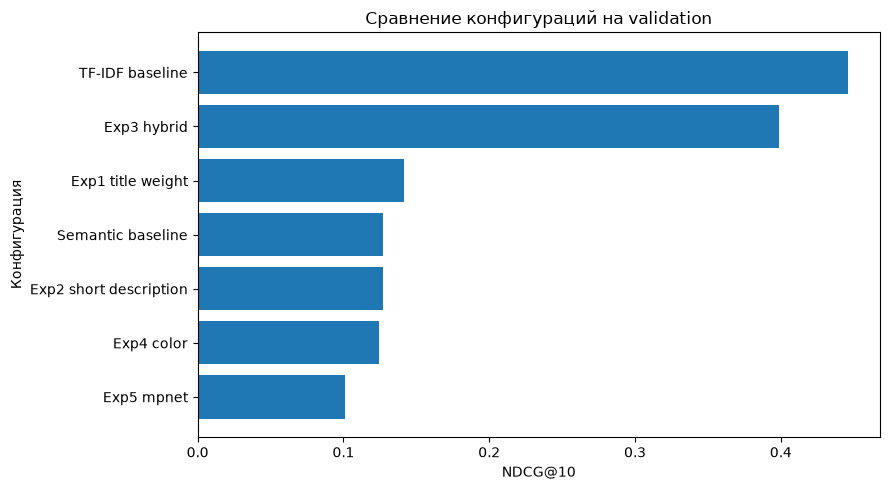

In [132]:
comparison_k10 = (
    validation_summary[
        validation_summary["K"] == 10
    ]
    .sort_values("NDCG", ascending=True)
)

plt.figure(figsize=(9, 5))

plt.barh(
    comparison_k10["model"],
    comparison_k10["NDCG"],
)

plt.xlabel("NDCG@10")
plt.ylabel("Конфигурация")
plt.title("Сравнение конфигураций на validation")

plt.tight_layout()

comparison_plot_path = "validation_ndcg_at_10.png"
plt.savefig(
    comparison_plot_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

In [133]:
experiment = mlflow.get_experiment_by_name(
    MLFLOW_EXPERIMENT_NAME
)

runs_df = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id]
)

run_names = [
    "semantic_baseline",
    "tfidf_baseline",
    "exp1_title_weight",
    "exp2_short_description",
    "exp3_hybrid",
    "exp4_color",
    "exp5_mpnet",
]

for run_name in run_names:
    run_row = runs_df[
        runs_df["tags.mlflow.runName"] == run_name
    ]

    if run_row.empty:
        print("Run не найден:", run_name)
        continue

    run_id = run_row.iloc[0]["run_id"]

    with mlflow.start_run(run_id=run_id):
        mlflow.log_artifact(
            comparison_plot_path,
            artifact_path="plots",
        )

    print("График сохранен:", run_name)

🏃 View run semantic_baseline at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/327bd2826c8041cf816eca4727f5d201
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
График сохранен: semantic_baseline
🏃 View run tfidf_baseline at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/c935e0b3a706450782fc464054c3b2c1
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
График сохранен: tfidf_baseline
🏃 View run exp1_title_weight at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1/runs/720ea45a749d470db517b6acbfe4c0f2
🧪 View experiment at: http://mlflow-ds-20260330-9ae2b4545d.infra.data-science.education-services.ru/#/experiments/1
График сохранен: exp1_title_weight
🏃 View run exp2_short_description at: http://mlflow-ds-202

In [134]:
if os.path.exists(comparison_plot_path):
    os.remove(comparison_plot_path)

### Результат трекинга

Все проверенные конфигурации сохранены в одном MLflow-эксперименте `semantic-search-project`, для каждой конфигурации создан отдельный run.

В MLflow зафиксированы параметры экспериментов, метрики на validation и артефакты для последующего анализа.

Проверка через `check_mlflow.py` успешно пройдена: эксперимент найден, все 7 прогонов имеют статус успешных, обязательные метрики и параметры присутствуют.

### 4. Финальные выводы

**4.1. Сводная таблица**

Все конфигурации сравнивались на одной и той же validation-выборке, при одинаковом пороге бинаризации `relevance >= 2` и одинаковых значениях `K = 1, 3, 5, 10`.

Основными метриками для выбора конфигурации были `NDCG@5` и `NDCG@10`.

| Конфигурация | NDCG@5 | NDCG@10 |
|---|---:|---:|
| Semantic baseline | 0.1092 | 0.1273 |
| TF-IDF baseline | **0.3569** | **0.4458** |
| Exp1 title weight | 0.1228 | 0.1416 |
| Exp2 short description | 0.1116 | 0.1273 |
| Exp3 hybrid | 0.3313 | 0.3991 |
| Exp4 color | 0.1118 | 0.1243 |
| Exp5 mpnet | 0.0939 | 0.1008 |

Лучшей конфигурацией на validation оказался **TF-IDF baseline**: `NDCG@5 = 0.3569`, `NDCG@10 = 0.4458`.

Гибридное ранжирование заняло второе место по NDCG, но не превзошло TF-IDF. Среди чисто семантических решений лучшим оказался Эксперимент 1 с усилением `imt_name`.

После выбора конфигурации был выполнен один финальный прогон на тестовой выборке. TF-IDF сохранил преимущество:

- `NDCG@5 = 0.3210`;
- `NDCG@10 = 0.4065`;
- `Recall@10 = 0.2852`;
- `Precision@10 = 0.0607`;
- `MRR@10 = 0.1210`;
- `HitRate@10 = 0.3800`.

Для сравнения, на тесте `NDCG@10` составил `0.1439` у Semantic baseline и `0.1557` у Semantic Exp1.

Таким образом, итоговый выбор не изменился: основной конфигурацией системы остается **TF-IDF baseline**.

**4.2. Качественный анализ**

Количественные результаты показывают, что TF-IDF лучше всего работает на текущей разметке, однако часть запросов все равно остается сложной.

Основные типы ошибок можно связать со следующими ситуациями:

- запрос и релевантный товар используют разные формулировки, синонимы или близкие по смыслу слова, поэтому буквальное совпадение токенов оказывается слабым;
- пользовательский запрос описывает назначение или свойства товара, которые выражены в карточке другими словами;
- запрос содержит несколько характеристик одновременно, а в названии и описании товара присутствует только часть из них;
- важный признак товара может отсутствовать в `product_text` или быть представлен в неструктурированном виде;
- при высокой лексической похожести TF-IDF может поднимать товары с совпадающими словами, но неподходящим смыслом.

Именно в подобных случаях семантический поиск потенциально может быть полезен. Это согласуется с результатами Эксперимента 1: усиление названия товара улучшило Semantic baseline по всем основным метрикам, хотя этого оказалось недостаточно, чтобы обойти TF-IDF.

Гибридный поиск также подтвердил, что лексические и семантические сигналы частично дополняют друг друга. Он уступил TF-IDF по `NDCG`, но показал высокие значения отдельных метрик, например `MRR` и `HitRate`.

**4.3. Ограничения оценки**

При интерпретации результатов необходимо учитывать ограничения данных и протокола оценки.

Разметка является синтетической и пулированной. Для пар `query-item`, отсутствующих в разметке, при расчете метрик используется relevance `0`. Поэтому среди найденных системой товаров могут присутствовать фактически релевантные позиции, которые просто не были размечены.

Тестовые и обучающие запросы также являются синтетическими, а не собранными из реального пользовательского поиска. Их распределение может отличаться от реальных запросов по длине, ошибкам, сокращениям, разговорным формулировкам и частоте использования конкретных атрибутов.

Оценка проводится на каталоге из `4 256` товаров, тогда как подготовленный рабочий каталог существенно больше. Поэтому полученные показатели качества и вычислительной стоимости нельзя напрямую переносить на полноценный production-каталог.

Для семантического baseline используется ограничение входа `128` токенов. Анализ данных показал, что часть карточек длиннее этого лимита, поэтому хвост длинных описаний обрезается и не участвует в построении эмбеддинга полностью.

В проекте не проводилось полноценное доменное дообучение эмбеддера. Проверялись готовые модели и изменения представления текста, поэтому потенциал обучаемого семантического подхода остается исследован не полностью.

Офлайн-метрики не отражают напрямую пользовательские и бизнес-метрики: кликабельность, конверсию, успешность поиска и удовлетворенность пользователя.

**4.4. Рекомендация бизнесу**

На текущем этапе не рекомендуется заменять существующий лексический поиск чистым векторным поиском.

В проведенных экспериментах TF-IDF значительно превосходит все семантические конфигурации по основным метрикам `NDCG@5` и `NDCG@10`. Это означает, что для текущих данных точное совпадение слов и формулировок остается очень сильным сигналом релевантности. Поэтому для MVP рекомендуется использовать TF-IDF как основной поисковый подход.

При этом от семантического поиска полностью отказываться не стоит. Он может быть полезен как дополнительный сигнал для запросов, где нет хорошего буквального совпадения: при перефразировании, использовании синонимов, описании назначения товара или других неточных формулировках.

Перспективным вариантом дальнейшего развития является гибридная архитектура, в которой лексический поиск остается основой, а семантический скор используется как дополнительный сигнал или для переранжирования части кандидатов.

Текущий вариант гибридного поиска с фиксированным весом `0.5` не превзошел TF-IDF по NDCG, поэтому внедрять именно эту конфигурацию без дальнейшей проверки не следует.

**4.5. Дальнейшие шаги**

В первую очередь стоит собрать реальные пользовательские запросы и поведенческие сигналы: клики, добавления в корзину, покупки и переформулировки запросов. Это позволит построить более репрезентативную выборку и оценивать поиск на реальном пользовательском поведении.

Следующим шагом можно расширить ручную разметку и увеличить число оцененных товаров для каждого запроса. Это снизит влияние пулированной разметки, при которой неразмеченные, но потенциально релевантные товары автоматически получают relevance `0`.

Для семантического поиска имеет смысл проверить доменное дообучение на парах "запрос - релевантный товар". Текущие результаты показывают, что простая замена готовой модели не гарантирует улучшения, поэтому более перспективным направлением может быть адаптация модели именно под данные маркетплейса.

Гибридный поиск также стоит развивать дальше: проверить другие веса объединения, RRF или двухэтапную схему, где TF-IDF формирует кандидатов, а семантическая модель выполняет переранжирование. Это позволит использовать сильные стороны обоих подходов.

Для товарных атрибутов полезно применять структурные фильтры отдельно от текстового ранжирования. Категория, цвет, размер, пол и другие характеристики могут использоваться как фильтры или дополнительные признаки, а не обязательно включаться непосредственно в общий текст карточки.

При росте каталога следует перейти от полного сравнения со всеми эмбеддингами к ANN-индексу. На этапе текущего MVP это не требуется, но для большого production-каталога позволит уменьшить время поиска.

После появления реальных логов следует дополнить офлайн-оценку онлайн-экспериментами и бизнес-метриками. Финальное решение о внедрении поисковой конфигурации желательно принимать не только по `NDCG`, `Recall` и `MRR`, но и по влиянию на клики, конверсию и успешность пользовательского поиска.

<div style="border:solid Chocolate 2px; padding: 40px">

**Общий вывод по проекту ревьювера v1**:

Юлия, спасибо за проект! Первые две недели выполнены очень основательно: каждое решение опирается на конкретное наблюдение в данных, а код аккуратный и снабжён проверками. Читать работу было приятно.

**Отмечу положительные моменты**:

1. Подробный и вдумчивый EDA: пропуски в виде пустых строк, выбор категорий по разметке, анализ релевантности с выводом про один товар с оценкой 3 на запрос.

2. Воспроизводимая подготовка данных: однозначное правило дедупликации со стабильной сортировкой и ассерты на каждом шаге.

3. Отличный разбор проблемы пулированной разметки: эксперимент с полным и сокращённым каталогом, где меняется ровно одна вещь, и дополнительная метрика числа размеченных товаров в топ-10.

4. Проверки собственного кода: сверка двух функций поиска, повторное кодирование эмбеддингов, тест функции метрик на игрушечном примере.

**На что стоит обратить внимание**:

1. Красный комментарий: проверить устойчивость результатов по K, разобрать запросы, где подходы расходятся, и сформулировать гипотезы для недели 3.

2. Жёлтые комментарии: проверка покрытия test, конкретный лимит длины входа модели и обоснование её выбора, переиспользование функции очистки, явный tie-break в поиске.

3. Пустые ячейки кода в конце второй недели лучше удалить.

4. Разделы третьей недели пока не заполнены - жду эксперименты, финальный прогон на test, MLflow и выводы для бизнеса.

**Удачи и жду твой проект на повторное ревью!**